# Stage 1 – AI Governance: Data Preparation, Analysis and Knowledge Graph Construction

## Introduction

This notebook presents the first stage of the CTL project, focusing on the analysis of a large-scale media dataset within the topic area of **AI Governance**.

The objective is to transform the raw dataset into a structured and reliable basis for further analysis and knowledge graph construction. The workflow includes systematic data inspection, cleaning and preprocessing, followed by exploratory analysis of relevant patterns, sources, topics and developments within the dataset.

The resulting cleaned and structured data will serve as the foundation for the identification of relevant entities and relationships and the subsequent construction of an AI Governance-focused knowledge graph.

## 1. Data Loading and Initial Inspection

The first step is to load the raw media dataset and examine its basic structure.  
Before applying any transformations, the dataset is inspected for its dimensions, available variables, data types, and general consistency.

In [1]:
from pathlib import Path
import pandas as pd
import ast

In [2]:
current_path = Path.cwd()

PROJECT_ROOT = next(
    path for path in [current_path, *current_path.parents]
    if (path / ".git").exists()
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai_media_dataset_20260911.csv"

# Output folders (see README for the complete folder structure)
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CORPUS_DIR = PROCESSED_DIR / "corpus"            # cleaned corpus and Governance subset definition
ENTITIES_DIR = PROCESSED_DIR / "entities"        # NER, co-occurrence and LLM relation extraction
TOPICS_DIR = PROCESSED_DIR / "topics"            # topic assignments and topic trends
KG_DIR = PROJECT_ROOT / "outputs" / "knowledge_graph"
MODELS_DIR = PROJECT_ROOT / "outputs" / "models" / "stage1"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures" / "stage1"

for directory in [CORPUS_DIR, ENTITIES_DIR, TOPICS_DIR, KG_DIR, MODELS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

In [3]:
import matplotlib.pyplot as plt


def save_figure(name):
    """Save the current figure as PNG in outputs/figures/stage1."""
    plt.savefig(
        FIGURES_DIR / f"{name}.png",
        dpi=150,
        bbox_inches="tight"
    )

In [4]:
path_summary = pd.DataFrame({
    "Item": [
        "Current working directory",
        "Project root",
        "Dataset path",
        "Dataset found"
    ],
    "Value": [
        str(current_path),
        str(PROJECT_ROOT),
        str(DATA_PATH),
        str(DATA_PATH.exists())
    ]
})

path_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Item", "Value"], **{"text-align": "left"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Item,Value
Current working directory,C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\notebooks\stage1_ai_governance
Project root,C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL
Dataset path,C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\raw\ai_media_dataset_20260911.csv
Dataset found,True


In [5]:
df = pd.read_csv(DATA_PATH)

In [6]:
dataset_overview = pd.DataFrame({
    "Metric": [
        "Number of records",
        "Number of columns"
    ],
    "Result": [
        len(df),
        df.shape[1]
    ]
})

dataset_overview.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Number of records,47751
Number of columns,7


In [7]:
column_overview = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

column_overview.style \
    .hide(axis="index") \
    .set_properties(subset=["Column", "Data Type"], **{"text-align": "left"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Column,Data Type
Unnamed: 0,int64
title,str
date,str
content,str
domain,str
url,str
tags,str


The raw dataset contains 47,751 records and 7 columns. The variables include an identifier-like field, article metadata, textual content, source domain, URL, and topic tags.

## 2. Data Quality Assessment

Before cleaning the dataset, the main data-quality dimensions are assessed.  
This includes missing values, identifier uniqueness, duplicate records, date consistency, and the structure of the `content` and `tags` fields.

In [8]:
quality_summary = pd.DataFrame({
    "Quality Check": [
        "Records",
        "Columns",
        "Missing values",
        "Duplicate IDs",
        "Duplicate URLs",
        "Duplicate titles",
        "Duplicate title-domain combinations",
        "Duplicate content"
    ],
    "Result": [
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df["Unnamed: 0"].duplicated().sum()),
        int(df["url"].duplicated().sum()),
        int(df["title"].duplicated().sum()),
        int(df.duplicated(subset=["title", "domain"]).sum()),
        int(df["content"].duplicated().sum())
    ]
})

quality_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Quality Check"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Quality Check,Result
Records,47751
Columns,7
Missing values,0
Duplicate IDs,0
Duplicate URLs,0
Duplicate titles,0
Duplicate title-domain combinations,0
Duplicate content,66


### Initial Findings

The dataset contains 47,751 records with no missing values in any column.

No duplicate identifiers, URLs, titles, or title-domain combinations were detected. However, 66 records contain article content that is identical to the content of another record. These cases require further inspection before deciding whether they represent true duplicates, syndicated articles, or legitimate records with different metadata.

### Identifier Inspection

The column `Unnamed: 0` appears to contain a record-level identifier. Before renaming or removing it, its uniqueness and value range are examined.

In [9]:
id_summary = pd.DataFrame({
    "Metric": [
        "Unique values",
        "Minimum value",
        "Maximum value",
        "Duplicate values"
    ],
    "Result": [
        int(df["Unnamed: 0"].nunique()),
        int(df["Unnamed: 0"].min()),
        int(df["Unnamed: 0"].max()),
        int(df["Unnamed: 0"].duplicated().sum())
    ]
})

id_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Unique values,47751
Minimum value,2
Maximum value,180480
Duplicate values,0


### Identifier Handling

The `Unnamed: 0` field contains 47,751 unique, non-sequential values and no duplicates. Since the field behaves like a record-level identifier, it is retained and renamed to `record_id` for clarity.

In [10]:
df_clean = df.copy()

df_clean = df_clean.rename(columns={
    "Unnamed: 0": "record_id"
})

column_summary = pd.DataFrame({
    "Column": df_clean.columns
})

column_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Column"], **{"text-align": "left"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Column
record_id
title
date
content
domain
url
tags


### Date Standardisation

The `date` field is currently stored as text in ISO format (`YYYY-MM-DD`). To support chronological analysis, the field is converted to a proper datetime type and checked for invalid values.

In [11]:
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    format="%Y-%m-%d",
    errors="coerce"
)

date_summary = pd.DataFrame({
    "Metric": [
        "Unparseable dates",
        "Minimum date",
        "Maximum date",
        "Unique dates"
    ],
    "Result": [
        int(df_clean["date"].isna().sum()),
        df_clean["date"].min().strftime("%Y-%m-%d"),
        df_clean["date"].max().strftime("%Y-%m-%d"),
        int(df_clean["date"].nunique())
    ]
})

date_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Unparseable dates,0
Minimum date,2024-09-11
Maximum date,2026-09-07
Unique dates,727


### Structured Text Fields

The `tags` and `content` fields are stored as string representations of lists. Before they can be used reliably for analysis, they are converted into actual Python lists while preserving their existing structure.

In [12]:
def ensure_list(value):
    if isinstance(value, list):
        return value
    if isinstance(value, str):
        return ast.literal_eval(value)
    return value


df_clean["tags"] = df_clean["tags"].apply(ensure_list)
df_clean["content"] = df_clean["content"].apply(ensure_list)

structure_summary = pd.DataFrame({
    "Field": [
        "tags",
        "content"
    ],
    "Total Rows": [
        len(df_clean),
        len(df_clean)
    ],
    "Valid Python Lists": [
        int(df_clean["tags"].apply(lambda x: isinstance(x, list)).sum()),
        int(df_clean["content"].apply(lambda x: isinstance(x, list)).sum())
    ]
})

structure_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Field"], **{"text-align": "left"}) \
    .set_properties(
        subset=["Total Rows", "Valid Python Lists"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Field,Total Rows,Valid Python Lists
tags,47751,47751
content,47751,47751


### Duplicate Content Inspection

The initial quality assessment identified 66 duplicate content occurrences. These records are examined in more detail before any rows are removed, since identical article text may represent duplicated records, syndicated content, or legitimate articles published with different metadata.

In [13]:
duplicate_mask = df["content"].duplicated(keep=False)

duplicate_content_records = df.loc[
    duplicate_mask,
    ["Unnamed: 0", "title", "date", "domain", "url", "content"]
].copy()

duplicate_summary = pd.DataFrame({
    "Metric": [
        "Duplicate occurrences",
        "Total records involved",
        "Unique duplicated content groups"
    ],
    "Result": [
        int(df["content"].duplicated().sum()),
        len(duplicate_content_records),
        duplicate_content_records["content"].nunique()
    ]
})

duplicate_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Duplicate occurrences,66
Total records involved,127
Unique duplicated content groups,61


#### Duplicate Group Sizes

To better understand the duplicate content, the number of records within each duplicated content group is examined. This helps distinguish simple duplicate pairs from content that occurs repeatedly across several records.

In [14]:
duplicate_group_sizes = (
    duplicate_content_records
    .groupby("content")
    .size()
    .value_counts()
    .sort_index()
    .reset_index()
)

duplicate_group_sizes.columns = [
    "Records per Content Group",
    "Number of Groups"
]

duplicate_group_sizes.style \
    .hide(axis="index") \
    .set_properties(
        subset=["Records per Content Group", "Number of Groups"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Records per Content Group,Number of Groups
2,57
3,3
4,1


Most duplicated content occurs only twice: 57 of the 61 duplicate groups contain two records, while three groups contain three records and one group contains four records.

The metadata of these groups is therefore examined next to determine whether identical content appears under different titles, sources, dates, or URLs.

In [15]:
duplicate_metadata = (
    duplicate_content_records
    .groupby("content")
    .agg(
        Records=("content", "size"),
        Unique_Titles=("title", "nunique"),
        Unique_Domains=("domain", "nunique"),
        Unique_Dates=("date", "nunique"),
        Unique_URLs=("url", "nunique")
    )
)

metadata_summary = pd.DataFrame({
    "Check": [
        "Groups with different titles",
        "Groups with different domains",
        "Groups with different dates",
        "Groups with different URLs"
    ],
    "Number of Groups": [
        int((duplicate_metadata["Unique_Titles"] > 1).sum()),
        int((duplicate_metadata["Unique_Domains"] > 1).sum()),
        int((duplicate_metadata["Unique_Dates"] > 1).sum()),
        int((duplicate_metadata["Unique_URLs"] > 1).sum())
    ]
})

metadata_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Check"], **{"text-align": "left"}) \
    .set_properties(subset=["Number of Groups"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Check,Number of Groups
Groups with different titles,61
Groups with different domains,1
Groups with different dates,35
Groups with different URLs,61


In [16]:
df_clean["content_text"] = df_clean["content"].apply(
    lambda parts: " ".join(str(part).strip() for part in parts)
)

content_summary = pd.DataFrame({
    "Metric": [
        "Records",
        "Empty content texts",
        "Average text length (characters)"
    ],
    "Result": [
        len(df_clean),
        int((df_clean["content_text"].str.strip() == "").sum()),
        round(df_clean["content_text"].str.len().mean())
    ]
})

content_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Records,47751
Empty content texts,0
Average text length (characters),10616


In [17]:
tag_summary = pd.DataFrame({
    "Metric": [
        "Records",
        "Records without tags",
        "Average tags per record",
        "Maximum tags in one record",
        "Unique tags"
    ],
    "Result": [
        len(df_clean),
        int(df_clean["tags"].apply(len).eq(0).sum()),
        round(df_clean["tags"].apply(len).mean(), 2),
        int(df_clean["tags"].apply(len).max()),
        len(set(tag for tags in df_clean["tags"] for tag in tags))
    ]
})

tag_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Records,47751.000000
Records without tags,0.000000
Average tags per record,5.230000
Maximum tags in one record,86.000000
Unique tags,1311.000000


### Duplicate Handling Decision

The duplicate-content analysis shows that identical article text frequently occurs with different titles, URLs, and publication dates. The records are therefore not removed at this point.

Because encoding repair and text normalization can make further article texts identical, the final duplicate handling is performed after text cleaning, based on the cleaned article text (see *Removal of Duplicate Content* below).

In [18]:
cleaning_status = pd.DataFrame({
    "Check": [
        "Records retained",
        "Columns after preprocessing",
        "Missing values",
        "Unique record IDs",
        "Unparseable dates",
        "Valid tag lists",
        "Valid content lists",
        "Empty content_text values"
    ],
    "Result": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.isna().sum().sum()),
        int(df_clean["record_id"].nunique()),
        int(df_clean["date"].isna().sum()),
        int(df_clean["tags"].apply(lambda x: isinstance(x, list)).sum()),
        int(df_clean["content"].apply(lambda x: isinstance(x, list)).sum()),
        int((df_clean["content_text"].str.strip() == "").sum())
    ]
})

cleaning_status.style \
    .hide(axis="index") \
    .set_properties(subset=["Check"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Check,Result
Records retained,47751
Columns after preprocessing,8
Missing values,0
Unique record IDs,47751
Unparseable dates,0
Valid tag lists,47751
Valid content lists,47751
Empty content_text values,0


### Systematic Encoding Inspection

The initial encoding check identified several common mojibake patterns. Since a predefined list may not capture all malformed characters, the textual data is examined more systematically for unusual Unicode characters and recurring encoding artefacts before any replacements are applied.

In [19]:
from collections import Counter

text_columns = ["title", "content_text"]

all_text = " ".join(
    df_clean[column].astype(str).str.cat(sep=" ")
    for column in text_columns
)

non_ascii_characters = Counter(
    char for char in all_text
    if ord(char) > 127
)

character_summary = pd.DataFrame(
    non_ascii_characters.most_common(),
    columns=["Character", "Occurrences"]
)

character_summary.head(50).style \
    .hide(axis="index") \
    .set_properties(subset=["Character"], **{"text-align": "left"}) \
    .set_properties(subset=["Occurrences"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Character,Occurrences
’,763835
“,287254
”,283242
—,197587
–,65165
â,45218
,44092
‘,20884
,20430
é,19591


#### Character Classification and Context Validation

The detected non-ASCII characters are divided into three categories before cleaning:

1. **Likely encoding artefacts:** characters strongly associated with malformed text encoding.
2. **Language-specific characters:** valid characters from other languages that require contextual validation because the dataset is predominantly English.
3. **Valid punctuation, symbols, and formatting characters:** typographic or technical characters that may legitimately occur in normal text.

For each detected character, three examples are extracted from the dataset to validate its use in context before any cleaning rule is applied.

In [20]:
import unicodedata

character_categories = {
    # 1 — Likely mojibake / encoding corruption
    "â": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "Â": "1 - Likely encoding error",

    # 2 — Valid language characters, but require context in an English dataset
    "é": "2 - Language-specific / inspect",
    "ó": "2 - Language-specific / inspect",
    "á": "2 - Language-specific / inspect",
    "í": "2 - Language-specific / inspect",
    "ü": "2 - Language-specific / inspect",
    "ä": "2 - Language-specific / inspect",
    "ö": "2 - Language-specific / inspect",
    "ç": "2 - Language-specific / inspect",
    "ã": "2 - Language-specific / inspect",
    "ú": "2 - Language-specific / inspect",
    "ñ": "2 - Language-specific / inspect",
    "à": "2 - Language-specific / inspect",
    "è": "2 - Language-specific / inspect",
    "ß": "2 - Language-specific / inspect",
    "ê": "2 - Language-specific / inspect",
    "õ": "2 - Language-specific / inspect",
    "¿": "2 - Language-specific / inspect",
    "이": "2 - Language-specific / inspect",
    "다": "2 - Language-specific / inspect",

    # 3 — Normal punctuation / symbols / formatting
    "’": "3 - Punctuation / symbol / formatting",
    "‘": "3 - Punctuation / symbol / formatting",
    "“": "3 - Punctuation / symbol / formatting",
    "”": "3 - Punctuation / symbol / formatting",
    "—": "3 - Punctuation / symbol / formatting",
    "–": "3 - Punctuation / symbol / formatting",
    "…": "3 - Punctuation / symbol / formatting",
    "-": "3 - Punctuation / symbol / formatting",
    "©": "3 - Punctuation / symbol / formatting",
    "•": "3 - Punctuation / symbol / formatting",
    "€": "3 - Punctuation / symbol / formatting",
    "£": "3 - Punctuation / symbol / formatting",
    "®": "3 - Punctuation / symbol / formatting",
    "→": "3 - Punctuation / symbol / formatting",
    "™": "3 - Punctuation / symbol / formatting",
    "×": "3 - Punctuation / symbol / formatting",
    "·": "3 - Punctuation / symbol / formatting",
    "°": "3 - Punctuation / symbol / formatting",
    "─": "3 - Punctuation / symbol / formatting",

    # Invisible formatting characters
    "\u200b": "3 - Punctuation / symbol / formatting",
    "\u200c": "3 - Punctuation / symbol / formatting",
    "\u200d": "3 - Punctuation / symbol / formatting",
    "\ufeff": "3 - Punctuation / symbol / formatting",
    "\u00ad": "3 - Punctuation / symbol / formatting"
}

In [21]:
def character_label(character):
    category = unicodedata.category(character)

    # Make invisible/control characters visible in the output
    if category.startswith("C"):
        return f"U+{ord(character):04X}"
    
    return character


def get_context(text, character, window=70):
    text = str(text)
    position = text.find(character)

    if position == -1:
        return None

    start = max(0, position - window)
    end = min(len(text), position + len(character) + window)

    return text[start:end]


character_examples = []

for character, category in character_categories.items():

    examples = []

    for column in ["title", "content_text"]:

        mask = df_clean[column].astype(str).str.contains(
            character,
            regex=False,
            na=False
        )

        matching_rows = df_clean.loc[
            mask,
            ["record_id", column]
        ]

        for _, row in matching_rows.iterrows():

            context = get_context(
                row[column],
                character
            )

            examples.append(
                f"[{row['record_id']} | {column}] {context}"
            )

            if len(examples) == 3:
                break

        if len(examples) == 3:
            break

    count = non_ascii_characters.get(character, 0)

    character_examples.append({
        "Category": category,
        "Character": character_label(character),
        "Unicode Name": unicodedata.name(character, "UNKNOWN"),
        "Occurrences": count,
        "Example 1": examples[0] if len(examples) > 0 else "",
        "Example 2": examples[1] if len(examples) > 1 else "",
        "Example 3": examples[2] if len(examples) > 2 else ""
    })


character_examples_df = pd.DataFrame(character_examples)

character_examples_df = character_examples_df.sort_values(
    ["Category", "Occurrences"],
    ascending=[True, False]
)

character_examples_df.style \
    .hide(axis="index") \
    .set_properties(
        subset=[
            "Category",
            "Character",
            "Unicode Name",
            "Example 1",
            "Example 2",
            "Example 3"
        ],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Category,Character,Unicode Name,Occurrences,Example 1,Example 2,Example 3
1 - Likely encoding error,â,LATIN SMALL LETTER A WITH CIRCUMFLEX,45218,[128500 | title] US approves sale of Nvidia chips to UAEâs G42,[132078 | title] Quantum sensingâs potential: Insights for leaders,[110290 | title] KPMG KymChat â changing the game with Trusted AI
1 - Likely encoding error,U+0080,UNKNOWN,44092,[128500 | title] US approves sale of Nvidia chips to UAEâs G42,[132078 | title] Quantum sensingâs potential: Insights for leaders,[110290 | title] KPMG KymChat â changing the game with Trusted AI
1 - Likely encoding error,U+0099,UNKNOWN,20430,[128500 | title] US approves sale of Nvidia chips to UAEâs G42,[132078 | title] Quantum sensingâs potential: Insights for leaders,[122692 | title] Julian Assange Says Heâs Still Getting Used to the âSpooky Sound of Electric Carsâ
1 - Likely encoding error,U+009C,UNKNOWN,7645,[132120 | title] Stanfordâs Marietje Schaake on âThe Tech Coupâ,[132172 | title] Zeta CEO is building a banking tech âomnistackâ,[55055 | title] Cluely AI: The Controversial Startup Redefining âCheatingâ with $ 5.3M in Funding
1 - Likely encoding error,U+009D,UNKNOWN,7570,[132120 | title] Stanfordâs Marietje Schaake on âThe Tech Coupâ,[132172 | title] Zeta CEO is building a banking tech âomnistackâ,[55055 | title] Cluely AI: The Controversial Startup Redefining âCheatingâ with $ 5.3M in Funding
1 - Likely encoding error,U+0094,UNKNOWN,6173,[64630 | title] How AlphaChip transformed computer chip design â Google DeepMind,[122702 | title] Youth Sports Were Already IntenseâNow AI Tools Are Supercharging the Competition,[122860 | title] Live Updates From CES 2025 in Las Vegas ð´
1 - Likely encoding error,Â,LATIN CAPITAL LETTER A WITH CIRCUMFLEX,4088,[122870 | title] ogy Is Supposed to Decrease Teacher BurnoutâIt Can Sometimes Make ItÂ Worse,[122986 | title] OGE Threat: How Government Data Would Give an AI Company ExtraordinaryÂ Power,[123942 | title] Deepfakes Leveled up in 2025âHereâs Whatâs ComingÂ Next
2 - Language-specific / inspect,é,LATIN SMALL LETTER E WITH ACUTE,19591,[82694 | title] De nouvelles fonctionnalités et plus de contrôle pour vos campagnes optimisées par l'IA,[39297 | title] AtkinsRéalis Virtual Site Access: solving the nuclear challenge,"[82808 | title] Le Pixel Feature Drop d'octobre est là! De nouvelles fonctionnalités et mises à jour pour les smartphones Pixel, la Pixel Watch et la Pix"
2 - Language-specific / inspect,ó,LATIN SMALL LETTER O WITH ACUTE,16241,"[22862 | title] AiThority Interview with Adolfo Hernández, Telefónica at IBM",[82721 | title] Google Cloud denuncia ante la Comisión Europea las prácticas anticompetitivas de Microsoft respecto a las l,[82772 | title] Cómo afrontan las nuevas amenazas estos fundadores de ciberseguridad
2 - Language-specific / inspect,á,LATIN SMALL LETTER A WITH ACUTE,13385,[82677 | title] Empresas de energía más sostenibles y seguras gracias a las tecnologías de nube y la IA,[82668 | title] Privacidad de datos más sencilla para anunciantes con confidential matching,"[22862 | title] AiThority Interview with Adolfo Hernández, Telefónica at IBM"


In [22]:
confirmed_encoding_errors = {
    "â": "Mojibake marker",
    "\u0080": "Encoding control character",
    "\u0099": "Encoding control character",
    "\u009c": "Encoding control character",
    "\u009d": "Encoding control character",
    "\u0094": "Encoding control character",
    "Â": "Mojibake marker",
}

confirmed_formatting_artifacts = {
    "\u200b": "Zero-width space",
    "\ufeff": "Zero-width no-break space / BOM",
    "\u00ad": "Soft hyphen",
}

#### Malformed Encoding Sequences

After separating valid multilingual characters from potential encoding artefacts, the analysis now focuses on complete malformed character sequences rather than individual symbols.

This is important because characters such as `â`, `Ã`, `Â`, or control characters often form part of a larger mojibake sequence. The complete sequence and its surrounding context are required to determine the intended character and define a safe correction rule.

In [23]:
import re
from collections import Counter, defaultdict

# Common structures created when UTF-8 text is decoded incorrectly.
# The patterns deliberately look for combinations rather than isolated
# characters, so legitimate letters such as French "â" are not
# automatically classified as errors.

mojibake_pattern = re.compile(
    r"(?:"
    r"â[\u0080-\u00BF]{1,2}"      # e.g. â â â
    r"|Ã[\u0080-\u00BF]"          # e.g. broken accented letters
    r"|Â(?:[\u0080-\u00BF]|\s)"   # e.g. Â°, Â + space
    r"|ð[\u0080-\u00BF]{2,3}"     # e.g. broken emoji sequences
    r")"
)

sequence_counts = Counter()
sequence_examples = defaultdict(list)

for row in df_clean[["record_id", "title", "content_text"]].itertuples(index=False):

    for field, text in [
        ("title", str(row.title)),
        ("content_text", str(row.content_text))
    ]:

        for match in mojibake_pattern.finditer(text):
            sequence = match.group()

            sequence_counts[sequence] += 1

            # Store maximum 3 examples per malformed sequence
            if len(sequence_examples[sequence]) < 3:
                start = max(0, match.start() - 70)
                end = min(len(text), match.end() + 70)

                sequence_examples[sequence].append(
                    f"[{row.record_id} | {field}] {text[start:end]}"
                )


sequence_rows = []

for sequence, count in sequence_counts.most_common():

    examples = sequence_examples[sequence]

    sequence_rows.append({
        "Broken Sequence": repr(sequence),
        "Code Points": " ".join(
            f"U+{ord(char):04X}" for char in sequence
        ),
        "Occurrences": count,
        "Example 1": examples[0] if len(examples) > 0 else "",
        "Example 2": examples[1] if len(examples) > 1 else "",
        "Example 3": examples[2] if len(examples) > 2 else ""
    })


malformed_sequences = pd.DataFrame(sequence_rows)

malformed_sequences.style \
    .hide(axis="index") \
    .set_properties(
        subset=[
            "Broken Sequence",
            "Code Points",
            "Example 1",
            "Example 2",
            "Example 3"
        ],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])


Broken Sequence,Code Points,Occurrences,Example 1,Example 2,Example 3
'â\x80\x99',U+00E2 U+0080 U+0099,20393,"[132070 | content_text] ctivity and innovation for the global enterprises they serve. Today weâre taking a closer look at how that change is being achieved, with a f","[132070 | content_text] ow that change is being achieved, with a focus on two areas. First youâll hear from McKinsey partner Abhilash Sridharan, discussing the talen","[132070 | content_text] ner Abhilash Sridharan, discussing the talent supply chain at GCCs. Heâs joined by Debasis Panda, head of GCCs for TransUnion, and Pravin Goe"
'â\x80\x9c',U+00E2 U+0080 U+009C,7595,[132070 | content_text] nt headquarters for the enterprise can aim to follow what we call the â10/30/50 approach.â What it means is 10 percent of the leaders for t,"[132070 | content_text] now, is building core skills. A lot of GCCs today call themselves the âmicrocosm of the firm, â but quite honestly, many of them are like d","[132070 | content_text] with you. Pravin Goel: Yes, I think the one-word answer in my mind is âculture.â We need to create a work environment that is more about in"
'â\x80\x9d',U+00E2 U+0080 U+009D,7535,[132070 | content_text] he enterprise can aim to follow what we call the â10/30/50 approach.â What it means is 10 percent of the leaders for the enterprise come fr,"[132070 | content_text] ls. A lot of GCCs today call themselves the âmicrocosm of the firm, â but quite honestly, many of them are like doughnuts. They are hollow","[132070 | content_text] ravin Goel: Yes, I think the one-word answer in my mind is âculture.â We need to create a work environment that is more about interactions"
'â\x80\x94',U+00E2 U+0080 U+0094,6138,[132070 | content_text] n terms of the impact it could have on how the business itself changesâand the leadership opportunity around it. Iâd call out four or five,"[132070 | content_text] , and thatâs what weâre building right now. So thatâs number oneâproduct. Clearly, itâd be remiss not to talk about generative AI ( g","[132070 | content_text] skills, especially with respect to transition risk and sustainabilityâand also in business transformation. For example, weâre building ski"
'Â ',U+00C2 U+0020,3380,"[132070 | content_text] t Daphne Luchtenberg is joined by McKinsey partners Abhilash SridharanÂ and Malcolm Gomes, Debasis Panda of TransUnion, and Pravin Goel of Bla","[132070 | content_text] from job-based recruitment to hiring on a skill-based way of thinkingÂ so that you are deploying your associates for a specific skill, not fo",[132070 | content_text] a unique opportunity to innovate on how we engage the next-gen talentÂ and meet them where they are. And thatâs one on the campuses. The ot
'â\x80\x93',U+00E2 U+0080 U+0093,734,"[132077 | content_text] in the energy system mean emissions could continue rising through 2025â35. Emissions have not yet peaked, and global CO2 emissions from combu",[132076 | content_text] ell below the long-term overall US average of about 2.2 percent ( 1947â2019). To close the labor shortage in manufacturing through productivi,"[132078 | content_text] industryâconsider the 14.8 billion ( and rising) Internet of Thingsâconnected devices around the globe.2Allan Jay, âNumber of Internet o"
'â\x80¦',U+00E2 U+0080 U+00A6,568,"[128508 | content_text] is worth it âfor your kids, ââ she says. âBut itâs not thatâ¦ Itâs not like sheâs the free gift that justifies the purchase.â","[128508 | content_text] elf six times running, she will conclude that I personally dislike herâ¦ Therefore I am compelled to do the simple thing, and when you say, â","[128508 | content_text] For instance, a reasonable mood for a foreign policy hawk âis sorrowâ¦ We are in a tragic situation [ and ] we have to kill many thousands o"
'â\x80\x98',U+00E2 U+0080 U+0098,410,"[132069 | content_text] ams should work and where they should focus, speaking directly on the â

#### Automatic Repair Mapping

Most detected malformed sequences result from UTF-8 encoded text being decoded incorrectly. Where the original character can be reconstructed unambiguously, an automatic repair candidate is generated.

Sequences that cannot be decoded reliably are retained for manual inspection rather than modified automatically.

In [24]:
def propose_encoding_repair(sequence):
    # Try common encodings used in mojibake
    for encoding in ["latin1", "cp1252"]:
        try:
            repaired = sequence.encode(encoding).decode("utf-8")

            if repaired != sequence:
                return repaired

        except (UnicodeEncodeError, UnicodeDecodeError):
            continue

    # Known spacing artefact
    if sequence == "Â ":
        return " "

    return None


repair_candidates = []

for sequence, count in sequence_counts.most_common():
    
    repaired = propose_encoding_repair(sequence)

    # Special case identified clearly in the dataset:
    # "Â " represents an unwanted encoding artefact before a space.
    if sequence == "Â ":
        repaired = " "

    repair_candidates.append({
        "Broken Sequence": repr(sequence),
        "Occurrences": count,
        "Proposed Repair": repr(repaired) if repaired is not None else "",
        "Status": (
            "Automatic repair candidate"
            if repaired is not None
            else "Manual review"
        )
    })


repair_mapping_df = pd.DataFrame(repair_candidates)

repair_mapping_df.style \
    .hide(axis="index") \
    .set_properties(
        subset=["Broken Sequence", "Proposed Repair", "Status"],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Broken Sequence,Occurrences,Proposed Repair,Status
'â\x80\x99',20393,'’',Automatic repair candidate
'â\x80\x9c',7595,'“',Automatic repair candidate
'â\x80\x9d',7535,'”',Automatic repair candidate
'â\x80\x94',6138,'—',Automatic repair candidate
'Â ',3380,' ',Automatic repair candidate
'â\x80\x93',734,'–',Automatic repair candidate
'â\x80¦',568,'…',Automatic repair candidate
'â\x80\x98',410,'‘',Automatic repair candidate
'Â©',327,'©',Automatic repair candidate
'â\x80¯',203,'\u202f',Automatic repair candidate


#### Manual Review of Unresolved Encoding Sequences

Most malformed sequences can be reconstructed automatically. A small number of incomplete byte sequences cannot be decoded unambiguously and are therefore inspected manually before any correction is applied.

In [25]:
manual_sequences = [
    sequence
    for sequence, count in sequence_counts.most_common()
    if propose_encoding_repair(sequence) is None
]

manual_review_rows = []

for sequence in manual_sequences:
    examples = sequence_examples[sequence]

    manual_review_rows.append({
        "Broken Sequence": repr(sequence),
        "Occurrences": sequence_counts[sequence],
        "Example 1": examples[0] if len(examples) > 0 else "",
        "Example 2": examples[1] if len(examples) > 1 else "",
        "Example 3": examples[2] if len(examples) > 2 else ""
    })

manual_review_df = pd.DataFrame(manual_review_rows)

manual_review_df.style \
    .hide(axis="index") \
    .set_properties(
        subset=["Broken Sequence", "Example 1", "Example 2", "Example 3"],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Broken Sequence,Occurrences,Example 1,Example 2,Example 3
'â\x84',6,"[172282 | content_text] Neo4jÂ®, Neo TechnologyÂ®, CypherÂ®, Neo4jÂ® Bloomâ¢, Neo4jÂ® AuraDBâ and Neo4jÂ® AuraDSâ are registered trademarks of Neo4j, Inc. All oth","[172282 | content_text] ogyÂ®, CypherÂ®, Neo4jÂ® Bloomâ¢, Neo4jÂ® AuraDBâ and Neo4jÂ® AuraDSâ are registered trademarks of Neo4j, Inc. All other marks are owned by","[172283 | content_text] Neo4jÂ®, Neo TechnologyÂ®, CypherÂ®, Neo4jÂ® Bloomâ¢, Neo4jÂ® AuraDBâ and Neo4jÂ® AuraDSâ are registered trademarks of Neo4j, Inc. All oth"
'â\x9a',4,[122703 | content_text] A âdata collectionâ plane flight pattern through Hurricane Milton â ï¸ pic.twitter.com/vCKlxDlBa3 While Wallace didn’ t directly say he,"[113172 | content_text]  Wrong document retrieval: Debug chunking strategy, retrieval method.â ï¸ Hallucination risk: Add stronger grounding in retrieval or prompt","[105165 | content_text] ill be removed in Windows updates, planned for release in April 2026. â ï¸ Important: Editing the registry incorrectly can cause system issu"
'â\x9c',4,[104627 | content_text] the Version drop-down list. Learn more about navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft,[104627 | content_text] wn list. Learn more about navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft Sentinel Kusto Quer,[104627 | content_text] ut navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft Sentinel Kusto Query Language ( KQL) has b
'â\x8b',2,"[66935 | content_text] , which govern the motion of fluids. The equations are as follows: ââ v = 0 ( continuity equation) âv/ât + vâ âv = -1/Ï âp + Î½ â",[66935 | content_text] tions are as follows: ââ v = 0 ( continuity equation) âv/ât + vâ âv = -1/Ï âp + Î½ âÂ²v ( Navier-Stokes equation) where v is th,
'â¬',1,[150577 | content_text] nd I just snorted with laughter. In a good way. Watch the whole thing â¬‡ï¸ pic.twitter.com/vSOMzXdwZo The update also adds new voices. Short,,
'ð\x9f\x87',1,[128526 | content_text] by 12 years. It will increase its lease liabilities by $ 1.2 billion. ð « ð· ð²ð¦ Morocco fertilizer giant OCP and French energy firm E,,
'â\x89',1,"[104174 | content_text] rio where different classes contain different noise levels, i.e. psbr â pnsbr. We systematically increment psbr and pnsbr independently by 0.",,
'â\x88',1,"[88150 | content_text] put channels are related. where f and g are input signals, t is time, â « signifies an integral over time ( with Ï as the dummy variable of",,
'ð\x9f\x93',1,"[124627 | content_text] BTC Output: 223.1 BTCð¹ BTC Sold: 223.1 BTCð¹ Net BTC Added: 0 BTCð Data as of July 3, 2026. # Bitcoin # BTC # BitcoinHoldings # BitcoinC",,


### Encoding Repair

Confirmed mojibake patterns are repaired automatically while preserving valid multilingual text. Corrections are only accepted when they reduce the number of suspicious encoding artefacts in the affected text.

The repaired dataset is validated again afterwards, and any remaining unresolved cases are reviewed separately.

In [26]:
suspicious_markers = [
    "â", "Ã", "Â", "ð",
    "\x80", "\x81", "\x82", "\x83", "\x84",
    "\x85", "\x86", "\x87", "\x88", "\x89",
    "\x8a", "\x8b", "\x8c", "\x8d", "\x8e",
    "\x8f", "\x90", "\x91", "\x92", "\x93",
    "\x94", "\x95", "\x96", "\x97", "\x98",
    "\x99", "\x9a", "\x9b", "\x9c", "\x9d",
    "\x9e", "\x9f"
]


def suspicious_score(text):
    return sum(text.count(marker) for marker in suspicious_markers)


def repair_mojibake(text):
    if not isinstance(text, str):
        return text

    original = text
    best = original
    best_score = suspicious_score(original)

    # Only try decoding if the text actually looks suspicious
    if best_score == 0:
        return original

    for encoding in ["latin1", "cp1252"]:
        try:
            candidate = original.encode(encoding).decode("utf-8")
            candidate_score = suspicious_score(candidate)

            # Accept only if the repair clearly reduces suspicious artefacts
            if candidate_score < best_score:
                best = candidate
                best_score = candidate_score

        except (UnicodeEncodeError, UnicodeDecodeError):
            pass

    return best

In [27]:
df_repaired = df_clean.copy()

# Repair titles
df_repaired["title"] = df_repaired["title"].apply(repair_mojibake)

# Repair every text segment while preserving the content list structure
df_repaired["content"] = df_repaired["content"].apply(
    lambda parts: [repair_mojibake(part) for part in parts]
)

# Rebuild continuous text from repaired content
df_repaired["content_text"] = df_repaired["content"].apply(
    lambda parts: " ".join(str(part).strip() for part in parts)
)

In [28]:
repair_summary = pd.DataFrame({
    "Metric": [
        "Titles changed",
        "Content records changed",
        "Records retained"
    ],
    "Result": [
        int((df_clean["title"] != df_repaired["title"]).sum()),
        int((df_clean["content_text"] != df_repaired["content_text"]).sum()),
        len(df_repaired)
    ]
})

repair_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Titles changed,320
Content records changed,1349
Records retained,47751


#### Validation of Encoding Repair

The automatic repair modified 320 titles and 1,349 content records while retaining all 47,751 records.

The repaired text is now compared with the original text to verify that suspicious encoding artefacts have been reduced before the repaired dataset is adopted.

In [29]:
encoding_validation = pd.DataFrame({
    "Dataset": [
        "Before repair",
        "After repair"
    ],
    "Suspicious markers": [
        int(
            df_clean["title"].apply(suspicious_score).sum()
            + df_clean["content_text"].apply(suspicious_score).sum()
        ),
        int(
            df_repaired["title"].apply(suspicious_score).sum()
            + df_repaired["content_text"].apply(suspicious_score).sum()
        )
    ]
})

encoding_validation.style \
    .hide(axis="index") \
    .set_properties(subset=["Dataset"], **{"text-align": "left"}) \
    .set_properties(subset=["Suspicious markers"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Dataset,Suspicious markers
Before repair,139355
After repair,21392


In [30]:
def count_malformed_sequences(text):
    if not isinstance(text, str):
        return 0

    return len(mojibake_pattern.findall(text))


actual_encoding_validation = pd.DataFrame({
    "Dataset": [
        "Before repair",
        "After repair"
    ],
    "Malformed sequences": [
        int(
            df_clean["title"].apply(count_malformed_sequences).sum()
            + df_clean["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired["title"].apply(count_malformed_sequences).sum()
            + df_repaired["content_text"].apply(count_malformed_sequences).sum()
        )
    ]
})

actual_encoding_validation.style \
    .hide(axis="index") \
    .set_properties(subset=["Dataset"], **{"text-align": "left"}) \
    .set_properties(subset=["Malformed sequences"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Dataset,Malformed sequences
Before repair,49305
After repair,8992


#### Sequence-Level Encoding Repair

The initial repair substantially reduced the number of malformed sequences, but some artefacts remained because entire text fields can contain a mixture of valid Unicode and corrupted substrings.

A second repair pass therefore operates on the confirmed malformed sequences individually. This allows corrupted substrings to be corrected without modifying valid multilingual text elsewhere in the same record.

In [31]:
# Build a mapping containing only confidently decoded malformed sequences
automatic_repair_mapping = {}

for sequence in sequence_counts:
    repaired = propose_encoding_repair(sequence)

    if repaired is not None:
        automatic_repair_mapping[sequence] = repaired


# Replace longer sequences first to avoid partial replacements
ordered_repairs = sorted(
    automatic_repair_mapping.items(),
    key=lambda item: len(item[0]),
    reverse=True
)


def repair_sequences(text):
    if not isinstance(text, str):
        return text

    repaired_text = text

    for broken, repaired in ordered_repairs:
        repaired_text = repaired_text.replace(broken, repaired)

    return repaired_text

In [32]:
df_repaired_v2 = df_clean.copy()

df_repaired_v2["title"] = (
    df_repaired_v2["title"]
    .apply(repair_sequences)
)

df_repaired_v2["content"] = (
    df_repaired_v2["content"]
    .apply(
        lambda parts: [
            repair_sequences(part)
            for part in parts
        ]
    )
)

df_repaired_v2["content_text"] = (
    df_repaired_v2["content"]
    .apply(
        lambda parts: " ".join(
            str(part).strip()
            for part in parts
        )
    )
)

In [33]:
sequence_repair_validation = pd.DataFrame({
    "Dataset": [
        "Before repair",
        "After whole-text repair",
        "After sequence-level repair"
    ],
    "Malformed sequences": [
        int(
            df_clean["title"].apply(count_malformed_sequences).sum()
            + df_clean["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired["title"].apply(count_malformed_sequences).sum()
            + df_repaired["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired_v2["title"].apply(count_malformed_sequences).sum()
            + df_repaired_v2["content_text"].apply(count_malformed_sequences).sum()
        )
    ]
})

sequence_repair_validation.style \
    .hide(axis="index") \
    .set_properties(subset=["Dataset"], **{"text-align": "left"}) \
    .set_properties(subset=["Malformed sequences"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Dataset,Malformed sequences
Before repair,49305
After whole-text repair,8992
After sequence-level repair,630


#### Residual Encoding Artefacts

The sequence-level repair reduced the number of detected malformed sequences from 49,305 to 630. The remaining cases are inspected separately to determine whether they represent unresolved encoding errors, double-encoded characters, or legitimate text that should be preserved.

In [34]:
residual_counts = Counter()
residual_examples = defaultdict(list)

for row in df_repaired_v2[
    ["record_id", "title", "content_text"]
].itertuples(index=False):

    for field, text in [
        ("title", str(row.title)),
        ("content_text", str(row.content_text))
    ]:

        for match in mojibake_pattern.finditer(text):

            sequence = match.group()
            residual_counts[sequence] += 1

            if len(residual_examples[sequence]) < 3:

                start = max(0, match.start() - 70)
                end = min(len(text), match.end() + 70)

                residual_examples[sequence].append(
                    f"[{row.record_id} | {field}] "
                    f"{text[start:end]}"
                )

In [35]:
residual_rows = []

for sequence, count in residual_counts.most_common():

    examples = residual_examples[sequence]

    residual_rows.append({
        "Remaining Sequence": repr(sequence),
        "Occurrences": count,
        "Proposed Repair": (
            repr(propose_encoding_repair(sequence))
            if propose_encoding_repair(sequence) is not None
            else ""
        ),
        "Example 1": examples[0] if len(examples) > 0 else "",
        "Example 2": examples[1] if len(examples) > 1 else "",
        "Example 3": examples[2] if len(examples) > 2 else ""
    })


residual_encoding_df = pd.DataFrame(residual_rows)

residual_encoding_df.style \
    .hide(axis="index") \
    .set_properties(
        subset=[
            "Remaining Sequence",
            "Proposed Repair",
            "Example 1",
            "Example 2",
            "Example 3"
        ],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Remaining Sequence,Occurrences,Proposed Repair,Example 1,Example 2,Example 3
'Â ',605,' ',"[132072 | content_text] rbon emissions ( Scopes 1 and 2), which it expects to achieve by 2040.Â Ventas used an innovative approach to generate net-zero road maps for","[122673 | content_text] least heftier than the current and surprisingly popular Meta Ray-Bans.Â On September 17, Ray-Bans owner EssilorLuxottica declared they would c","[122679 | content_text] ll still have all the same software capabilities as its older brother.Â It will still support the Quest 3’s full game and app library, and an"
'â\x84',6,,"[172282 | content_text] Sitemap Neo4j®, Neo Technology®, Cypher®, Neo4j® Bloom™, Neo4j® AuraDBâ and Neo4j® AuraDSâ are registered trademarks of Neo4j, Inc. All othe","[172282 | content_text] Technology®, Cypher®, Neo4j® Bloom™, Neo4j® AuraDBâ and Neo4j® AuraDSâ are registered trademarks of Neo4j, Inc. All other marks are owned by","[172283 | content_text] Sitemap Neo4j®, Neo Technology®, Cypher®, Neo4j® Bloom™, Neo4j® AuraDBâ and Neo4j® AuraDSâ are registered trademarks of Neo4j, Inc. All othe"
'â\x9a',4,,[122703 | content_text] NOAA “data collection” plane flight pattern through Hurricane Milton â ï¸ pic.twitter.com/vCKlxDlBa3 While Wallace didn’ t directly say he,"[113172 | content_text] 🔍 Wrong document retrieval: Debug chunking strategy, retrieval method.â ï¸ Hallucination risk: Add stronger grounding in retrieval or prompt","[105165 | content_text] ill be removed in Windows updates, planned for release in April 2026. â ï¸ Important: Editing the registry incorrectly can cause system issu"
'â\x9c',4,,[104627 | content_text] the Version drop-down list. Learn more about navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft,[104627 | content_text] wn list. Learn more about navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft Sentinel Kusto Quer,[104627 | content_text] ut navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft Sentinel Kusto Query Language ( KQL) has b
'Â®',4,'®',[105146 | content_text] penAI chat extension. Parameters to use when configuring ElasticsearchÂ® as an Azure OpenAI chat extension. Optional settings to control how f,[105146 | content_text] control how fields are processed when using a configured ElasticsearchÂ® resource. The type of ElasticsearchÂ® retrieval query that should be,[105146 | content_text] using a configured ElasticsearchÂ® resource. The type of ElasticsearchÂ® retrieval query that should be executed when using it as an Azure Ope
'â\x8b',2,,"[66935 | content_text] ns, which govern the motion of fluids. The equations are as follows: ∇â v = 0 ( continuity equation) ∂v/∂t + vâ ∇v = -1/Ï ∇p + Î½ ∇²v ( Nav",[66935 | content_text] e equations are as follows: ∇â v = 0 ( continuity equation) ∂v/∂t + vâ ∇v = -1/Ï ∇p + Î½ ∇²v ( Navier-Stokes equation) where v is the fluid,
'â¬',1,,[150577 | content_text] nd I just snorted with laughter. In a good way. Watch the whole thing â¬‡ï¸ pic.twitter.com/vSOMzXdwZo The update also adds new voices. Short,,
'ð\x9f\x87',1,,[128526 | content_text] by 12 years. It will increase its lease liabilities by $ 1.2 billion. ð « 🇷 🇲🇦 Morocco fertilizer giant OCP and French energy firm Engie sign,,
'â\x89',1,,"[104174 | content_text] rio where different classes contain different noise levels, i.e. psbr â pnsbr. We systematically increment psbr and pnsbr independently by 0.",,
'â\x88',1,,"[88150 | content_text] put channels are related. where f and g are input signals, t is time, â « signifies an integral over time ( with Ï as the dummy variable of",,


In [36]:
import re

def repair_residual_encoding(text):
    if not isinstance(text, str):
        return text

    # Remove stray U+00C2 ("Â") when it appears directly before whitespace
    text = re.sub(r"\u00C2(?=\s)", "", text)

    # Remove stray U+00C2 before ®
    text = text.replace("\u00C2\u00AE", "\u00AE")

    return text

In [37]:
df_repaired_final = df_repaired_v2.copy()

df_repaired_final["title"] = (
    df_repaired_final["title"]
    .apply(repair_residual_encoding)
)

df_repaired_final["content"] = (
    df_repaired_final["content"]
    .apply(
        lambda parts: [
            repair_residual_encoding(part)
            for part in parts
        ]
    )
)

df_repaired_final["content_text"] = (
    df_repaired_final["content"]
    .apply(
        lambda parts: " ".join(
            str(part).strip()
            for part in parts
        )
    )
)

In [38]:
check_residuals = pd.DataFrame({
    "Check": [
        "Â + whitespace before",
        "Â + whitespace after",
        "Â® before",
        "Â® after"
    ],
    "Occurrences": [
        int(df_repaired_v2["content_text"].str.count(r"\u00C2(?=\s)").sum()),
        int(df_repaired_final["content_text"].str.count(r"\u00C2(?=\s)").sum()),
        int(df_repaired_v2["content_text"].str.count("\u00C2\u00AE").sum()),
        int(df_repaired_final["content_text"].str.count("\u00C2\u00AE").sum())
    ]
})

check_residuals

,Check,Occurrences
0,Â + whitespace before,605
1,Â + whitespace after,605
2,Â® before,4
3,Â® after,0


In [39]:
def repair_residual_encoding(text):
    if not isinstance(text, str):
        return text

    # Remove stray Â before whitespace OR at the end of a text segment
    text = re.sub(r"\u00C2(?=\s|$)", "", text)

    # Repair Â® → ®
    text = text.replace("\u00C2\u00AE", "\u00AE")

    return text

In [40]:
df_repaired_final = df_repaired_v2.copy()

df_repaired_final["title"] = (
    df_repaired_final["title"]
    .apply(repair_residual_encoding)
)

df_repaired_final["content"] = (
    df_repaired_final["content"]
    .apply(
        lambda parts: [
            repair_residual_encoding(part)
            for part in parts
        ]
    )
)

df_repaired_final["content_text"] = (
    df_repaired_final["content"]
    .apply(
        lambda parts: " ".join(
            str(part).strip()
            for part in parts
        )
    )
)

In [41]:
print(
    "Remaining Â + whitespace:",
    int(
        df_repaired_final["content_text"]
        .str.count(r"\u00C2(?=\s)")
        .sum()
    )
)

Remaining Â + whitespace: 0


In [42]:
final_check = pd.DataFrame({
    "Dataset": [
        "Before repair",
        "After sequence-level repair",
        "After final residual repair"
    ],
    "Malformed sequences": [
        int(
            df_clean["title"].apply(count_malformed_sequences).sum()
            + df_clean["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired_v2["title"].apply(count_malformed_sequences).sum()
            + df_repaired_v2["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired_final["title"].apply(count_malformed_sequences).sum()
            + df_repaired_final["content_text"].apply(count_malformed_sequences).sum()
        )
    ]
})

final_check.style \
    .hide(axis="index") \
    .set_properties(subset=["Dataset"], **{"text-align": "left"}) \
    .set_properties(
        subset=["Malformed sequences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Dataset,Malformed sequences
Before repair,49305
After sequence-level repair,630
After final residual repair,21


In [43]:
remaining_manual_sequences = [
    sequence
    for sequence in residual_counts
    if propose_encoding_repair(sequence) is None
]


def has_remaining_encoding_issue(text):
    if not isinstance(text, str):
        return False

    return any(
        sequence in text
        for sequence in remaining_manual_sequences
    )


df_repaired_final["unresolved_encoding"] = (
    df_repaired_final["title"].apply(has_remaining_encoding_issue)
    | df_repaired_final["content_text"].apply(has_remaining_encoding_issue)
)


encoding_flag_summary = pd.DataFrame({
    "Metric": [
        "Records",
        "Records with unresolved encoding issue",
        "Records without unresolved encoding issue"
    ],
    "Result": [
        len(df_repaired_final),
        int(df_repaired_final["unresolved_encoding"].sum()),
        int((~df_repaired_final["unresolved_encoding"]).sum())
    ]
})

encoding_flag_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Records,47751
Records with unresolved encoding issue,14
Records without unresolved encoding issue,47737


### Encoding Cleaning Summary

The encoding inspection initially identified **49,305 malformed character sequences** in the textual data. Most issues were typical mojibake artefacts caused by incorrectly decoded UTF-8 text, including corrupted quotation marks and apostrophes, accented characters, punctuation, symbols, emojis, and stray characters such as `Â`.

A combination of automatic sequence-level repair and targeted residual corrections was applied. In total, **49,284 malformed sequences were successfully corrected** while preserving all **47,751 records**.

After cleaning, only **21 unresolved encoding fragments remain across 14 records**. These records were retained because the remaining issues are minor and the surrounding information is otherwise valid.

No records were removed during the encoding-cleaning process.

In [44]:
df_clean = df_repaired_final.copy()

In [45]:
encoding_final_summary = pd.DataFrame({
    "Metric": [
        "Records after encoding cleaning",
        "Malformed sequences before repair",
        "Malformed sequences remaining",
        "Records with unresolved encoding",
        "Records removed"
    ],
    "Result": [
        len(df_clean),
        49305,
        21,
        int(df_clean["unresolved_encoding"].sum()),
        0
    ]
})

encoding_final_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Records after encoding cleaning,47751
Malformed sequences before repair,49305
Malformed sequences remaining,21
Records with unresolved encoding,14
Records removed,0


### Text Normalization

Following the encoding repair, the textual fields are examined for recurring formatting inconsistencies that may affect downstream analysis.

Only clear and systematic formatting artefacts are normalized in order to avoid altering valid multilingual or linguistic content.

#### High-Confidence Text Normalization

The contextual inspection shows that several detected spacing patterns originate from systematic formatting artefacts, while others can also represent valid linguistic constructions.

Therefore, normalization is restricted to high-confidence cases:

- repeated spaces and repeated horizontal whitespace are collapsed to a single space;
- spaces immediately after opening parentheses are removed;
- spaces immediately before closing parentheses are removed;
- empty content segments are excluded when reconstructing continuous article text.

More ambiguous linguistic patterns are intentionally preserved. Apostrophe formatting is handled separately in a targeted step using only high-confidence contraction and elision patterns.

In [46]:
import re

def normalize_text(text):
    if not isinstance(text, str):
        return text

    # Collapse repeated horizontal whitespace
    text = re.sub(r"[ \t]{2,}", " ", text)

    # Remove whitespace directly inside parentheses
    text = re.sub(r"\(\s+", "(", text)
    text = re.sub(r"\s+\)", ")", text)

    return text


# Define formatting issues for before/after validation
checks = {
    "Multiple spaces": r" {2,}",
    "Space after opening parenthesis": r"\(\s+",
    "Space before closing parenthesis": r"\s+\)"
}

# Count issues before normalization
before_counts = {}

for name, pattern in checks.items():
    before_counts[name] = int(
        df_clean["title"].astype(str).str.count(pattern).sum()
        + df_clean["content_text"].astype(str).str.count(pattern).sum()
    )


# Normalize titles
df_clean["title"] = df_clean["title"].apply(normalize_text)

# Normalize individual content segments and remove empty segments
df_clean["content"] = df_clean["content"].apply(
    lambda parts: [
        normalize_text(str(part).strip())
        for part in parts
        if str(part).strip()
    ]
)

# Rebuild continuous article text
df_clean["content_text"] = df_clean["content"].apply(
    lambda parts: " ".join(parts)
)

# Normalize again after joining to remove artefacts
# created across segment boundaries
df_clean["content_text"] = (
    df_clean["content_text"]
    .apply(normalize_text)
)


# Count issues after normalization
validation_rows = []

for name, pattern in checks.items():

    after = int(
        df_clean["title"].astype(str).str.count(pattern).sum()
        + df_clean["content_text"].astype(str).str.count(pattern).sum()
    )

    validation_rows.append({
        "Issue": name,
        "Before": before_counts[name],
        "After": after
    })


normalization_validation = pd.DataFrame(validation_rows)

display(
    normalization_validation.style
    .hide(axis="index")
    .set_properties(subset=["Issue"], **{"text-align": "left"})
    .set_properties(
        subset=["Before", "After"],
        **{"text-align": "right"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Issue,Before,After
Multiple spaces,4329,0
Space after opening parenthesis,307272,0
Space before closing parenthesis,15,0


#### Targeted Apostrophe Normalization

A small number of systematic apostrophe-spacing artefacts remained after the general text normalization.

These cases are handled separately using targeted rules for common English contractions and possessives, common French/European elisions, and clearly malformed doubled apostrophes.

More ambiguous apostrophe usage is intentionally preserved to avoid altering valid linguistic constructions.

In [47]:
def normalize_apostrophes(text):
    if not isinstance(text, str):
        return text

    # English contractions / possessives:
    # it’ s -> it’s, I’ ve -> I’ve, don’ t -> don’t
    text = re.sub(
        r"(?<=[A-Za-z])[’']\s+(?=(?:s|t|re|ve|ll|d|m)\b)",
        lambda m: m.group(0)[0],
        text
    )

    # Common French / European elisions:
    # l’ ère -> l’ère, d’ informations -> d’informations
    text = re.sub(
        r"\b([cdjlmnst]|qu)([’'])\s+(?=[A-Za-zÀ-ÖØ-öø-ÿ])",
        r"\1\2",
        text,
        flags=re.IGNORECASE
    )

    # Clearly malformed doubled apostrophe:
    # Parkinson '' s -> Parkinson's
    text = re.sub(
        r"\s+''\s+s\b",
        "'s",
        text
    )

    return text


# Apply targeted apostrophe normalization
df_clean["title"] = (
    df_clean["title"]
    .apply(normalize_apostrophes)
)

df_clean["content"] = (
    df_clean["content"]
    .apply(
        lambda parts: [
            normalize_apostrophes(part)
            for part in parts
        ]
    )
)

# Rebuild content_text
df_clean["content_text"] = (
    df_clean["content"]
    .apply(
        lambda parts: " ".join(
            str(part).strip()
            for part in parts
            if str(part).strip()
        )
    )
)

#### Text Normalization Summary

Text normalization was restricted to clearly identifiable formatting artefacts in order to preserve valid multilingual content.

Repeated whitespace and unnecessary spaces inside parentheses were removed, empty content segments were excluded when reconstructing continuous article text, and selected high-confidence apostrophe-spacing artefacts were corrected.

After normalization, no repeated spaces, spaces after opening parentheses, or spaces before closing parentheses remained. More ambiguous linguistic and punctuation patterns were intentionally preserved.

### Removal of Duplicate Content

After encoding repair and text normalization, the duplicate-content check is repeated on the cleaned `content_text`.

Inspection of the duplicate groups shows that they consist of long, identical article texts (at least 5,000 characters) that almost always originate from the same source. They represent repeated captures or republications of the same article, sometimes with a shortened title or a later publication date (for example records 64238 and 64242). Keeping them would count the same article several times in the temporal analysis, the entity frequencies and the co-occurrence weights of the Knowledge Graph.

Therefore, only the earliest publication of each article text is retained (earliest date, then lowest `record_id`).

In [48]:
# Records before duplicate removal
records_before_deduplication = len(df_clean)

# Order records by first publication so that the earliest version is kept
first_publication_order = (
    df_clean
    .sort_values(["date", "record_id"])
    .index
)

is_duplicate_content = (
    df_clean.loc[first_publication_order, "content_text"]
    .duplicated(keep="first")
)

duplicate_records = df_clean.loc[
    is_duplicate_content[is_duplicate_content].index
]

# Characterize the affected duplicate groups before removal
duplicate_groups = (
    df_clean
    .loc[df_clean["content_text"].isin(duplicate_records["content_text"])]
    .groupby("content_text")
    .agg(
        Records=("record_id", "size"),
        Domains=("domain", "nunique"),
        Dates=("date", "nunique")
    )
)

duplicate_content_removed = len(duplicate_records)

df_clean = (
    df_clean
    .drop(index=duplicate_records.index)
    .reset_index(drop=True)
)

deduplication_summary = pd.DataFrame({
    "Metric": [
        "Records before duplicate removal",
        "Duplicate content groups",
        "Groups from a single source",
        "Groups with identical source and date",
        "Duplicate records removed",
        "Records after duplicate removal"
    ],
    "Result": [
        records_before_deduplication,
        len(duplicate_groups),
        int((duplicate_groups["Domains"] == 1).sum()),
        int(
            (
                (duplicate_groups["Domains"] == 1)
                & (duplicate_groups["Dates"] == 1)
            ).sum()
        ),
        duplicate_content_removed,
        len(df_clean)
    ]
})

display(
    deduplication_summary.style
    .hide(axis="index")
    .set_properties(subset=["Metric"], **{"text-align": "left"})
    .set_properties(subset=["Result"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Metric,Result
Records before duplicate removal,47751
Duplicate content groups,67
Groups from a single source,65
Groups with identical source and date,29
Duplicate records removed,72
Records after duplicate removal,47679


## Data Cleaning and Normalization Summary

The raw dataset was systematically inspected and prepared for subsequent exploratory analysis and knowledge graph construction.

The preprocessing included structural validation, duplicate assessment, date standardization, conversion of serialized text fields, encoding repair, and conservative text normalization.

Key outcomes of the cleaning process include:

- 72 duplicate-content records were removed, leaving 47,679 records;
- no missing values were identified;
- no duplicate identifiers or URLs were found; 24 duplicate-title occurrences remain after text normalization and duplicate removal; these articles differ in content and were retained;
- 66 duplicate-content occurrences were identified in the raw text; after cleaning, 72 records repeated the text of an earlier record (67 groups, 65 of them from a single source) and were removed, keeping the earliest publication of each text;
- the identifier field was renamed to `record_id`;
- all dates were successfully standardized;
- `tags` and `content` were converted into structured Python lists;
- a continuous `content_text` field was created from the article-content segments;
- 49,305 malformed encoding sequences were initially detected;
- 49,284 of these sequences were successfully repaired;
- 21 unresolved encoding fragments remain across 14 records and were retained rather than modified based on uncertain assumptions;
- repeated whitespace and unnecessary spacing inside parentheses were removed;
- empty content segments were excluded when reconstructing continuous article text;
- selected high-confidence apostrophe-spacing artefacts were corrected.

The final dataset therefore contains 47,679 unique article texts and substantially improves structural consistency and textual quality for downstream analysis.

In [49]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Final records",
        "Missing values",
        "Duplicate IDs",
        "Duplicate URLs",
        "Duplicate titles",
        "Duplicate content records removed",
        "Malformed encoding sequences before repair",
        "Malformed encoding sequences remaining",
        "Records with unresolved encoding",
        "Records removed"
    ],
    "Result": [
        len(df_clean),
        int(df_clean.isna().sum().sum()),
        int(df_clean["record_id"].duplicated().sum()),
        int(df_clean["url"].duplicated().sum()),
        int(df_clean["title"].duplicated().sum()),
        duplicate_content_removed,
        49305,
        21,
        int(df_clean["unresolved_encoding"].sum()),
        records_before_deduplication - len(df_clean)
    ]
})

display(
    cleaning_summary.style
    .hide(axis="index")
    .set_properties(subset=["Metric"], **{"text-align": "left"})
    .set_properties(subset=["Result"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Metric,Result
Final records,47679
Missing values,0
Duplicate IDs,0
Duplicate URLs,0
Duplicate titles,24
Duplicate content records removed,72
Malformed encoding sequences before repair,49305
Malformed encoding sequences remaining,21
Records with unresolved encoding,14
Records removed,72


## 3. Exploratory Data Analysis

Following data cleaning and normalization, the dataset is explored to identify its main structural and thematic characteristics.

The analysis focuses on the temporal distribution of articles, source coverage, topic tags, and recurring themes. These patterns provide the basis for narrowing the dataset toward the AI Governance focus and for defining relevant entities and relationships for the subsequent knowledge graph.

In [50]:
eda_overview = pd.DataFrame({
    "Metric": [
        "Records",
        "Unique sources",
        "Earliest publication date",
        "Latest publication date",
        "Unique tags",
        "Average tags per article"
    ],
    "Result": [
        len(df_clean),
        df_clean["domain"].nunique(),
        df_clean["date"].min().date(),
        df_clean["date"].max().date(),
        len(set(
            tag
            for tags in df_clean["tags"]
            for tag in tags
        )),
        round(
            df_clean["tags"].apply(len).mean(),
            2
        )
    ]
})

display(
    eda_overview.style
    .hide(axis="index")
    .set_properties(subset=["Metric"], **{"text-align": "left"})
    .set_properties(subset=["Result"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Metric,Result
Records,47679
Unique sources,392
Earliest publication date,2024-09-11
Latest publication date,2026-09-07
Unique tags,1311
Average tags per article,5.230000


In [51]:
articles_per_month = (
    df_clean
    .set_index("date")
    .resample("ME")
    .size()
    .reset_index(name="Articles")
)

articles_per_month.head()

,date,Articles
0,2024-09-30,975
1,2024-10-31,2125
2,2024-11-30,1740
3,2024-12-31,1456
4,2025-01-31,2447


### Temporal Distribution

The distribution of articles over time is examined to identify changes in dataset coverage and periods with particularly high or low publication activity.

Articles are aggregated by month to provide a clear overview of the temporal development across the observation period.

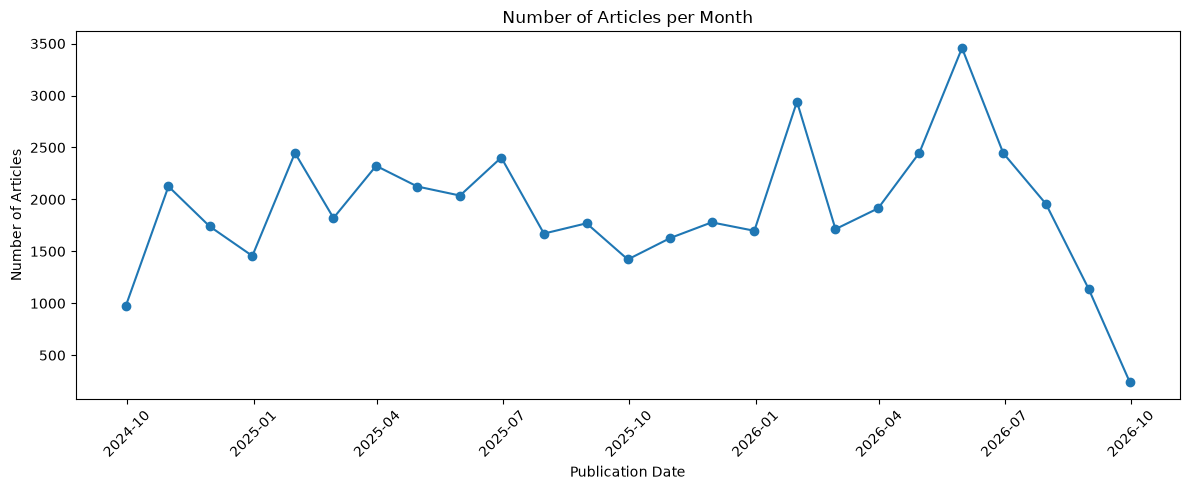

In [52]:
import matplotlib.pyplot as plt

articles_per_month = (
    df_clean
    .set_index("date")
    .resample("ME")
    .size()
    .reset_index(name="Articles")
)

plt.figure(figsize=(12, 5))

plt.plot(
    articles_per_month["date"],
    articles_per_month["Articles"],
    marker="o"
)

plt.title("Number of Articles per Month")
plt.xlabel("Publication Date")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.tight_layout()
save_figure("articles_per_month")
plt.show()

### Source Distribution

The dataset contains articles from a broad range of sources. The most frequently represented domains are examined to assess whether the dataset is dominated by a small number of publishers or provides relatively diverse source coverage.

In [53]:
top_sources = (
    df_clean["domain"]
    .value_counts()
    .head(15)
    .reset_index()
)

top_sources.columns = ["Source", "Articles"]

display(
    top_sources.style
    .hide(axis="index")
    .set_properties(subset=["Source"], **{"text-align": "left"})
    .set_properties(subset=["Articles"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Source,Articles
builtin,1661
aijourn,1626
apnews,1253
thenewstack,1176
dev,1138
marketbeat,1096
skyquestt,966
cnbc,833
crn,802
theconversation,800


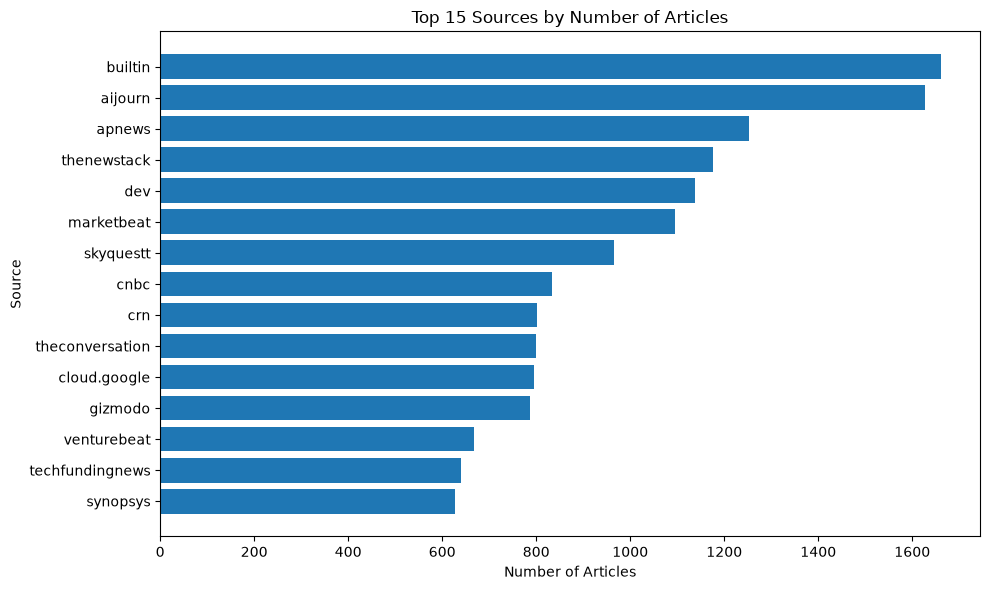

In [54]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_sources["Source"][::-1],
    top_sources["Articles"][::-1]
)

plt.title("Top 15 Sources by Number of Articles")
plt.xlabel("Number of Articles")
plt.ylabel("Source")

plt.tight_layout()
save_figure("top_sources")
plt.show()

#### EDA Findings: Temporal and Source Coverage

The dataset shows substantial variation in monthly article volume across the observation period. Publication activity generally remains above 1,400 articles per month, with particularly high volumes in early and mid-2026.

The comparatively low values at the beginning and end of the time series should be interpreted cautiously because September 2024 and September 2026 represent only partial months in the dataset.

Source coverage is relatively diverse, with 392 unique domains. The largest contributors are `builtin` and `aijourn`, followed by sources such as `apnews`, `thenewstack`, and `dev`. The 15 most frequent sources account for approximately 31% of all records, indicating that although several publishers contribute substantially, the dataset is not dominated by only a small number of sources.

### Tag Distribution

The dataset contains 1,311 unique tags, with an average of approximately 5.23 tags per article. Tag frequencies are examined to identify the most prominent topics represented in the dataset and to provide an initial view of the thematic structure before focusing specifically on AI Governance.

In [55]:
from collections import Counter

tag_counts = Counter(
    tag
    for tags in df_clean["tags"]
    for tag in tags
)

top_tags = pd.DataFrame(
    tag_counts.most_common(20),
    columns=["Tag", "Articles"]
)

display(
    top_tags.style
    .hide(axis="index")
    .set_properties(subset=["Tag"], **{"text-align": "left"})
    .set_properties(subset=["Articles"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Tag,Articles
Video,9357
GenerativeAI,8600
Planning,8538
MilitaryAndDefense,7447
Personalisation,7091
OpenAI,6960
Accountability,6688
ConversationalAI,6283
LargeLanguageModel,6252
Robotics,6169


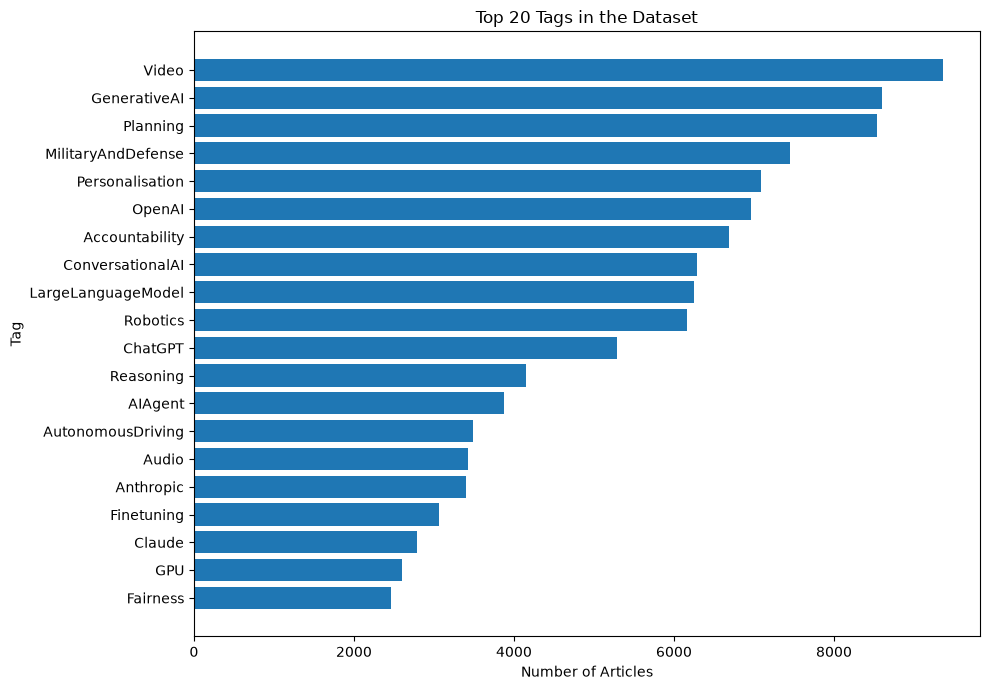

In [56]:
plt.figure(figsize=(10, 7))

plt.barh(
    top_tags["Tag"][::-1],
    top_tags["Articles"][::-1]
)

plt.title("Top 20 Tags in the Dataset")
plt.xlabel("Number of Articles")
plt.ylabel("Tag")

plt.tight_layout()
save_figure("top_tags")
plt.show()

#### EDA Findings: Tag Distribution

The tag distribution shows that the dataset covers a broad range of technical, organizational, and societal AI topics. Frequently occurring tags include `GenerativeAI`, `Planning`, `OpenAI`, `LargeLanguageModel`, and `Robotics`.

Importantly for the AI Governance focus, `Accountability` is among the most frequent tags with 6,688 associated articles, while `Fairness` appears in 2,458 articles and is also among the 20 most frequent tags.

However, the absence of other governance themes from the top 20 does not imply that they are poorly represented. Related concepts may occur under more specific tags. Therefore, the complete tag vocabulary is examined for terms related to the four governance dimensions: Security, Accountability, Bias/Fairness, and Regulation.

### AI Governance Tag Exploration

To define the AI Governance subset systematically, the complete tag vocabulary of 1,311 unique tags is reviewed.

Each tag is assessed for its relevance to the four selected governance dimensions: Security, Accountability, Bias/Fairness, and Regulation. Only tags that clearly represent one of these dimensions are included in the final mapping, while ambiguous technical terms, company names, products, and application areas are excluded as standalone Governance indicators.

In [57]:
all_tags_df = (
    pd.DataFrame(
        tag_counts.items(),
        columns=["Tag", "Articles"]
    )
    .sort_values("Articles", ascending=False)
    .reset_index(drop=True)
)

print(f"Unique tags reviewed: {len(all_tags_df):,}")

display(all_tags_df.head(50))

Unique tags reviewed: 1,311


,Tag,Articles
0,Video,9357
1,GenerativeAI,8600
2,Planning,8538
3,MilitaryAndDefense,7447
4,Personalisation,7091
5,OpenAI,6960
6,Accountability,6688
7,ConversationalAI,6283
8,LargeLanguageModel,6252
9,Robotics,6169


#### EDA Findings: Governance Tag Exploration

The complete vocabulary of 1,311 tags was reviewed before defining the final AI Governance mapping.

This review confirmed that several tags are clearly related to Security, Accountability, Bias/Fairness, or Regulation, while others are ambiguous or refer to companies, products, technical methods, or application areas rather than Governance itself.

For example, `ProximalPolicyOptimization` is a reinforcement-learning method and `WeightsAndBiases` is a company/product name, so neither is treated as a Governance indicator.

The final mapping therefore uses a curated set of tags that are sufficiently specific to the four Governance dimensions.

#### Final Governance Theme Definition

The complete vocabulary of 1,311 tags was manually reviewed to identify tags that clearly represent one of the four AI Governance dimensions.

Company names, product names, generic technical concepts, and application areas were excluded when they were not sufficiently specific to AI Governance on their own.

The final mapping contains 30 Governance-relevant tags grouped into Security, Accountability, Bias/Fairness, and Regulation. The mapping is deliberately conservative to reduce false-positive classification.

In [58]:
governance_tag_mapping = {
    "Security": [
        "Surveillance",
        "Disinformation",
        "Deepfake",
        "AISafety",
        "RedTeaming",
        "AdversarialMachineLearning",
        "InternationalSecurity",
        "Propaganda",
        "FakeNews",
        "BiologicalThreat",
        "Bioterrorism",
        "AITRiSM"
    ],

    "Accountability": [
        "Accountability",
        "EthicalAI",
        "ExplainableAI",
        "ResponsibleAI",
        "TrustworthyAI",
        "ModelCard",
        "DataCard",
        "MechanisticInterpretability",
        "SHAP",
        "HITL",
        "HOTL",
        "HumanInTheLoop"
    ],

    "Bias / Fairness": [
        "Fairness",
        "AlgorithmicBias"
    ],

    "Regulation": [
        "AIAct",
        "AIPolicy",
        "Legal",
        "SocialScoring"
    ]
}

#### Documentation of the Tag Review

To keep the Governance mapping traceable outside the notebook, the complete tag vocabulary is exported together with the final review decision for every tag: whether it is included in the Governance subset, the assigned Governance theme, and review notes for tags that were explicitly discussed during the review.


In [59]:
# Map every Governance tag to its theme
tag_to_theme = {
    tag: theme
    for theme, theme_tags in governance_tag_mapping.items()
    for tag in theme_tags
}

# Every mapped tag must exist in the dataset vocabulary
missing_mapped_tags = sorted(set(tag_to_theme) - set(tag_counts))

if missing_mapped_tags:
    raise ValueError(
        f"Mapped tags not found in the dataset: {missing_mapped_tags}"
    )

# Notes for tags that were explicitly discussed during the review
review_notes = {
    "ProximalPolicyOptimization": "Excluded: reinforcement-learning method, not a Governance indicator",
    "WeightsAndBiases": "Excluded: company/product name, not a Governance indicator"
}

tag_review_df = all_tags_df.copy()

tag_review_df["Include in Governance"] = (
    tag_review_df["Tag"]
    .isin(tag_to_theme)
    .map({True: "Yes", False: "No"})
)

tag_review_df["Governance Theme"] = (
    tag_review_df["Tag"]
    .map(tag_to_theme)
    .fillna("")
)

tag_review_df["Review Notes"] = (
    tag_review_df["Tag"]
    .map(review_notes)
    .fillna("")
)

EXPORT_PATH = (
    CORPUS_DIR / "AI_Governance_All_Tags_Review.xlsx"
)

tag_review_df.to_excel(
    EXPORT_PATH,
    index=False
)

print(f"Tags reviewed: {len(tag_review_df):,}")
print(f"Tags included in Governance: {(tag_review_df['Include in Governance'] == 'Yes').sum():,}")
print(f"Tag review saved to: {EXPORT_PATH}")

display(
    tag_review_df
    .loc[tag_review_df["Include in Governance"] == "Yes"]
    .sort_values(["Governance Theme", "Articles"], ascending=[True, False])
)


Tags reviewed: 1,311
Tags included in Governance: 30
Tag review saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\processed\corpus\AI_Governance_All_Tags_Review.xlsx


,Tag,Articles,Include in Governance,Governance Theme,Review Notes
6,Accountability,6688,Yes,Accountability,
58,HITL,866,Yes,Accountability,
157,EthicalAI,248,Yes,Accountability,
226,ModelCard,148,Yes,Accountability,
381,ExplainableAI,52,Yes,Accountability,
412,SHAP,44,Yes,Accountability,
423,MechanisticInterpretability,42,Yes,Accountability,
539,ResponsibleAI,23,Yes,Accountability,
549,HOTL,22,Yes,Accountability,
698,TrustworthyAI,11,Yes,Accountability,


In [60]:
def article_has_theme(tags, theme_tags):
    return any(tag in theme_tags for tag in tags)


for theme, theme_tags in governance_tag_mapping.items():

    column_name = (
        theme.lower()
        .replace(" / ", "_")
        .replace(" ", "_")
    )

    df_clean[column_name] = df_clean["tags"].apply(
        lambda tags: article_has_theme(tags, theme_tags)
    )


In [61]:
governance_theme_counts = pd.DataFrame({
    "Governance Theme": [
        "Security",
        "Accountability",
        "Bias / Fairness",
        "Regulation"
    ],
    "Articles": [
        int(df_clean["security"].sum()),
        int(df_clean["accountability"].sum()),
        int(df_clean["bias_fairness"].sum()),
        int(df_clean["regulation"].sum())
    ]
})

governance_theme_counts["Share of Dataset (%)"] = (
    governance_theme_counts["Articles"]
    / len(df_clean)
    * 100
).round(2)

display(
    governance_theme_counts.style
    .hide(axis="index")
    .set_properties(
        subset=["Governance Theme"],
        **{"text-align": "left"}
    )
    .set_properties(
        subset=["Articles", "Share of Dataset (%)"],
        **{"text-align": "right"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)


Governance Theme,Articles,Share of Dataset (%)
Security,4455,9.340000
Accountability,7592,15.920000
Bias / Fairness,2662,5.580000
Regulation,1370,2.870000


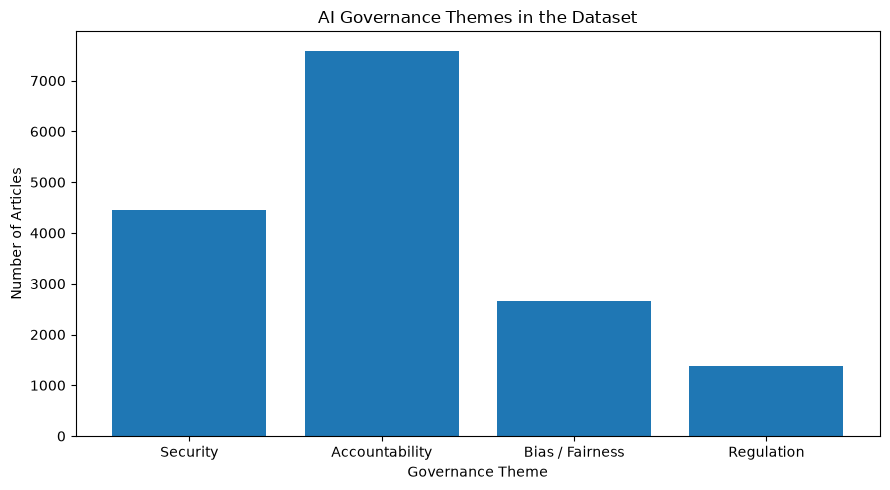

In [62]:
plt.figure(figsize=(9, 5))

plt.bar(
    governance_theme_counts["Governance Theme"],
    governance_theme_counts["Articles"]
)

plt.title("AI Governance Themes in the Dataset")
plt.xlabel("Governance Theme")
plt.ylabel("Number of Articles")

plt.tight_layout()
save_figure("governance_themes")
plt.show()

#### EDA Findings: Governance Theme Coverage

Among the four selected AI Governance dimensions, Accountability is the most frequently represented theme, appearing in 7,592 articles (15.92% of the dataset).

Security is represented in 4,455 articles (9.34%), followed by Bias/Fairness with 2,662 articles (5.58%). Regulation is the least frequent dimension with 1,370 articles (2.87%).

Since individual articles may be associated with more than one governance theme, these percentages are not mutually exclusive and should not be summed to estimate the overall share of governance-related content.

#### Overall AI Governance Coverage

To estimate the overall relevance of AI Governance within the dataset, articles associated with at least one of the four governance dimensions are compared with all remaining articles.

In [63]:
governance_columns = [
    "security",
    "accountability",
    "bias_fairness",
    "regulation"
]

df_clean["governance_related"] = (
    df_clean[governance_columns]
    .any(axis=1)
)

governance_articles = int(
    df_clean["governance_related"].sum()
)

other_articles = (
    len(df_clean) - governance_articles
)

governance_coverage = pd.DataFrame({
    "Category": [
        "Governance-related",
        "Other articles"
    ],
    "Articles": [
        governance_articles,
        other_articles
    ]
})

governance_coverage

,Category,Articles
0,Governance-related,12946
1,Other articles,34733


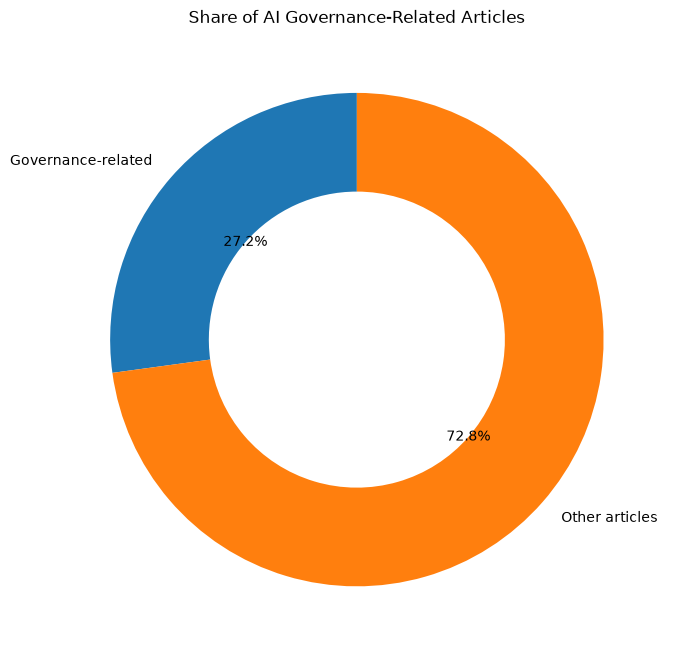

In [64]:
plt.figure(figsize=(7, 7))

plt.pie(
    governance_coverage["Articles"],
    labels=governance_coverage["Category"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Share of AI Governance-Related Articles")

plt.tight_layout()
save_figure("governance_share")
plt.show()

### Governance Theme Overlap

Because AI Governance dimensions are not mutually exclusive, their co-occurrence is examined at article level. This helps identify relationships and overlaps between the four governance themes.

In [65]:
theme_labels = {
    "security": "Security",
    "accountability": "Accountability",
    "bias_fairness": "Bias / Fairness",
    "regulation": "Regulation"
}

overlap_matrix = pd.DataFrame(
    index=theme_labels.values(),
    columns=theme_labels.values(),
    dtype=int
)

for col_a, label_a in theme_labels.items():
    for col_b, label_b in theme_labels.items():

        overlap_matrix.loc[label_a, label_b] = int(
            (
                df_clean[col_a]
                & df_clean[col_b]
            ).sum()
        )

display(overlap_matrix)

,Security,Accountability,Bias / Fairness,Regulation
Security,4455.0,1103.0,546.0,390.0
Accountability,1103.0,7592.0,915.0,563.0
Bias / Fairness,546.0,915.0,2662.0,276.0
Regulation,390.0,563.0,276.0,1370.0


#### Governance Theme Co-Occurrence

The overlap between governance dimensions is visualized to identify which themes are most frequently discussed together within the same articles.

The diagonal represents the total number of articles associated with each individual theme, while the off-diagonal values represent co-occurrences between two themes.

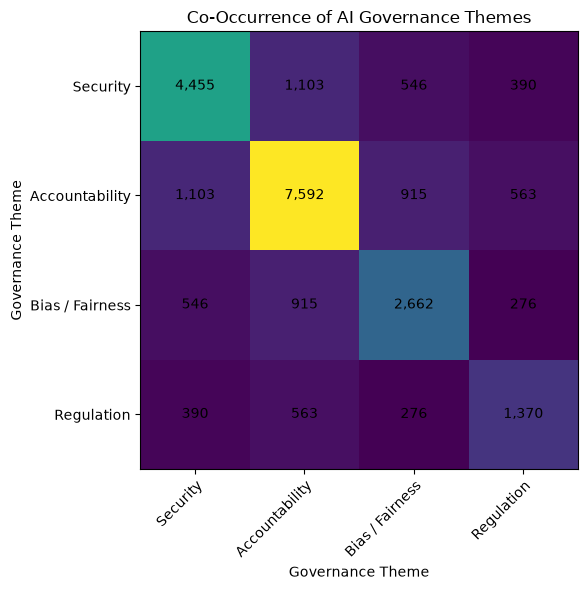

In [66]:
import numpy as np
import matplotlib.pyplot as plt

matrix_values = overlap_matrix.astype(int).values
labels = overlap_matrix.index.tolist()

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(matrix_values)

ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))

ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)

# Add values to each cell
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(
            j,
            i,
            f"{matrix_values[i, j]:,}",
            ha="center",
            va="center"
        )

ax.set_title("Co-Occurrence of AI Governance Themes")
ax.set_xlabel("Governance Theme")
ax.set_ylabel("Governance Theme")

fig.tight_layout()
save_figure("governance_theme_cooccurrence")
plt.show()

### Governance Theme Breadth

To examine whether governance-related articles focus on individual issues or combine several dimensions, the number of governance themes associated with each article is calculated.

Each governance-related article can therefore cover between one and four of the selected dimensions.

In [67]:
df_clean["governance_theme_count"] = (
    df_clean[governance_columns]
    .sum(axis=1)
)

theme_breadth = (
    df_clean.loc[
        df_clean["governance_related"],
        "governance_theme_count"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Governance Themes")
    .reset_index(name="Articles")
)

theme_breadth["Share (%)"] = (
    theme_breadth["Articles"]
    / theme_breadth["Articles"].sum()
    * 100
).round(2)

display(
    theme_breadth.style
    .hide(axis="index")
    .format({
        "Number of Governance Themes": "{:.0f}",
        "Articles": "{:.0f}",
        "Share (%)": "{:.2f}"
    })
    .set_properties(
        subset=[
            "Number of Governance Themes",
            "Articles",
            "Share (%)"
        ],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Number of Governance Themes,Articles,Share (%)
1,10390,80.26
2,2062,15.93
3,411,3.17
4,83,0.64


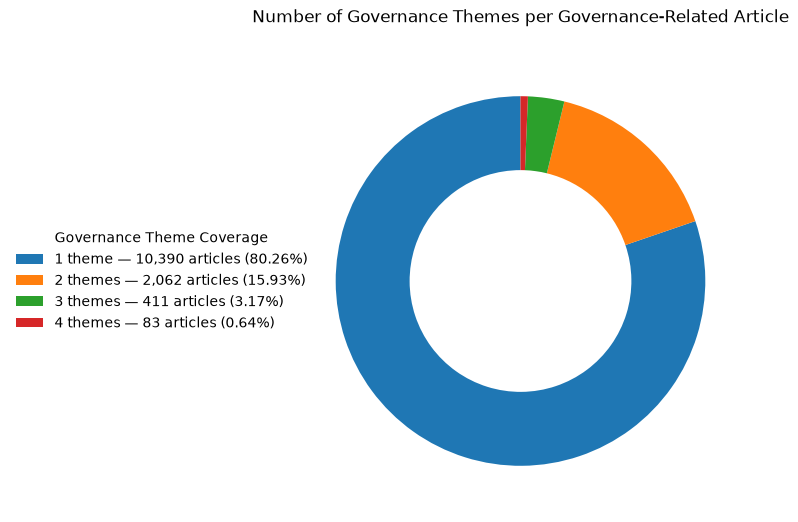

In [68]:
fig, ax = plt.subplots(figsize=(11, 6))

wedges, _ = ax.pie(
    theme_breadth["Articles"],
    startangle=90,
    wedgeprops={"width": 0.4}
)

legend_labels = [
    (
        f"{int(row['Number of Governance Themes'])} "
        f"{'theme' if row['Number of Governance Themes'] == 1 else 'themes'}"
        f" — {int(row['Articles']):,} articles "
        f"({row['Share (%)']:.2f}%)"
    )
    for _, row in theme_breadth.iterrows()
]

ax.legend(
    wedges,
    legend_labels,
    title="Governance Theme Coverage",
    loc="center left",
    bbox_to_anchor=(-0.62, 0.5),
    frameon=False
)

ax.set_title(
    "Number of Governance Themes per Governance-Related Article",
    pad=20
)

plt.subplots_adjust(left=0.30, right=0.95)

save_figure("governance_theme_breadth")
plt.show()

#### EDA Findings: Governance Theme Breadth

Most governance-related articles focus on a single governance dimension. Of the 12,946 governance-related articles, 10,390 (80.26%) are associated with only one of the four selected themes.

A further 2,062 articles (15.93%) cover two governance dimensions, while 411 articles (3.17%) cover three themes and 83 articles (0.64%) cover all four.

This suggests that governance-related coverage in the dataset is predominantly theme-specific, although approximately one fifth of governance-related articles connect multiple governance dimensions.

### Governance Themes Over Time

The monthly development of the four governance dimensions is examined to identify changes in their prevalence throughout the observation period.

Since an article may be associated with more than one governance theme, the monthly theme counts are not mutually exclusive.

In [69]:
monthly_governance = (
    df_clean
    .set_index("date")[[
        "security",
        "accountability",
        "bias_fairness",
        "regulation"
    ]]
    .resample("ME")
    .sum()
    .reset_index()
)

monthly_governance = monthly_governance.rename(columns={
    "security": "Security",
    "accountability": "Accountability",
    "bias_fairness": "Bias / Fairness",
    "regulation": "Regulation"
})

monthly_governance.head()

,date,Security,Accountability,Bias / Fairness,Regulation
0,2024-09-30,112,128,56,21
1,2024-10-31,274,227,146,67
2,2024-11-30,176,181,102,52
3,2024-12-31,172,190,71,42
4,2025-01-31,227,327,134,63


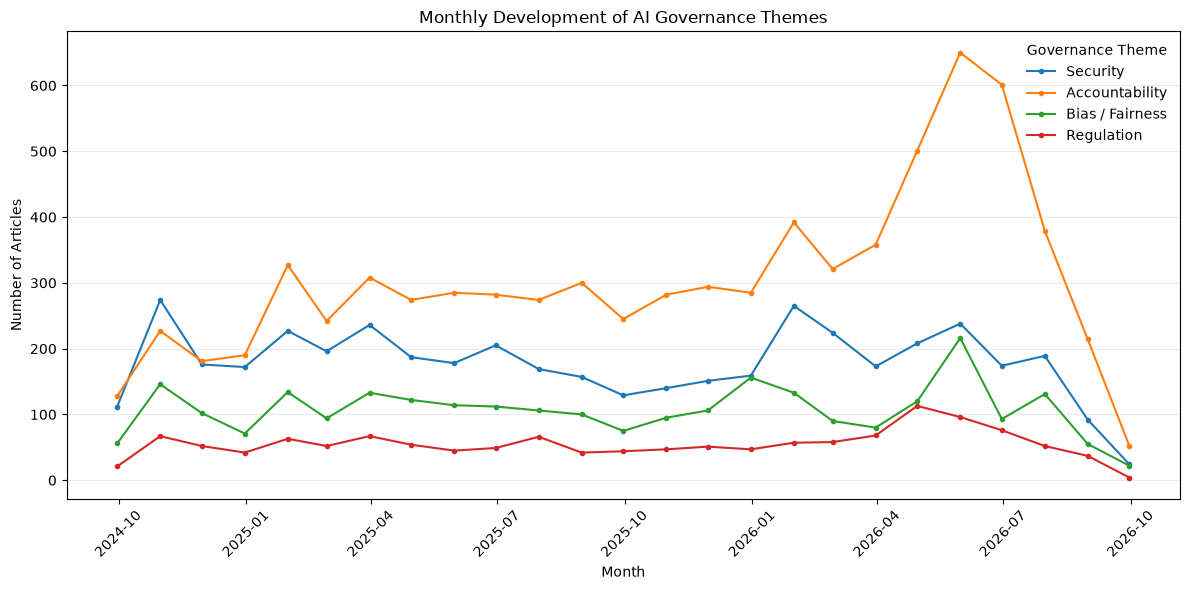

In [70]:
plt.figure(figsize=(12, 6))

for theme in [
    "Security",
    "Accountability",
    "Bias / Fairness",
    "Regulation"
]:
    plt.plot(
        monthly_governance["date"],
        monthly_governance[theme],
        marker="o",
        markersize=3,
        label=theme
    )

plt.title("Monthly Development of AI Governance Themes")
plt.xlabel("Month")
plt.ylabel("Number of Articles")

plt.legend(
    title="Governance Theme",
    frameon=False
)

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
save_figure("governance_themes_monthly")
plt.show()

#### EDA Findings: Governance Themes Over Time

Accountability is the most frequently represented governance dimension throughout most of the observation period. Its absolute article volume increases markedly during 2026, reaching its highest levels around the middle of the year before declining again toward the end of the observation period.

Security is generally the second most frequent theme, while Bias/Fairness occurs at lower levels. Regulation remains the least frequently represented theme throughout the analyzed period, although it also shows a noticeable increase during parts of 2026.

However, these values represent absolute monthly article counts. Since the overall number of articles also varies considerably between months, absolute increases do not necessarily indicate that a governance theme became more prominent within the dataset. Relative monthly shares are therefore examined next.

### Relative Monthly Prevalence of Governance Themes

Absolute theme counts can be influenced by changes in the overall number of articles available in a given month.

To account for differences in monthly publication volume, the number of articles associated with each governance theme is therefore expressed as a percentage of all articles published during the respective month.

This allows changes in the relative prominence of each governance dimension to be compared over time.

In [71]:
monthly_total_articles = (
    df_clean
    .set_index("date")
    .resample("ME")
    .size()
)

monthly_governance_share = (
    monthly_governance
    .set_index("date")[
        [
            "Security",
            "Accountability",
            "Bias / Fairness",
            "Regulation"
        ]
    ]
    .div(monthly_total_articles, axis=0)
    .mul(100)
    .reset_index()
)

monthly_governance_share.head()

,date,Security,Accountability,Bias / Fairness,Regulation
0,2024-09-30,11.487179,13.128205,5.743590,2.153846
1,2024-10-31,12.894118,10.682353,6.870588,3.152941
2,2024-11-30,10.114943,10.402299,5.862069,2.988506
3,2024-12-31,11.813187,13.049451,4.876374,2.884615
4,2025-01-31,9.276665,13.363302,5.476093,2.574581


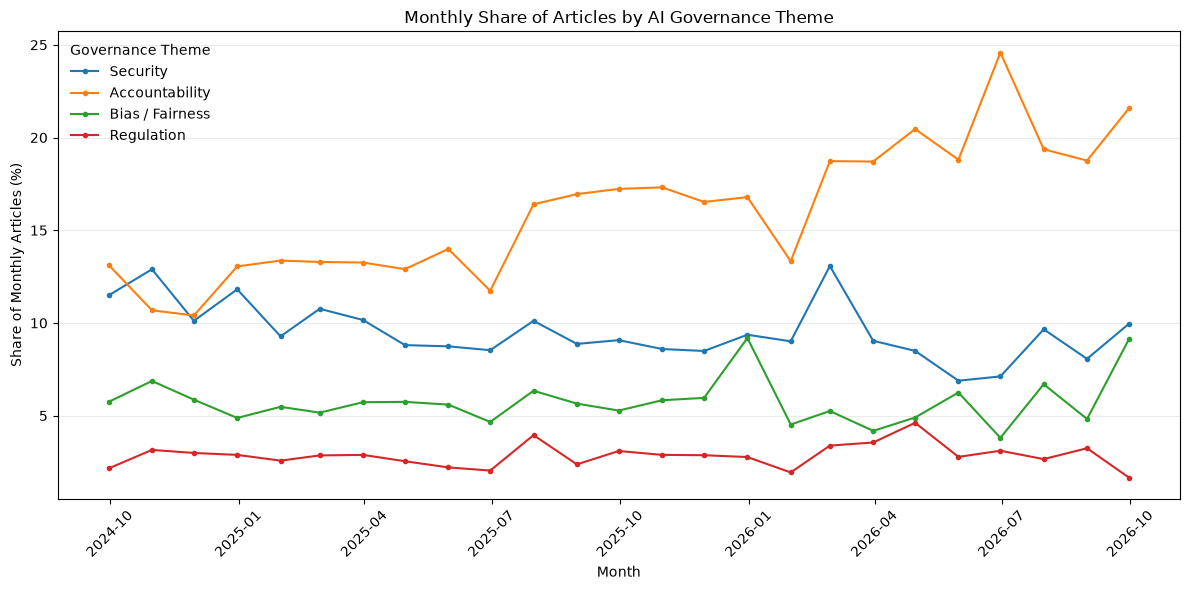

In [72]:
plt.figure(figsize=(12, 6))

for theme in [
    "Security",
    "Accountability",
    "Bias / Fairness",
    "Regulation"
]:
    plt.plot(
        monthly_governance_share["date"],
        monthly_governance_share[theme],
        marker="o",
        markersize=3,
        label=theme
    )

plt.title("Monthly Share of Articles by AI Governance Theme")
plt.xlabel("Month")
plt.ylabel("Share of Monthly Articles (%)")

plt.legend(
    title="Governance Theme",
    frameon=False
)

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
save_figure("governance_themes_monthly_share")
plt.show()

#### EDA Findings: Relative Governance Theme Prevalence

Normalizing the governance-theme counts by total monthly publication volume confirms that the increasing prominence of Accountability is not solely explained by changes in the number of articles collected each month.

Accountability becomes increasingly prevalent over the observation period, particularly during 2026. Security remains comparatively stable, while Bias/Fairness shows greater month-to-month variation. Regulation consistently represents the smallest share of monthly articles.

The first and last months of the observation period contain only partial monthly coverage and should therefore be interpreted with caution.

### Sources of AI Governance-Related Coverage

The distribution of governance-related articles across publishing domains is examined to identify which sources contribute most strongly to the AI Governance subset of the dataset.

In [73]:
top_governance_sources = (
    df_clean.loc[df_clean["governance_related"], "domain"]
    .value_counts()
    .head(15)
    .reset_index()
)

top_governance_sources.columns = [
    "Source",
    "Governance Articles"
]

display(
    top_governance_sources.style
    .hide(axis="index")
    .set_properties(
        subset=["Source", "Governance Articles"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Source,Governance Articles
builtin,840
aijourn,633
dev,405
theconversation,338
thenewstack,302
csis,289
kpmg,239
aithority,217
foreignpolicy,212
apnews,211


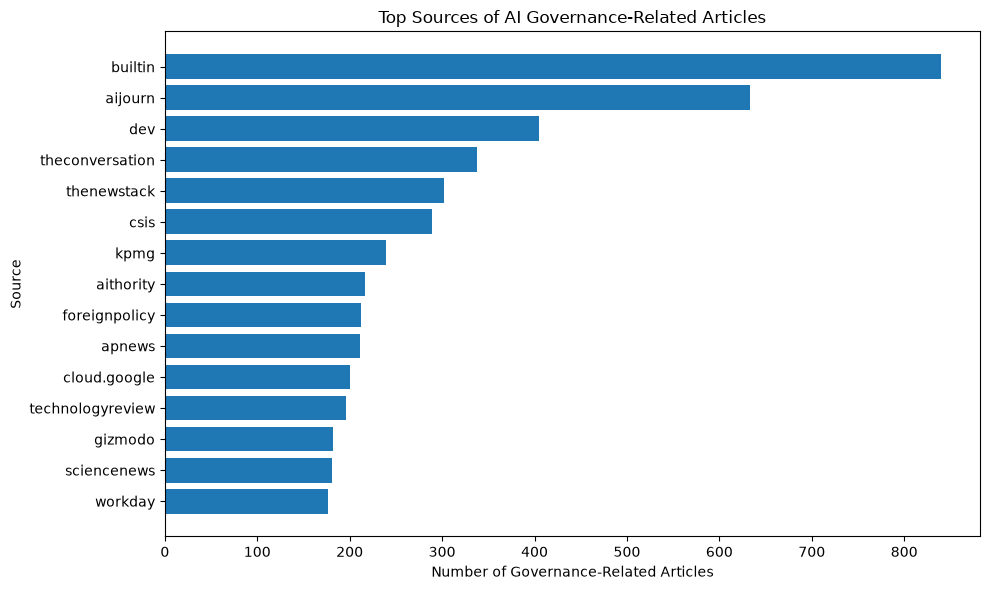

In [74]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_governance_sources["Source"][::-1],
    top_governance_sources["Governance Articles"][::-1]
)

plt.title("Top Sources of AI Governance-Related Articles")
plt.xlabel("Number of Governance-Related Articles")
plt.ylabel("Source")

plt.tight_layout()
save_figure("governance_top_sources")
plt.show()

#### EDA Findings: Sources of Governance-Related Coverage

AI Governance-related coverage is distributed across a broad range of publishing domains. The largest contributors are `builtin`, `aijourn`, and `dev`, while sources such as `theconversation`, `thenewstack`, `csis`, `kpmg`, and `foreignpolicy` also contribute substantially.

The 15 largest sources account for approximately 35.7% of all governance-related articles. This indicates that several publishers contribute strongly to the Governance subset, while most Governance-related coverage remains distributed across a wider range of sources.

### Focused Analysis: Accountability Over Time

The previous temporal analysis indicates a marked increase in the absolute number of Accountability-related articles during parts of 2026.

To distinguish between changes in overall publication volume and changes in the relative prominence of Accountability, monthly article volume, Accountability-related article counts and Accountability's share of monthly coverage are examined together.

In [75]:
accountability_monthly = (
    df_clean
    .set_index("date")
    .resample("ME")
    .agg(
        Total_Articles=("record_id", "count"),
        Accountability_Articles=("accountability", "sum")
    )
    .reset_index()
)

# Keep only complete months
accountability_monthly = accountability_monthly[
    (accountability_monthly["date"] >= "2024-10-31") &
    (accountability_monthly["date"] <= "2026-08-31")
].copy()

accountability_monthly["Accountability Share (%)"] = (
    accountability_monthly["Accountability_Articles"]
    / accountability_monthly["Total_Articles"]
    * 100
).round(2)

display(
    accountability_monthly.style
    .hide(axis="index")
    .format({
        "date": lambda x: x.strftime("%Y-%m"),
        "Total_Articles": "{:,.0f}",
        "Accountability_Articles": "{:,.0f}",
        "Accountability Share (%)": "{:.2f}"
    })
    .set_properties(
        subset=[
            "date",
            "Total_Articles",
            "Accountability_Articles",
            "Accountability Share (%)"
        ],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

date,Total_Articles,Accountability_Articles,Accountability Share (%)
2024-10,"2,125",227,10.68
2024-11,"1,740",181,10.40
2024-12,"1,456",190,13.05
2025-01,"2,447",327,13.36
2025-02,"1,821",242,13.29
2025-03,"2,323",308,13.26
2025-04,"2,124",274,12.90
2025-05,"2,037",285,13.99
2025-06,"2,403",282,11.74
2025-07,"1,671",274,16.40


#### Relationship Between Publication Volume and Accountability Coverage

To assess whether the increase in Accountability-related articles is associated with changes in overall publication volume, the relationship between total monthly article volume and Accountability-related article volume is examined.

In [76]:
accountability_correlation = accountability_monthly[
    [
        "Total_Articles",
        "Accountability_Articles"
    ]
].corr().iloc[0, 1]

print(
    f"Correlation between total monthly article volume "
    f"and Accountability article volume: "
    f"{accountability_correlation:.3f}"
)

Correlation between total monthly article volume and Accountability article volume: 0.754


#### Relative Development of Publication Volume and Accountability Coverage

To compare their development despite different absolute scales, total article volume and Accountability-related article volume are indexed to 100 in the first complete month of the analysis.

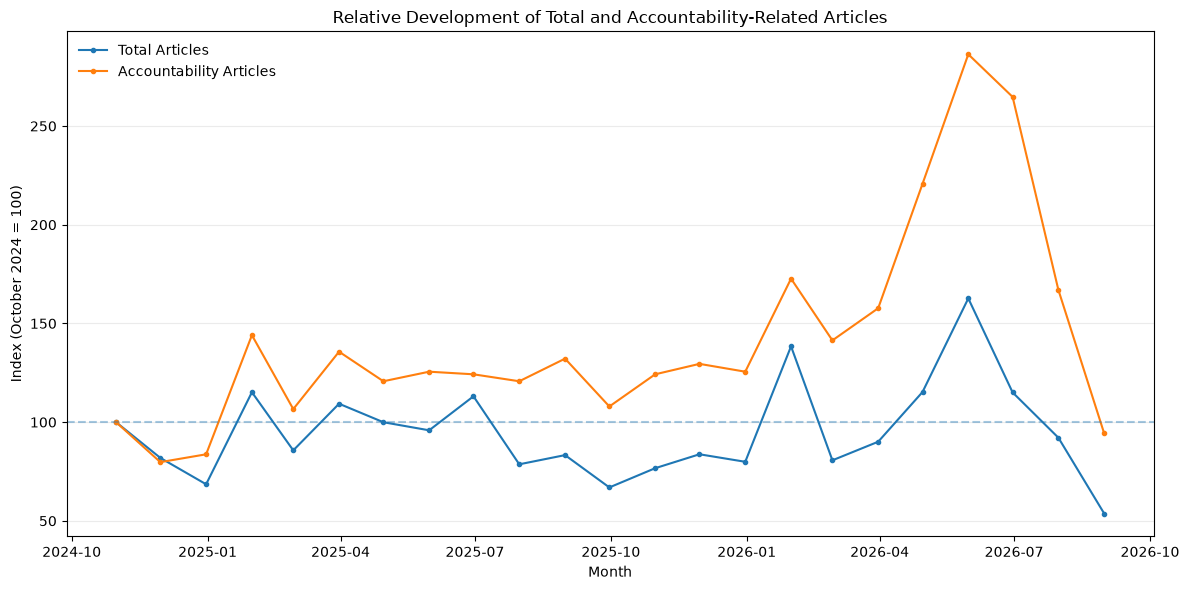

In [77]:
accountability_indexed = accountability_monthly[
    [
        "date",
        "Total_Articles",
        "Accountability_Articles"
    ]
].copy()

accountability_indexed["Total Articles Index"] = (
    accountability_indexed["Total_Articles"]
    / accountability_indexed["Total_Articles"].iloc[0]
    * 100
)

accountability_indexed["Accountability Index"] = (
    accountability_indexed["Accountability_Articles"]
    / accountability_indexed["Accountability_Articles"].iloc[0]
    * 100
)

plt.figure(figsize=(12, 6))

plt.plot(
    accountability_indexed["date"],
    accountability_indexed["Total Articles Index"],
    marker="o",
    markersize=3,
    label="Total Articles"
)

plt.plot(
    accountability_indexed["date"],
    accountability_indexed["Accountability Index"],
    marker="o",
    markersize=3,
    label="Accountability Articles"
)

plt.axhline(
    100,
    linestyle="--",
    alpha=0.4
)

plt.title("Relative Development of Total and Accountability-Related Articles")
plt.xlabel("Month")
plt.ylabel("Index (October 2024 = 100)")

plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
save_figure("accountability_indexed")
plt.show()

### Interpretation

The monthly volume of Accountability-related articles is positively associated with overall publication volume (r = 0.754), indicating that part of the increase can be explained by changes in the total number of articles published.

However, the indexed comparison and the monthly share show that overall publication volume does not fully explain the development. Accountability-related coverage grows substantially faster than total article volume during several periods, particularly in 2026.

The share of Accountability-related articles is around 10–13% in late 2024 and increases to approximately 16–17% during much of the second half of 2025. In 2026, the share is generally higher and reaches a maximum of 24.58% in June 2026.

Overall, this suggests that Accountability became increasingly prominent within the analysed AI media coverage, rather than the rise in Accountability-related articles being caused solely by higher overall publication volume.

### Saving the Cleaned Corpus

The cleaned full corpus is saved so that later stages (e.g. embedding training in Stage 2 and passage selection in Stage 3) can reuse it without repeating the cleaning workflow.

The file contains all 47,679 cleaned and de-duplicated records together with the AI Governance theme flags derived above. The segmented `content` list is omitted because `content_text` holds the same cleaned text as one continuous string.

In [78]:
CLEAN_CORPUS_PATH = (
    CORPUS_DIR / "ai_media_clean.pkl.gz"
)

clean_corpus = df_clean.drop(columns=["content"])

clean_corpus.to_pickle(
    CLEAN_CORPUS_PATH,
    compression="gzip"
)

print(f"Cleaned corpus saved to: {CLEAN_CORPUS_PATH}")
print(f"Records saved: {len(clean_corpus):,}")
print(f"Columns saved: {', '.join(clean_corpus.columns)}")
print(f"File size: {CLEAN_CORPUS_PATH.stat().st_size / (1024 ** 2):.1f} MB")

Cleaned corpus saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\processed\corpus\ai_media_clean.pkl.gz
Records saved: 47,679
Columns saved: record_id, title, date, domain, url, tags, content_text, unresolved_encoding, security, accountability, bias_fairness, regulation, governance_related, governance_theme_count
File size: 163.9 MB


## Topic-Focused Knowledge Graph
The previous analysis examined how the four AI Governance themes — Security, Accountability, Bias/Fairness and Regulation — are represented across the dataset.

The next step moves from frequency-based analysis to the relationships between entities appearing in governance-related articles. A topic-focused Knowledge Graph is constructed to represent relevant entities and their connections within the AI Governance context.

The process consists of selecting the relevant governance articles, extracting entities, identifying meaningful relationships and representing these relationships as a graph.

### Knowledge Graph Schema and Data Dictionary

Before entities and relations are extracted, a compact schema for the AI Governance Knowledge Graph is defined. It specifies which node types and relation types the graph may contain and serves as the single reference for all subsequent extraction and graph-construction steps. The schema is stored together with the graph so that Stage 3 can interpret nodes and edges consistently.

**Node types**

| Node type | Description | Examples | Source |
|---|---|---|---|
| `ORG` | Companies, organisations and institutions | OpenAI, Google, European Union | spaCy NER |
| `PERSON` | Individuals | Trump, Elon Musk | spaCy NER |
| `GPE` | Countries, cities and geopolitical entities | United States, China | spaCy NER |
| `LAW` | Laws and regulations | EU AI Act, GDPR, Digital Services Act | spaCy NER + EntityRuler |
| `STANDARD` | Governance standards, frameworks and protocols | NIST AI RMF, ISO/IEC 42001, Model Context Protocol | EntityRuler + normalization |
| `REGULATOR` | Regulatory and standard-setting authorities | FTC, NIST, AI Office, European Commission | EntityRuler |
| `MODEL` | AI models | Claude, Gemini | normalization |
| `PRODUCT` | Products and platforms | GitHub, YouTube | spaCy NER + normalization |
| `TECHNOLOGY` | Technologies and technical concepts | Large Language Model, API | normalization |
| `GOVERNANCE_THEME` | One of the four Governance dimensions | Security, Accountability, Bias / Fairness, Regulation | tag mapping |

Every node is identified as `TYPE::NAME` (e.g. `ORG::OpenAI`) and carries the attributes `name`, `entity_type` and, for entities, `article_frequency` (number of Governance articles mentioning the entity).

**Relation types**

| Relation | Direction | Between | Meaning | Source |
|---|---|---|---|---|
| `CO_MENTIONED_WITH` | undirected | entity – entity | Both entities occur in the same article; weight = number of shared articles | co-occurrence |
| `ASSOCIATED_WITH_THEME` | undirected | entity – theme | Entity occurs in articles of the Governance theme; weight = number of articles | tag mapping |
| `REGULATES` | directed | LAW / REGULATOR / GPE / ORG → ORG / TECHNOLOGY / MODEL / PRODUCT | Subject regulates or restricts the object | LLM extraction |
| `INVESTIGATES` | directed | REGULATOR / GPE / ORG → ORG / PERSON | Subject investigates or audits the object | LLM extraction |
| `FINES` | directed | REGULATOR / GPE / ORG → ORG | Subject imposes a fine or penalty on the object | LLM extraction |
| `SUES` | directed | any entity → ORG / PERSON | Subject takes legal action against the object | LLM extraction |
| `COMPLIES_WITH` | directed | ORG / PRODUCT / MODEL → LAW / STANDARD | Subject complies with or aligns to the object | LLM extraction |
| `ADOPTS` | directed | GPE / ORG / REGULATOR → LAW / STANDARD | Subject adopts, passes or implements the object | LLM extraction |
| `PROPOSES` | directed | GPE / ORG / REGULATOR / PERSON → LAW / STANDARD | Subject proposes or drafts the object | LLM extraction |
| `DEVELOPS` | directed | ORG / PERSON → MODEL / PRODUCT / TECHNOLOGY / STANDARD | Subject develops or releases the object | LLM extraction |
| `PARTNERS_WITH` | directed (symmetric meaning) | ORG / GPE → ORG / GPE | Subject collaborates with the object | LLM extraction |

Edges from LLM extraction additionally carry the source `record_id`, the publication `date` and the exact `evidence` text span, so that every relation can be traced back to the AI Media Dataset.

In [79]:
KG_SCHEMA = {
    "node_identifier": "TYPE::NAME",
    "node_types": {
        "ORG": "Companies, organisations and institutions",
        "PERSON": "Individuals",
        "GPE": "Countries, cities and geopolitical entities",
        "LAW": "Laws and regulations",
        "STANDARD": "Governance standards, frameworks and protocols",
        "REGULATOR": "Regulatory and standard-setting authorities",
        "MODEL": "AI models",
        "PRODUCT": "Products and platforms",
        "TECHNOLOGY": "Technologies and technical concepts",
        "GOVERNANCE_THEME": "One of the four Governance dimensions"
    },
    "node_attributes": {
        "name": "Normalized entity name",
        "entity_type": "Node type",
        "article_frequency": "Number of Governance-related articles containing the entity"
    },
    "relation_types": {
        "CO_MENTIONED_WITH": {
            "source": "co-occurrence",
            "direction": "undirected",
            "weight": "Number of Governance-related articles in which both entities occur"
        },
        "ASSOCIATED_WITH_THEME": {
            "source": "tag mapping",
            "direction": "undirected",
            "weight": "Number of articles in which the entity occurs together with the Governance theme"
        },
        "REGULATES": {"source": "LLM extraction", "direction": "directed",
                      "meaning": "Subject regulates or restricts the object"},
        "INVESTIGATES": {"source": "LLM extraction", "direction": "directed",
                         "meaning": "Subject investigates or audits the object"},
        "FINES": {"source": "LLM extraction", "direction": "directed",
                  "meaning": "Subject imposes a fine or penalty on the object"},
        "SUES": {"source": "LLM extraction", "direction": "directed",
                 "meaning": "Subject takes legal action against the object"},
        "COMPLIES_WITH": {"source": "LLM extraction", "direction": "directed",
                          "meaning": "Subject complies with or aligns to the object"},
        "ADOPTS": {"source": "LLM extraction", "direction": "directed",
                   "meaning": "Subject adopts, passes or implements the object"},
        "PROPOSES": {"source": "LLM extraction", "direction": "directed",
                     "meaning": "Subject proposes or drafts the object"},
        "DEVELOPS": {"source": "LLM extraction", "direction": "directed",
                     "meaning": "Subject develops or releases the object"},
        "PARTNERS_WITH": {"source": "LLM extraction", "direction": "directed (symmetric meaning)",
                          "meaning": "Subject collaborates with the object"}
    },
    "extracted_edge_attributes": {
        "record_id": "Source article in the AI Media Dataset",
        "date": "Publication date of the source article",
        "evidence": "Exact text span stating the relation"
    },
    "graph_files": {
        "ai_governance_knowledge_graph.graphml": "Entities with CO_MENTIONED_WITH edges",
        "ai_governance_knowledge_graph_enriched.graphml": "Additionally Governance themes with ASSOCIATED_WITH_THEME edges",
        "ai_governance_relation_graph.graphml": "Entities with LLM-extracted, directed and source-linked relations"
    }
}

schema_overview = pd.DataFrame(
    [
        {"Relation": relation, "Source": spec["source"], "Direction": spec["direction"]}
        for relation, spec in KG_SCHEMA["relation_types"].items()
    ]
)

print(f"Node types: {len(KG_SCHEMA['node_types'])}")
print(f"Relation types: {len(KG_SCHEMA['relation_types'])}")

display(schema_overview)

Node types: 10
Relation types: 11


,Relation,Source,Direction
0,CO_MENTIONED_WITH,co-occurrence,undirected
1,ASSOCIATED_WITH_THEME,tag mapping,undirected
2,REGULATES,LLM extraction,directed
3,INVESTIGATES,LLM extraction,directed
4,FINES,LLM extraction,directed
5,SUES,LLM extraction,directed
6,COMPLIES_WITH,LLM extraction,directed
7,ADOPTS,LLM extraction,directed
8,PROPOSES,LLM extraction,directed
9,DEVELOPS,LLM extraction,directed


### Knowledge Graph Preparation

First, the governance-related subset is prepared for entity and relation extraction. Only the textual information required for the Knowledge Graph is retained.

In [80]:
# Select articles associated with at least one AI Governance theme
governance_df = df_clean.loc[
    df_clean["governance_related"],
    [
        "record_id",
        "title",
        "date",
        "domain",
        "url",
        "tags",
        "content_text",
        "security",
        "accountability",
        "bias_fairness",
        "regulation"
    ]
].copy()

# Reset the index so the governance subset has a clean sequential index
governance_df = governance_df.reset_index(drop=True)

print(f"Governance-related articles: {len(governance_df):,}")
print(f"Columns retained: {governance_df.shape[1]}")

Governance-related articles: 12,946
Columns retained: 11


The Knowledge Graph is built from the governance-related subset rather than the full dataset. This reduces unrelated content while preserving the article text, metadata and governance-theme classifications required for entity and relation extraction.

### Entity Extraction

The Knowledge Graph requires identifiable entities that can act as nodes. Named Entity Recognition (NER) is therefore applied to the governance-related article text.

The extraction focuses on organisations, persons, geopolitical entities, laws/regulations, and products, as these entity types are particularly relevant for analysing relationships within AI Governance discussions. In addition, Governance-specific standards and regulatory authorities are captured as separate entity types.

In [81]:
import spacy

nlp = spacy.load("en_core_web_sm")

# Entity types retained for the AI Governance Knowledge Graph
ENTITY_TYPES = {
    "ORG",        # Organisations and companies
    "PERSON",     # Individuals
    "GPE",        # Countries, cities and geopolitical entities
    "LAW",        # Laws and regulations
    "PRODUCT",    # Technologies and products
    "STANDARD",   # Governance standards and frameworks (EntityRuler)
    "REGULATOR"   # Regulatory and standard-setting authorities (EntityRuler)
}

print("spaCy model loaded successfully.")

spaCy model loaded successfully.


#### Governance-Specific Entity Patterns

The general-purpose spaCy model labels central Governance terms inconsistently. In the governance-related articles, for example, *AI Act* was labelled as an organisation, person or product, and *ISO 42001* received four different labels. Standards and regulatory authorities are also not distinguished from ordinary organisations.

A rule-based `EntityRuler` is therefore added before the statistical NER component. It labels a curated set of laws, standards and regulators consistently; the statistical model keeps these spans and recognizes all other entities as before.

The patterns are deliberately conservative and case-sensitive. Ambiguous abbreviations such as *SEC* or *ICO* are not included. In the corpus, *AI Act* refers to the EU AI Act in the vast majority of cases; other acts such as the *Colorado AI Act* or the *GAIN AI Act* receive their own patterns, which take precedence as longer matches.

In [82]:
import hashlib
import json

GOVERNANCE_ENTITY_PATTERNS = {
    "LAW": [
        "EU AI Act",
        "AI Act",
        "Artificial Intelligence Act",
        "Colorado AI Act",
        "GAIN AI Act",
        "GDPR",
        "General Data Protection Regulation",
        "Digital Services Act",
        "Digital Markets Act",
        "CCPA",
        "California Consumer Privacy Act"
    ],
    "STANDARD": [
        "NIST AI RMF",
        "AI RMF",
        "AI Risk Management Framework",
        "ISO/IEC 42001",
        "ISO 42001",
        "OECD AI Principles"
    ],
    "REGULATOR": [
        "FTC",
        "Federal Trade Commission",
        "NIST",
        "National Institute of Standards and Technology",
        "AI Office",
        "EU AI Office",
        "European AI Office",
        "European Commission"
    ]
}

# Add the patterns before the statistical NER component
if "entity_ruler" in nlp.pipe_names:
    nlp.remove_pipe("entity_ruler")

entity_ruler = nlp.add_pipe(
    "entity_ruler",
    before="ner"
)

entity_ruler.add_patterns([
    {"label": label, "pattern": pattern}
    for label, patterns in GOVERNANCE_ENTITY_PATTERNS.items()
    for pattern in patterns
])

# Configuration fingerprint used to validate cached NER results
NER_CONFIG = {
    "spacy_model": f"{nlp.meta['name']}-{nlp.meta['version']}",
    "entity_types": sorted(ENTITY_TYPES),
    "governance_patterns": hashlib.sha256(
        json.dumps(GOVERNANCE_ENTITY_PATTERNS, sort_keys=True).encode("utf-8")
    ).hexdigest()[:12]
}

# Quick check on a sample sentence
sample_doc = nlp(
    "The FTC and NIST commented on the EU AI Act, ISO/IEC 42001 and the NIST AI RMF."
)

print(f"Pipeline: {nlp.pipe_names}")
print(f"Governance patterns: {sum(len(p) for p in GOVERNANCE_ENTITY_PATTERNS.values())}")
print("Sample entities:", [(ent.text, ent.label_) for ent in sample_doc.ents])

Pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'entity_ruler', 'ner']
Governance patterns: 25
Sample entities: [('FTC', 'REGULATOR'), ('NIST', 'REGULATOR'), ('EU AI Act', 'LAW'), ('ISO/IEC 42001', 'STANDARD'), ('NIST AI RMF', 'STANDARD')]


In [83]:
import time
import pandas as pd

benchmark_results = []

# Test full-text entity extraction on the first 10 governance articles
for i, row in governance_df.head(10).iterrows():

    title = row["title"] if pd.notna(row["title"]) else ""
    content = row["content_text"] if pd.notna(row["content_text"]) else ""

    # Use the complete article text
    full_text = f"{title}. {content}"

    start_time = time.perf_counter()

    doc = nlp(
        full_text,
        disable=["parser", "tagger", "lemmatizer", "attribute_ruler"]
    )

    elapsed = time.perf_counter() - start_time

    # Count relevant entities for additional context
    relevant_entities = [
        ent for ent in doc.ents
        if ent.label_ in ENTITY_TYPES
    ]

    benchmark_results.append({
        "Article": len(benchmark_results) + 1,
        "Content Characters": len(content),
        "Total Characters": len(full_text),
        "Processing Time (sec)": round(elapsed, 2),
        "Relevant Entities": len(relevant_entities)
    })

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df)

print(
    f"\nAverage article length: "
    f"{benchmark_df['Content Characters'].mean():,.0f} characters"
)

print(
    f"Average processing time: "
    f"{benchmark_df['Processing Time (sec)'].mean():.2f} seconds/article"
)

estimated_minutes = (
    benchmark_df["Processing Time (sec)"].mean()
    * len(governance_df)
    / 60
)

print(
    f"Rough estimated time for all {len(governance_df):,} articles: "
    f"{estimated_minutes:.1f} minutes"
)

,Article,Content Characters,Total Characters,Processing Time (sec),Relevant Entities
0,1,10886,10940,0.14,58
1,2,16699,16738,0.24,82
2,3,5068,5185,0.06,6
3,4,8395,8433,0.11,33
4,5,6674,6735,0.10,65
5,6,35810,35864,0.42,149
6,7,7152,7198,0.09,25
7,8,26485,26512,0.34,112
8,9,5388,5503,0.07,18
9,10,5252,5331,0.08,19



Average article length: 12,781 characters
Average processing time: 0.17 seconds/article
Rough estimated time for all 12,946 articles: 35.6 minutes


In [84]:
import gc
import pickle
import time
import pandas as pd

# Remove large temporary objects from earlier extraction attempts
# so they do not unnecessarily remain in memory.
for variable_name in ["governance_texts", "entity_lists"]:
    globals().pop(variable_name, None)

gc.collect()


# ENTITY_TYPES and NER_CONFIG are defined together with the
# spaCy pipeline and the Governance EntityRuler above.


# Paths for resumable extraction

CHECKPOINT_PATH = (
    ENTITIES_DIR / "governance_entities_fulltext_checkpoint.pkl"
)

FINAL_PATH = (
    ENTITIES_DIR / "governance_entities_fulltext.pkl"
)


def save_checkpoint(entity_results):
    """
    Save completed entity extractions.

    A temporary file is written first and then renamed to reduce
    the risk of creating a corrupted checkpoint.
    """

    checkpoint_data = {
        "mode": "full_text",
        "spacy_model": nlp.meta.get("name"),
        "spacy_model_version": nlp.meta.get("version"),
        "entity_types": sorted(ENTITY_TYPES),
        "ner_config": NER_CONFIG,
        "results": entity_results
    }

    temp_path = CHECKPOINT_PATH.with_suffix(".tmp")

    with open(temp_path, "wb") as file:
        pickle.dump(
            checkpoint_data,
            file,
            protocol=pickle.HIGHEST_PROTOCOL
        )

    temp_path.replace(CHECKPOINT_PATH)


# ---------------------------------------------------------
# Reuse existing entity results whenever possible
# ---------------------------------------------------------

interrupted = False
entity_results = {}

current_record_ids = set(
    governance_df["record_id"]
)

print(
    f"Current Governance subset: "
    f"{len(governance_df):,} articles"
)


# ---------------------------------------------------------
# 1. Reuse results from the previously completed extraction
# ---------------------------------------------------------

cached_df = (
    pd.read_pickle(FINAL_PATH)
    if FINAL_PATH.exists()
    else None
)

# Only reuse results created with the current NER configuration
if (
    cached_df is not None
    and cached_df.attrs.get("ner_config") != NER_CONFIG
):
    print(
        "Existing final cache was created with a different "
        "NER configuration and is ignored."
    )
    cached_df = None

if cached_df is not None:

    if "entities" not in cached_df.columns:
        raise ValueError(
            "The existing full-text cache does not contain "
            "an 'entities' column."
        )

    cached_results = dict(
        zip(
            cached_df["record_id"],
            cached_df["entities"]
        )
    )

    # Only reuse articles that are still part of the
    # current Governance subset.
    entity_results.update({
        record_id: entities
        for record_id, entities in cached_results.items()
        if record_id in current_record_ids
    })

    old_only_ids = (
        set(cached_results.keys()) - current_record_ids
    )

    print(
        f"Reusable results from final cache: "
        f"{len(entity_results):,}"
    )

    if old_only_ids:
        print(
            f"Articles no longer in current Governance subset: "
            f"{len(old_only_ids):,}"
        )


# ---------------------------------------------------------
# 2. Also reuse any valid results from the checkpoint
# ---------------------------------------------------------

if CHECKPOINT_PATH.exists():

    with open(CHECKPOINT_PATH, "rb") as file:
        checkpoint_data = pickle.load(file)

    # Only reuse results created with the current NER configuration
    if (
        checkpoint_data.get("mode") != "full_text"
        or checkpoint_data.get("ner_config") != NER_CONFIG
    ):
        print(
            "Existing checkpoint was created with a different "
            "NER configuration and is ignored."
        )
        checkpoint_results = {}
    else:
        checkpoint_results = checkpoint_data["results"]

    additional_checkpoint_results = {
        record_id: entities
        for record_id, entities in checkpoint_results.items()
        if (
            record_id in current_record_ids
            and record_id not in entity_results
        )
    }

    entity_results.update(
        additional_checkpoint_results
    )

    print(
        f"Additional reusable checkpoint results: "
        f"{len(additional_checkpoint_results):,}"
    )


# ---------------------------------------------------------
# Determine which Governance articles still need NER
# ---------------------------------------------------------

completed_ids = set(entity_results.keys())

pending_df = governance_df.loc[
    ~governance_df["record_id"].isin(completed_ids),
    ["record_id", "title", "content_text"]
].copy()

total_articles = len(governance_df)

print(
    f"Already processed: "
    f"{len(entity_results):,}"
)

print(
    f"Still requiring NER: "
    f"{len(pending_df):,}"
)


# ---------------------------------------------------------
# Run spaCy only for articles that have no cached result
# ---------------------------------------------------------

if len(pending_df) > 0:

    # Prevent spaCy's document-length limit from causing an error
    max_text_length = (
        pending_df["title"].fillna("").str.len()
        + pending_df["content_text"].fillna("").str.len()
        + 2
    ).max()

    if max_text_length > nlp.max_length:
        nlp.max_length = int(max_text_length + 1000)


    def pending_text_generator():
        """
        Generate one complete article at a time.

        Using a generator avoids keeping an additional copy
        of all article texts in memory.
        """

        for row in pending_df.itertuples(index=False):

            title = (
                row.title
                if isinstance(row.title, str)
                else ""
            )

            content = (
                row.content_text
                if isinstance(row.content_text, str)
                else ""
            )

            full_text = f"{title}. {content}"

            yield full_text, row.record_id


    start_time = time.perf_counter()
    session_processed = 0


    try:

        for doc, record_id in nlp.pipe(
            pending_text_generator(),
            as_tuples=True,
            batch_size=4,
            disable=[
                "parser",
                "tagger",
                "lemmatizer",
                "attribute_ruler"
            ]
        ):

            article_entities = []
            seen_entities = set()

            for ent in doc.ents:

                entity_text = (
                    " ".join(ent.text.split()).strip()
                )

                # Keep relevant entity types and avoid duplicates
                # within the same article.
                if (
                    ent.label_ in ENTITY_TYPES
                    and len(entity_text) > 1
                ):

                    entity = (
                        entity_text,
                        ent.label_
                    )

                    if entity not in seen_entities:

                        article_entities.append(entity)
                        seen_entities.add(entity)


            entity_results[record_id] = article_entities
            session_processed += 1

            total_completed = len(entity_results)


            # Save every 250 newly processed articles
            if session_processed % 250 == 0:
                save_checkpoint(entity_results)


            # Print progress every 1,000 newly completed articles
            if (
                session_processed % 1000 == 0
                or total_completed == total_articles
            ):

                elapsed = (
                    time.perf_counter() - start_time
                )

                processing_rate = (
                    session_processed / elapsed
                )

                remaining_articles = (
                    total_articles - total_completed
                )

                estimated_remaining = (
                    remaining_articles / processing_rate
                    if processing_rate > 0
                    else 0
                )

                print(
                    f"{total_completed:,} / "
                    f"{total_articles:,} articles "
                    f"({total_completed / total_articles:.1%}) | "
                    f"Session time: {elapsed / 60:.1f} min | "
                    f"Estimated remaining: "
                    f"{estimated_remaining / 60:.1f} min"
                )


    except KeyboardInterrupt:

        save_checkpoint(entity_results)

        interrupted = True

        print("\nExtraction interrupted safely.")
        print(
            f"Saved progress: "
            f"{len(entity_results):,} / "
            f"{total_articles:,} articles."
        )
        print(
            "Run this cell again to continue "
            "from the saved checkpoint."
        )

else:

    print(
        "No new entity extraction required. "
        "All current Governance articles are already cached."
    )


# ---------------------------------------------------------
# Save the complete CURRENT Governance dataset
# ---------------------------------------------------------

if not interrupted:

    save_checkpoint(entity_results)

    governance_df["entities"] = (
        governance_df["record_id"]
        .map(entity_results)
    )

    missing_entity_results = (
        governance_df["entities"].isna().sum()
    )

    if missing_entity_results != 0:
        raise ValueError(
            f"{missing_entity_results} articles are "
            "missing entity extraction results."
        )

    # This overwrites the cache with the current Governance subset,
    # while reusing all previously calculated entity results.
    governance_df.attrs["ner_config"] = NER_CONFIG
    governance_df.to_pickle(FINAL_PATH)

    articles_with_entities = (
        governance_df["entities"]
        .apply(len)
        .gt(0)
        .sum()
    )

    print("\nEntity extraction complete.")
    print(
        f"Articles processed: "
        f"{len(governance_df):,}"
    )
    print(
        f"Articles with at least one entity: "
        f"{articles_with_entities:,}"
    )
    print(
        f"Final dataset saved to: "
        f"{FINAL_PATH}"
    )

Current Governance subset: 12,946 articles


Reusable results from final cache: 12,946
Additional reusable checkpoint results: 0
Already processed: 12,946
Still requiring NER: 0
No new entity extraction required. All current Governance articles are already cached.



Entity extraction complete.
Articles processed: 12,946
Articles with at least one entity: 12,942
Final dataset saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\processed\entities\governance_entities_fulltext.pkl


#### Entity Extraction Quality Check

Before constructing relationships and the Knowledge Graph, the extracted entities are inspected for frequency, entity-type distribution and potential inconsistencies.

Because entities were deduplicated within each article during extraction, the frequency reported below represents the number of governance-related articles in which an entity appears, rather than its total number of textual mentions.

This inspection helps identify common entities, possible naming variants and noisy or incorrectly classified entities that may require normalization before relation extraction.

In [85]:
from collections import Counter

# Count in how many articles each entity-label combination occurs.
# Entities were already deduplicated within individual articles,
# so these counts represent article frequency.
entity_counter = Counter(
    entity
    for entities in governance_df["entities"]
    for entity in entities
)

entity_frequency = pd.DataFrame(
    [
        {
            "Entity": entity_text,
            "Type": entity_type,
            "Article Frequency": count
        }
        for (entity_text, entity_type), count
        in entity_counter.items()
    ]
)

entity_frequency = (
    entity_frequency
    .sort_values(
        "Article Frequency",
        ascending=False
    )
    .reset_index(drop=True)
)


# Summary of extracted entity types
entity_type_summary = (
    entity_frequency
    .groupby("Type")
    .agg(
        Unique_Entities=("Entity", "nunique"),
        Total_Article_Occurrences=("Article Frequency", "sum")
    )
    .sort_values(
        "Total_Article_Occurrences",
        ascending=False
    )
    .reset_index()
)


print(
    f"Unique entity-label combinations: "
    f"{len(entity_frequency):,}"
)

print(
    f"Unique entity names: "
    f"{entity_frequency['Entity'].nunique():,}"
)

print("\nEntity types:")
display(entity_type_summary)

print("\nMost frequent extracted entities:")
display(entity_frequency.head(50))

Unique entity-label combinations: 181,779
Unique entity names: 172,366

Entity types:


,Type,Unique_Entities,Total_Article_Occurrences
0,ORG,99623,260568
1,PERSON,64458,128019
2,GPE,11055,83044
3,PRODUCT,4726,11432
4,LAW,1903,5720
5,REGULATOR,8,956
6,STANDARD,6,182



Most frequent extracted entities:


,Entity,Type,Article Frequency
0,AI,GPE,10294
1,AI,ORG,8248
2,U.S.,GPE,2517
3,Google,ORG,2254
4,US,GPE,2218
5,the United States,GPE,1881
6,China,GPE,1674
7,API,ORG,1608
8,Microsoft,ORG,1543
9,UK,GPE,1385


#### Entity Label Consistency

The initial quality check shows that some frequently occurring entities are assigned to multiple entity types by the pretrained NER model.

Before constructing relationships, entities with inconsistent labels are identified. This allows high-frequency ambiguities and systematic classification errors to be reviewed and normalized before they propagate into the Knowledge Graph.

In [86]:
# Identify entity names that spaCy assigned to more than one entity type

entity_label_variants = (
    entity_frequency
    .groupby("Entity")
    .agg(
        Number_of_Types=("Type", "nunique"),
        Types=("Type", lambda x: ", ".join(sorted(set(x)))),
        Total_Article_Frequency=("Article Frequency", "sum")
    )
    .reset_index()
)

# Keep only entities with conflicting classifications
ambiguous_entities = (
    entity_label_variants
    .loc[entity_label_variants["Number_of_Types"] > 1]
    .sort_values(
        "Total_Article_Frequency",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"Entities assigned to multiple types: "
    f"{len(ambiguous_entities):,}"
)

display(
    ambiguous_entities.head(50)
)

Entities assigned to multiple types: 8,294


,Entity,Number_of_Types,Types,Total_Article_Frequency
0,AI,4,"GPE, ORG, PERSON, PRODUCT",18597
1,OpenAI,3,"GPE, ORG, PERSON",2959
2,Google,4,"GPE, ORG, PERSON, PRODUCT",2273
3,US,2,"GPE, ORG",2219
4,Trump,2,"ORG, PERSON",2101
5,the United States,2,"GPE, ORG",1886
6,API,2,"ORG, PERSON",1612
7,Microsoft,2,"GPE, ORG",1544
8,LLM,2,"ORG, PRODUCT",1388
9,EU,2,"GPE, ORG",1083


#### Entity Normalization

The quality check revealed systematic inconsistencies in the labels assigned by the pretrained NER model. In particular, several frequently occurring AI-specific terms, organisations and technologies were assigned to multiple entity types.

A conservative rule-based normalization layer is therefore applied before relation extraction. Only high-confidence aliases and classifications are corrected, while ambiguous entities are retained for further inspection.

The original extracted entities remain unchanged in order to preserve traceability. Normalized entities are stored separately and used for subsequent Knowledge Graph construction.

In [87]:
# High-confidence aliases used to merge common naming variants
ENTITY_ALIASES = {
    "AI": "Artificial Intelligence",
    "GenAI": "Generative AI",
    "ML": "Machine Learning",
    "LLM": "Large Language Model",
    "RAG": "Retrieval-Augmented Generation",
    "MCP": "Model Context Protocol",
    "IoT": "Internet of Things",

    "U.S.": "United States",
    "US": "United States",
    "the United States": "United States",
    "UK": "United Kingdom",
    "EU": "European Union",

    "Donald Trump": "Trump",

    # Governance-specific variants
    "AI Act": "EU AI Act",
    "Artificial Intelligence Act": "EU AI Act",
    "General Data Protection Regulation": "GDPR",
    "California Consumer Privacy Act": "CCPA",
    "AI RMF": "NIST AI RMF",
    "AI Risk Management Framework": "NIST AI RMF",
    "ISO 42001": "ISO/IEC 42001",
    "Federal Trade Commission": "FTC",
    "National Institute of Standards and Technology": "NIST",
    "EU AI Office": "AI Office",
    "European AI Office": "AI Office"
}

# High-confidence type corrections for frequently occurring entities.
# Custom types such as TECHNOLOGY, MODEL and STANDARD make the
# resulting Knowledge Graph more meaningful than the raw spaCy labels.
ENTITY_TYPE_OVERRIDES = {

    # Organisations
    "OpenAI": "ORG",
    "Google": "ORG",
    "Microsoft": "ORG",
    "Meta": "ORG",
    "Amazon": "ORG",
    "Apple": "ORG",
    "IBM": "ORG",
    "Nvidia": "ORG",
    "Anthropic": "ORG",
    "KPMG": "ORG",
    "PwC": "ORG",
    "Salesforce": "ORG",
    "European Union": "ORG",

    # People
    "Trump": "PERSON",
    "Donald Trump": "PERSON",
    "Biden": "PERSON",
    "Elon Musk": "PERSON",

    # Geopolitical entities
    "United States": "GPE",
    "United Kingdom": "GPE",

    # AI / technology concepts
    "Artificial Intelligence": "TECHNOLOGY",
    "Generative AI": "TECHNOLOGY",
    "Agentic AI": "TECHNOLOGY",
    "Machine Learning": "TECHNOLOGY",
    "Large Language Model": "TECHNOLOGY",
    "Retrieval-Augmented Generation": "TECHNOLOGY",
    "API": "TECHNOLOGY",
    "Internet of Things": "TECHNOLOGY",
    "GPU": "TECHNOLOGY",
    "Kubernetes": "TECHNOLOGY",
    "SQL": "TECHNOLOGY",
    "Linux": "TECHNOLOGY",
    "CRM": "TECHNOLOGY",
    "ERP": "TECHNOLOGY",

    # Standards / protocols
    "Model Context Protocol": "STANDARD",

    # AI models
    "Claude": "MODEL",
    "Gemini": "MODEL",

    # Products / platforms
    "Google Cloud": "PRODUCT",
    "LinkedIn": "PRODUCT",
    "GitHub": "PRODUCT",
    "YouTube": "PRODUCT",
    "Slack": "PRODUCT",
    "Instagram": "PRODUCT",
    "Android": "PRODUCT",

    # Regulation
    "GDPR": "LAW",
    "EU AI Act": "LAW",
    "CCPA": "LAW",
    "Digital Services Act": "LAW",
    "Digital Markets Act": "LAW",

    # Governance standards and frameworks
    "NIST AI RMF": "STANDARD",
    "ISO/IEC 42001": "STANDARD",
    "OECD AI Principles": "STANDARD",

    # Regulatory and standard-setting authorities
    "FTC": "REGULATOR",
    "NIST": "REGULATOR",
    "AI Office": "REGULATOR",
    "European Commission": "REGULATOR"
}


# Obvious extraction artefacts
ENTITY_NOISE = {
    "n’t",
    "n't"
}


def normalize_entity_list(entity_list):

    normalized_entities = []
    seen_entities = set()

    for entity_text, entity_type in entity_list:

        # Standardize known aliases
        canonical_text = ENTITY_ALIASES.get(
            entity_text,
            entity_text
        )

        canonical_text = canonical_text.strip()

        # Remove obvious NER artefacts
        if canonical_text in ENTITY_NOISE:
            continue

        # Correct known systematic classification errors
        normalized_type = ENTITY_TYPE_OVERRIDES.get(
            canonical_text,
            entity_type
        )

        normalized_entity = (
            canonical_text,
            normalized_type
        )

        # Alias normalization may merge several original entities,
        # therefore deduplicate again within each article.
        if normalized_entity not in seen_entities:
            normalized_entities.append(normalized_entity)
            seen_entities.add(normalized_entity)

    return normalized_entities


# Preserve the raw NER result and create a separate normalized version
governance_df["entities_normalized"] = (
    governance_df["entities"]
    .apply(normalize_entity_list)
)


# Recalculate frequencies after normalization
normalized_entity_counter = Counter(
    entity
    for entities in governance_df["entities_normalized"]
    for entity in entities
)

normalized_entity_frequency = pd.DataFrame(
    [
        {
            "Entity": entity_text,
            "Type": entity_type,
            "Article Frequency": count
        }
        for (entity_text, entity_type), count
        in normalized_entity_counter.items()
    ]
).sort_values(
    "Article Frequency",
    ascending=False
).reset_index(drop=True)


# Check how many entity names still occur under multiple types
normalized_label_variants = (
    normalized_entity_frequency
    .groupby("Entity")
    .agg(
        Number_of_Types=("Type", "nunique"),
        Types=("Type", lambda x: ", ".join(sorted(set(x)))),
        Total_Article_Frequency=("Article Frequency", "sum")
    )
    .reset_index()
)

remaining_ambiguous_entities = (
    normalized_label_variants
    .loc[
        normalized_label_variants["Number_of_Types"] > 1
    ]
    .sort_values(
        "Total_Article_Frequency",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    f"Raw entity-label combinations: "
    f"{len(entity_frequency):,}"
)

print(
    f"Normalized entity-label combinations: "
    f"{len(normalized_entity_frequency):,}"
)

print(
    f"Entities still assigned to multiple types: "
    f"{len(remaining_ambiguous_entities):,}"
)

print("\nMost frequent normalized entities:")
display(normalized_entity_frequency.head(50))

print("\nMost frequent remaining ambiguities:")
display(remaining_ambiguous_entities.head(30))

Raw entity-label combinations: 181,779
Normalized entity-label combinations: 181,674
Entities still assigned to multiple types: 8,250

Most frequent normalized entities:


,Entity,Type,Article Frequency
0,Artificial Intelligence,TECHNOLOGY,10735
1,United States,GPE,4826
2,Google,ORG,2259
3,OpenAI,ORG,1862
4,China,GPE,1674
5,API,TECHNOLOGY,1610
6,Microsoft,ORG,1543
7,Trump,PERSON,1496
8,United Kingdom,GPE,1439
9,Large Language Model,TECHNOLOGY,1333



Most frequent remaining ambiguities:


,Entity,Number_of_Types,Types,Total_Article_Frequency
0,Washington,3,"GPE, ORG, PERSON",1032
1,CI,3,"GPE, ORG, PERSON",498
2,UI,3,"GPE, ORG, PERSON",476
3,IP,3,"GPE, ORG, PERSON",472
4,Forem,2,"ORG, PERSON",406
5,DeepSeek,3,"LAW, ORG, PRODUCT",402
6,AP,2,"ORG, PRODUCT",354
7,Cursor,2,"GPE, ORG",295
8,Healthcare,2,"ORG, PERSON",281
9,COVID-19,3,"GPE, ORG, PERSON",275


#### Entity Extraction and Normalization Summary

Full-text Named Entity Recognition was applied to all 12,946 AI Governance-related articles. At least one relevant entity was identified in 12,942 articles.

The initial extraction produced 181,779 entity-label combinations representing 172,366 unique entity names. Organisations and persons account for the largest share of extracted entities, followed by geopolitical entities, products and laws. The Governance-specific EntityRuler adds 8 regulators (956 article occurrences) and 6 standards (182 article occurrences) as separate entity types.

Quality inspection revealed systematic inconsistencies in the pretrained NER model. Frequently occurring AI-specific terms and organisations such as AI, OpenAI, Claude, Gemini, LLM and GDPR were occasionally assigned to multiple or incorrect entity types.

A conservative normalization layer was therefore introduced. High-confidence aliases were merged and clear systematic misclassifications were corrected while preserving the original NER output for traceability. After normalization, 181,674 entity-label combinations remained. The EU AI Act now appears consistently as a single `LAW` entity in 790 Governance articles.

The remaining ambiguities mainly involve terms whose meaning can genuinely depend on context, such as Washington, IP, DeepSeek, Oracle and Cursor. These are intentionally not globally reassigned in order to avoid introducing unsupported assumptions.

The normalized entities provide the basis for subsequent relation extraction, co-occurrence analysis and Knowledge Graph construction.

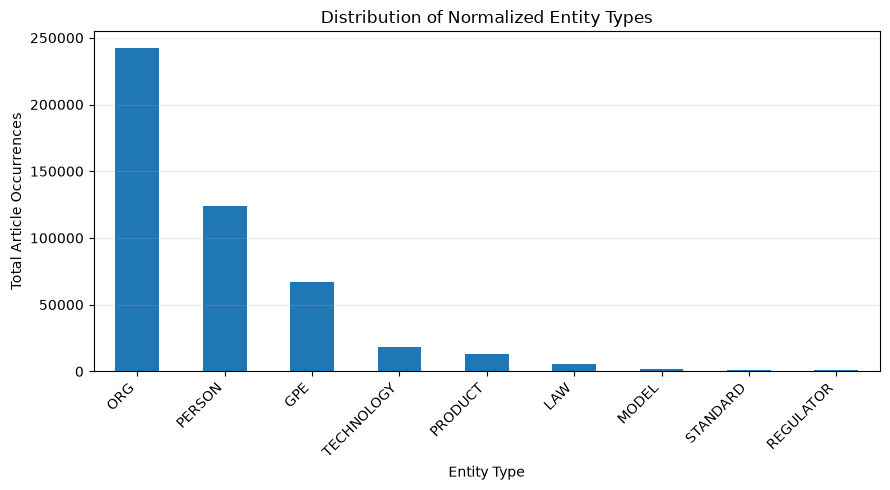

In [88]:
# Summarize article occurrences by normalized entity type
normalized_type_summary = (
    normalized_entity_frequency
    .groupby("Type")["Article Frequency"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

normalized_type_summary.plot(
    kind="bar"
)

plt.title("Distribution of Normalized Entity Types")
plt.xlabel("Entity Type")
plt.ylabel("Total Article Occurrences")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
save_figure("entity_types")
plt.show()

In [89]:
# Save the normalized entity output separately so it can be
# reused without repeating the normalization workflow.

NORMALIZED_ENTITY_PATH = (
    ENTITIES_DIR / "governance_entities_normalized.pkl"
)

normalized_entity_data = governance_df[
    [
        "record_id",
        "entities_normalized"
    ]
].copy()

normalized_entity_data.to_pickle(
    NORMALIZED_ENTITY_PATH
)

print(
    f"Normalized entity data saved to: "
    f"{NORMALIZED_ENTITY_PATH}"
)

print(
    f"Articles saved: "
    f"{len(normalized_entity_data):,}"
)

print(
    f"File size: "
    f"{NORMALIZED_ENTITY_PATH.stat().st_size / (1024 ** 2):.1f} MB"
)

Normalized entity data saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\processed\entities\governance_entities_normalized.pkl
Articles saved: 12,946
File size: 8.8 MB


### Relation Extraction and Co-occurrence Analysis

The normalized entities are used to examine which entities occur together within the same AI Governance-related articles.

Co-occurrence provides a reproducible first representation of relationships between entities: two entities are connected when they are mentioned in the same article, while the number of articles in which they co-occur represents the strength of that connection.

Because the extraction contains a large number of rare entities, a minimum article-frequency threshold is determined before constructing the co-occurrence network. This reduces isolated or highly specific entities that would otherwise create a very large and noisy graph.

In [90]:
# Examine how different minimum article-frequency thresholds
# would affect the size of the Knowledge Graph.

frequency_thresholds = [2, 5, 10, 20, 50, 100]

threshold_summary = []

for threshold in frequency_thresholds:

    retained = normalized_entity_frequency.loc[
        normalized_entity_frequency["Article Frequency"] >= threshold
    ]

    threshold_summary.append({
        "Minimum Article Frequency": threshold,
        "Retained Entity-Label Combinations": len(retained),
        "Share of Entity-Label Combinations (%)": round(
            len(retained) / len(normalized_entity_frequency) * 100,
            2
        ),
        "Total Article Occurrences Retained": int(
            retained["Article Frequency"].sum()
        )
    })

threshold_summary = pd.DataFrame(threshold_summary)

display(threshold_summary)

,Minimum Article Frequency,Retained Entity-Label Combinations,Share of Entity-Label Combinations (%),Total Article Occurrences Retained
0,2,38749,21.33,330534
1,5,10724,5.90,261261
2,10,4880,2.69,223518
3,20,2317,1.28,189206
4,50,837,0.46,145006
5,100,365,0.20,112411


#### Frequency Threshold for Relation Extraction

Entity extraction produced a substantial long tail of entities that occur only in a small number of articles. Including all extracted entities would result in a very large and sparse co-occurrence network dominated by infrequent mentions.

A minimum article frequency of 20 is therefore applied for relation extraction. This retains 2,317 recurring entity-label combinations while substantially reducing the number of rare entities included in the graph.

The threshold is applied only to the relation and Knowledge Graph analysis; the complete normalized entity extraction remains preserved separately.

In [91]:
from itertools import combinations
from collections import Counter

# Minimum number of governance articles in which an entity must occur
MIN_ENTITY_FREQUENCY = 20

# Keep recurring entities for relation extraction
graph_entities = set(
    normalized_entity_frequency.loc[
        normalized_entity_frequency["Article Frequency"]
        >= MIN_ENTITY_FREQUENCY,
        ["Entity", "Type"]
    ].itertuples(index=False, name=None)
)

print(
    f"Entities retained for relation extraction: "
    f"{len(graph_entities):,}"
)


# Count how often two retained entities occur in the same article
cooccurrence_counter = Counter()

articles_with_multiple_entities = 0

for entities in governance_df["entities_normalized"]:

    retained_entities = sorted(
        set(entities) & graph_entities
    )

    if len(retained_entities) >= 2:
        articles_with_multiple_entities += 1

        for entity_a, entity_b in combinations(
            retained_entities,
            2
        ):
            cooccurrence_counter[
                (entity_a, entity_b)
            ] += 1


# Convert relationships into a DataFrame
cooccurrence_df = pd.DataFrame(
    [
        {
            "Entity_1": entity_a[0],
            "Type_1": entity_a[1],
            "Entity_2": entity_b[0],
            "Type_2": entity_b[1],
            "Cooccurrence_Count": count
        }
        for (entity_a, entity_b), count
        in cooccurrence_counter.items()
    ]
)

cooccurrence_df = (
    cooccurrence_df
    .sort_values(
        "Cooccurrence_Count",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    f"Articles containing at least two retained entities: "
    f"{articles_with_multiple_entities:,}"
)

print(
    f"Unique entity relationships: "
    f"{len(cooccurrence_df):,}"
)

print("\nStrongest co-occurring entity pairs:")

display(
    cooccurrence_df.head(30)
)

Entities retained for relation extraction: 2,317


Articles containing at least two retained entities: 12,726
Unique entity relationships: 609,823

Strongest co-occurring entity pairs:


,Entity_1,Type_1,Entity_2,Type_2,Cooccurrence_Count
0,Artificial Intelligence,TECHNOLOGY,United States,GPE,3775
1,Artificial Intelligence,TECHNOLOGY,Google,ORG,2058
2,Artificial Intelligence,TECHNOLOGY,OpenAI,ORG,1780
3,API,TECHNOLOGY,Artificial Intelligence,TECHNOLOGY,1482
4,China,GPE,United States,GPE,1450
5,Artificial Intelligence,TECHNOLOGY,Microsoft,ORG,1420
6,Trump,PERSON,United States,GPE,1355
7,Artificial Intelligence,TECHNOLOGY,Large Language Model,TECHNOLOGY,1287
8,Artificial Intelligence,TECHNOLOGY,China,GPE,1219
9,Artificial Intelligence,TECHNOLOGY,United Kingdom,GPE,1150


In [92]:
# Examine how minimum co-occurrence thresholds affect network size

cooccurrence_thresholds = [2, 3, 5, 10, 20, 50, 100]

edge_threshold_summary = []

for threshold in cooccurrence_thresholds:

    retained_edges = cooccurrence_df.loc[
        cooccurrence_df["Cooccurrence_Count"] >= threshold
    ]

    # Entity name and type jointly identify a node, as in the Knowledge Graph
    retained_nodes = (
        set(zip(retained_edges["Entity_1"], retained_edges["Type_1"]))
        | set(zip(retained_edges["Entity_2"], retained_edges["Type_2"]))
    )

    edge_threshold_summary.append({
        "Minimum Co-occurrence": threshold,
        "Retained Relationships": len(retained_edges),
        "Retained Entities": len(retained_nodes)
    })

edge_threshold_summary = pd.DataFrame(
    edge_threshold_summary
)

display(edge_threshold_summary)

,Minimum Co-occurrence,Retained Relationships,Retained Entities
0,2,304833,2317
1,3,196634,2317
2,5,110203,2317
3,10,49346,2316
4,20,21558,2024
5,50,4282,720
6,100,1396,325


In [93]:
display(normalized_entity_frequency.head(20))

,Entity,Type,Article Frequency
0,Artificial Intelligence,TECHNOLOGY,10735
1,United States,GPE,4826
2,Google,ORG,2259
3,OpenAI,ORG,1862
4,China,GPE,1674
5,API,TECHNOLOGY,1610
6,Microsoft,ORG,1543
7,Trump,PERSON,1496
8,United Kingdom,GPE,1439
9,Large Language Model,TECHNOLOGY,1333


#### Co-occurrence Threshold Selection

The initial co-occurrence extraction produced a highly connected network, reflecting the large number of recurring entities in the governance-related corpus.

To reduce weak and potentially incidental relationships, different minimum co-occurrence thresholds were compared. A threshold of 50 shared articles was selected for the main Knowledge Graph. This reduces the network to 4,282 recurring relationships between 720 typed entities while retaining relationships that appear consistently across the corpus.

Lower-frequency relationships remain preserved in the complete co-occurrence data and can therefore be revisited if required.

In [94]:
# Retain recurring relationships for Knowledge Graph construction
MIN_COOCCURRENCE = 50

graph_edges = (
    cooccurrence_df.loc[
        cooccurrence_df["Cooccurrence_Count"]
        >= MIN_COOCCURRENCE
    ]
    .copy()
    .reset_index(drop=True)
)

# Entity name and type jointly identify a node, as in the Knowledge Graph
graph_nodes = (
    set(zip(graph_edges["Entity_1"], graph_edges["Type_1"]))
    | set(zip(graph_edges["Entity_2"], graph_edges["Type_2"]))
)

print(f"Knowledge Graph entities: {len(graph_nodes):,}")
print(f"Knowledge Graph relationships: {len(graph_edges):,}")

display(graph_edges.head(30))

Knowledge Graph entities: 720
Knowledge Graph relationships: 4,282


,Entity_1,Type_1,Entity_2,Type_2,Cooccurrence_Count
0,Artificial Intelligence,TECHNOLOGY,United States,GPE,3775
1,Artificial Intelligence,TECHNOLOGY,Google,ORG,2058
2,Artificial Intelligence,TECHNOLOGY,OpenAI,ORG,1780
3,API,TECHNOLOGY,Artificial Intelligence,TECHNOLOGY,1482
4,China,GPE,United States,GPE,1450
5,Artificial Intelligence,TECHNOLOGY,Microsoft,ORG,1420
6,Trump,PERSON,United States,GPE,1355
7,Artificial Intelligence,TECHNOLOGY,Large Language Model,TECHNOLOGY,1287
8,Artificial Intelligence,TECHNOLOGY,China,GPE,1219
9,Artificial Intelligence,TECHNOLOGY,United Kingdom,GPE,1150


#### Co-occurrence Matrix

A symmetric co-occurrence matrix is constructed from the relationships retained for the Knowledge Graph after applying the minimum co-occurrence threshold of 50 shared articles.

Each cell represents the number of governance-related articles in which two typed entities occur together. Entity name and entity type are jointly used as the node identifier to avoid unintentionally merging entities with the same surface name but different classifications.

The resulting matrix contains 720 typed entities and represents 4,282 retained relationships.

In [95]:
import numpy as np

# Create unique Knowledge Graph nodes using both entity name and entity type
graph_nodes = (
    set(zip(graph_edges["Entity_1"], graph_edges["Type_1"]))
    | set(zip(graph_edges["Entity_2"], graph_edges["Type_2"]))
)

graph_node_tuples = sorted(graph_nodes)

print(
    f"Knowledge Graph entities: "
    f"{len(graph_node_tuples):,}"
)

print(
    f"Knowledge Graph relationships: "
    f"{len(graph_edges):,}"
)


# Map each typed entity node to a matrix position
node_to_index = {
    node: index
    for index, node in enumerate(graph_node_tuples)
}


# Create the full symmetric co-occurrence matrix
matrix = np.zeros(
    (
        len(graph_node_tuples),
        len(graph_node_tuples)
    ),
    dtype=np.int32
)


for row in graph_edges.itertuples(index=False):

    node_1 = (row.Entity_1, row.Type_1)
    node_2 = (row.Entity_2, row.Type_2)

    i = node_to_index[node_1]
    j = node_to_index[node_2]

    weight = int(row.Cooccurrence_Count)

    matrix[i, j] = weight
    matrix[j, i] = weight


# Create readable labels for display
node_labels = [
    f"{entity} [{entity_type}]"
    for entity, entity_type in graph_node_tuples
]

cooccurrence_matrix = pd.DataFrame(
    matrix,
    index=node_labels,
    columns=node_labels
)


print(
    f"Co-occurrence matrix dimensions: "
    f"{cooccurrence_matrix.shape}"
)

print(
    f"Relationships represented in matrix: "
    f"{np.count_nonzero(np.triu(matrix, k=1)):,}"
)


# Display a manageable matrix containing the 15 most frequent nodes
frequency_lookup = {
    (entity, entity_type): frequency
    for entity, entity_type, frequency
    in normalized_entity_frequency[
        ["Entity", "Type", "Article Frequency"]
    ].itertuples(index=False, name=None)
}

top_nodes = sorted(
    graph_node_tuples,
    key=lambda node: frequency_lookup.get(node, 0),
    reverse=True
)[:15]

top_node_labels = [
    f"{entity} [{entity_type}]"
    for entity, entity_type in top_nodes
]

display(
    cooccurrence_matrix.loc[
        top_node_labels,
        top_node_labels
    ]
)

Knowledge Graph entities: 720
Knowledge Graph relationships: 4,282
Co-occurrence matrix dimensions: (720, 720)
Relationships represented in matrix: 4,282


,Artificial Intelligence [TECHNOLOGY],United States [GPE],Google [ORG],OpenAI [ORG],China [GPE],API [TECHNOLOGY],Microsoft [ORG],Trump [PERSON],United Kingdom [GPE],Large Language Model [TECHNOLOGY],European Union [ORG],Washington [GPE],Amazon [ORG],California [GPE],India [GPE]
Artificial Intelligence [TECHNOLOGY],0,3775,2058,1780,1219,1482,1420,1030,1150,1287,886,650,775,695,628
United States [GPE],3775,0,1057,899,1450,291,724,1355,876,261,703,908,529,654,561
Google [ORG],2058,1057,0,829,420,422,692,409,273,347,237,235,486,299,171
OpenAI [ORG],1780,899,829,0,371,372,592,416,213,421,200,188,301,222,131
China [GPE],1219,1450,420,371,0,65,320,738,313,71,305,550,242,237,360
API [TECHNOLOGY],1482,291,422,372,65,0,305,0,101,447,100,0,112,52,52
Microsoft [ORG],1420,724,692,592,320,305,0,253,209,206,182,142,368,176,122
Trump [PERSON],1030,1355,409,416,738,0,253,0,182,52,202,602,236,367,181
United Kingdom [GPE],1150,876,273,213,313,101,209,182,0,64,367,96,151,122,208
Large Language Model [TECHNOLOGY],1287,261,347,421,71,447,206,52,64,0,65,0,73,0,0


In [96]:
print("Top 15 entities included in the displayed co-occurrence matrix:")

display(
    pd.DataFrame({
        "Entity": [node[0] for node in top_nodes],
        "Type": [node[1] for node in top_nodes],
        "Article Frequency": [
            frequency_lookup[node]
            for node in top_nodes
        ]
    })
)

Top 15 entities included in the displayed co-occurrence matrix:


,Entity,Type,Article Frequency
0,Artificial Intelligence,TECHNOLOGY,10735
1,United States,GPE,4826
2,Google,ORG,2259
3,OpenAI,ORG,1862
4,China,GPE,1674
5,API,TECHNOLOGY,1610
6,Microsoft,ORG,1543
7,Trump,PERSON,1496
8,United Kingdom,GPE,1439
9,Large Language Model,TECHNOLOGY,1333


#### Co-occurrence Heatmap

To make the strongest relationships easier to interpret, the co-occurrence frequencies of the 15 most frequently mentioned entities are visualized as a heatmap.

The visualization is based on the filtered Knowledge Graph relationships and therefore includes only entity pairs that co-occur in at least 50 governance-related articles.

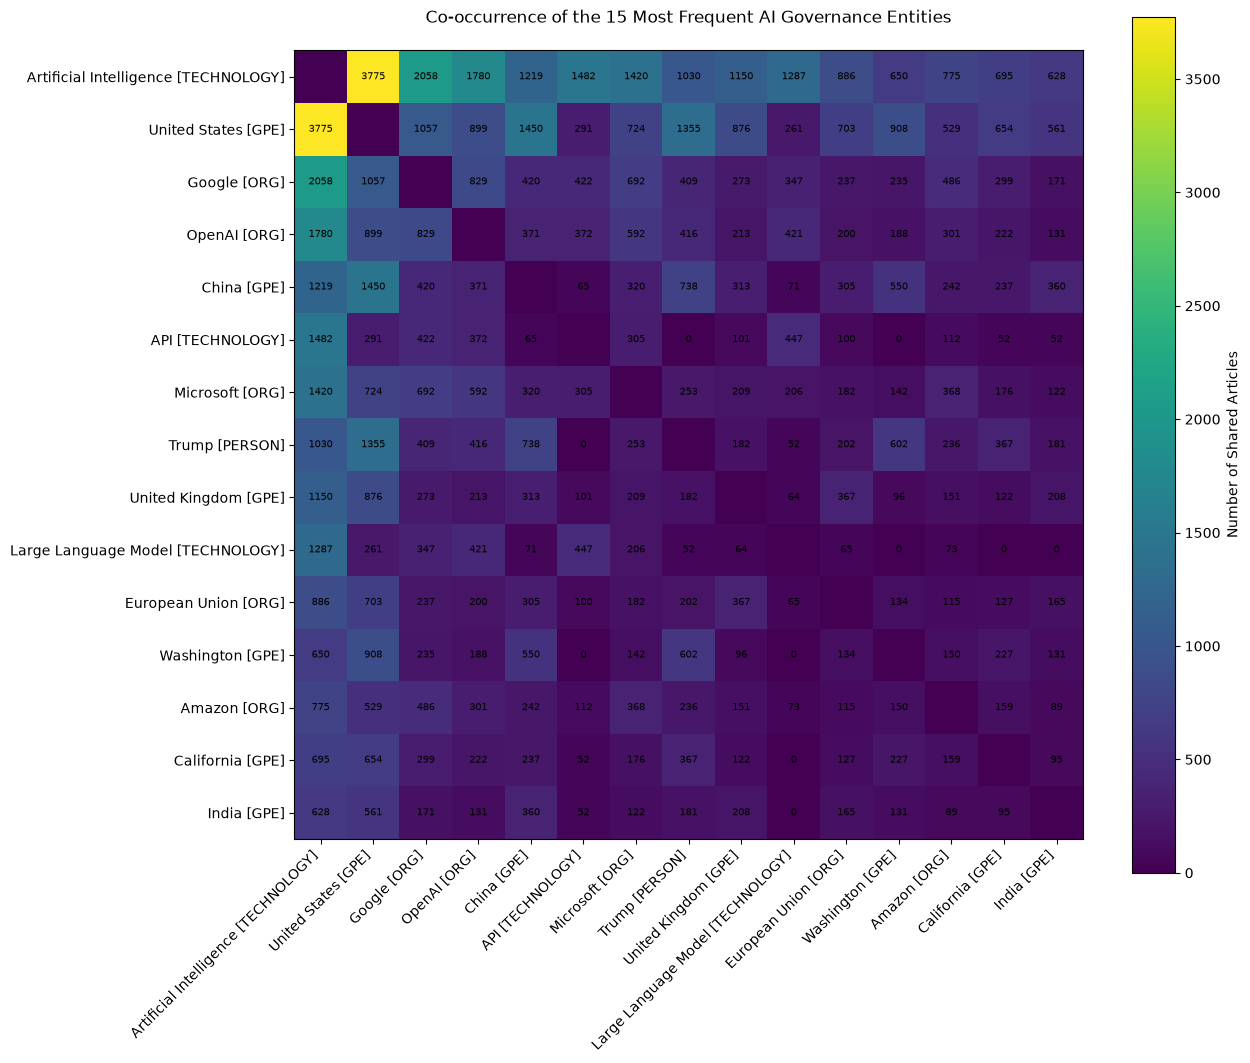

In [97]:
import matplotlib.pyplot as plt

# Use the same 15 high-frequency entities selected above
heatmap_data = cooccurrence_matrix.loc[
    top_node_labels,
    top_node_labels
]

fig, ax = plt.subplots(figsize=(13, 11))

image = ax.imshow(
    heatmap_data.values
)

# Axis labels
ax.set_xticks(range(len(top_node_labels)))
ax.set_yticks(range(len(top_node_labels)))

ax.set_xticklabels(
    top_node_labels,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(top_node_labels)

ax.set_title(
    "Co-occurrence of the 15 Most Frequent AI Governance Entities",
    pad=20
)

# Show the actual number of shared articles in each cell
for i in range(len(top_node_labels)):
    for j in range(len(top_node_labels)):

        value = heatmap_data.iloc[i, j]

        if i != j:
            ax.text(
                j,
                i,
                f"{value}",
                ha="center",
                va="center",
                fontsize=7
            )

fig.colorbar(
    image,
    ax=ax,
    label="Number of Shared Articles"
)

plt.tight_layout()
save_figure("entity_cooccurrence_heatmap")
plt.show()

#### Relation and Co-occurrence Summary

After applying the minimum entity-frequency threshold of 20 articles, 2,317 recurring entity-type combinations were retained for relation analysis. These entities formed 609,823 unique article-level co-occurrence relationships across 12,726 governance-related articles containing at least two retained entities.

The co-occurrence analysis shows that the most prominent relationships centre around Artificial Intelligence, major technology organisations and geopolitical actors. Particularly strong associations include Artificial Intelligence with the United States, Google, OpenAI and Microsoft, as well as the United States with China and Trump.

Because the complete co-occurrence network is highly dense, a minimum relationship strength of 50 shared articles is used for Knowledge Graph construction. This retains 4,282 stronger recurring relationships between 720 typed entities, while the complete co-occurrence information remains available separately.

Co-occurrence represents joint discussion within an article and should therefore be interpreted as an associative relationship rather than a causal or directional relationship.

### Knowledge Graph Construction and Analysis

In [98]:
# Save the completed relation-analysis outputs

COOCCURRENCE_PATH = (
    ENTITIES_DIR / "governance_cooccurrence_full.pkl"
)

GRAPH_EDGES_PATH = (
    KG_DIR / "governance_graph_edges.csv"
)

cooccurrence_df.to_pickle(COOCCURRENCE_PATH)

graph_edges.to_csv(
    GRAPH_EDGES_PATH,
    index=False
)

print(f"Full co-occurrence data saved to: {COOCCURRENCE_PATH}")
print(f"Filtered graph edges saved to: {GRAPH_EDGES_PATH}")

Full co-occurrence data saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\processed\entities\governance_cooccurrence_full.pkl
Filtered graph edges saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\knowledge_graph\governance_graph_edges.csv


#### Knowledge Graph Construction

The co-occurrence network is now converted into a graph following the schema defined at the beginning of this section.

Each node represents a normalized entity and is uniquely identified by its entity type and name. Edges represent undirected `CO_MENTIONED_WITH` relationships between entities that occur together in at least 50 governance-related articles. The edge weight corresponds to the number of articles in which the two entities co-occur.

This representation preserves entity types and relationship strength while avoiding causal interpretation of article-level co-occurrence.

In [99]:
import networkx as nx

G = nx.Graph()

# Article-frequency lookup for node attributes
frequency_lookup = (
    normalized_entity_frequency
    .set_index(["Entity", "Type"])["Article Frequency"]
    .to_dict()
)

# Add nodes and weighted co-occurrence relationships
for row in graph_edges.itertuples(index=False):

    node_1 = f"{row.Type_1}::{row.Entity_1}"
    node_2 = f"{row.Type_2}::{row.Entity_2}"

    G.add_node(
        node_1,
        name=row.Entity_1,
        entity_type=row.Type_1,
        article_frequency=int(
            frequency_lookup.get(
                (row.Entity_1, row.Type_1),
                0
            )
        )
    )

    G.add_node(
        node_2,
        name=row.Entity_2,
        entity_type=row.Type_2,
        article_frequency=int(
            frequency_lookup.get(
                (row.Entity_2, row.Type_2),
                0
            )
        )
    )

    G.add_edge(
        node_1,
        node_2,
        relation="CO_MENTIONED_WITH",
        weight=int(row.Cooccurrence_Count)
    )

print(f"Knowledge Graph nodes: {G.number_of_nodes():,}")
print(f"Knowledge Graph edges: {G.number_of_edges():,}")

Knowledge Graph nodes: 720
Knowledge Graph edges: 4,282


#### Knowledge Graph Network Metrics

Network metrics are calculated to identify entities that occupy important positions within the AI Governance Knowledge Graph.

Degree centrality measures how broadly an entity is connected across the network, while weighted degree also accounts for the frequency of co-occurrence relationships. PageRank provides an additional measure of structural importance by considering connections to other highly connected entities. Clustering indicates how strongly an entity's neighbouring nodes are interconnected.

In [100]:
# Calculate Knowledge Graph network metrics

degree_centrality = nx.degree_centrality(G)

weighted_degree = dict(
    G.degree(weight="weight")
)

pagerank = nx.pagerank(
    G,
    weight="weight"
)

clustering = nx.clustering(
    G,
    weight="weight"
)


network_metrics = pd.DataFrame(
    [
        {
            "Node": node,
            "Entity": data["name"],
            "Type": data["entity_type"],
            "Article Frequency": data["article_frequency"],
            "Degree": G.degree(node),
            "Degree Centrality": degree_centrality[node],
            "Weighted Degree": weighted_degree[node],
            "PageRank": pagerank[node],
            "Clustering Coefficient": clustering[node]
        }
        for node, data in G.nodes(data=True)
    ]
)

network_metrics = (
    network_metrics
    .sort_values(
        "PageRank",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    network_metrics.head(20)
)

,Node,Entity,Type,Article Frequency,Degree,Degree Centrality,Weighted Degree,PageRank,Clustering Coefficient
0,TECHNOLOGY::Artificial Intelligence,Artificial Intelligence,TECHNOLOGY,10735,633,0.880389,100470,0.129808,0.001139
1,GPE::United States,United States,GPE,4826,451,0.627260,66441,0.071665,0.001994
2,PERSON::Trump,Trump,PERSON,1496,211,0.293463,27196,0.025151,0.004531
3,ORG::Google,Google,ORG,2259,186,0.258693,25009,0.023403,0.005387
4,GPE::China,China,GPE,1674,189,0.262865,25496,0.021273,0.006059
5,ORG::OpenAI,OpenAI,ORG,1862,126,0.175243,17811,0.016202,0.008503
6,GPE::Washington,Washington,GPE,1016,128,0.178025,16233,0.013360,0.008405
7,ORG::Microsoft,Microsoft,ORG,1543,119,0.165508,14622,0.013249,0.008338
8,TECHNOLOGY::API,API,TECHNOLOGY,1610,94,0.130737,12083,0.012586,0.006705
9,GPE::United Kingdom,United Kingdom,GPE,1439,103,0.143255,11437,0.009801,0.009658


#### Knowledge Graph Centrality Findings

Artificial Intelligence is the most central node in the Knowledge Graph, with connections to 633 of the 719 other nodes and by far the highest weighted degree and PageRank. This reflects its broad presence across the governance-related corpus.

The United States is the second most central node, followed by entities such as Trump, Google, China, OpenAI and Microsoft. This indicates that AI Governance coverage frequently connects technological developments with major technology organisations and geopolitical actors.

The relatively low clustering coefficients of the most central nodes suggest that these entities often act as broad connectors between different parts of the network rather than belonging only to tightly interconnected local groups.

Centrality should be interpreted as prominence within the analysed media discourse rather than as causal influence. In particular, the very high centrality of Artificial Intelligence is partly expected because it is a general concept that occurs across many AI-related discussions.

#### Knowledge Graph Visualization

The complete Knowledge Graph contains 720 typed entities and 4,282 relationships, making a full visualization difficult to interpret.

For readability, the 40 entities with the highest PageRank scores are visualized together with the relationships between them. Node size reflects PageRank, node colour represents entity type, and edge width reflects co-occurrence strength.

The visualization is therefore intended as an interpretable view of the most structurally prominent part of the Knowledge Graph rather than a representation of every node.

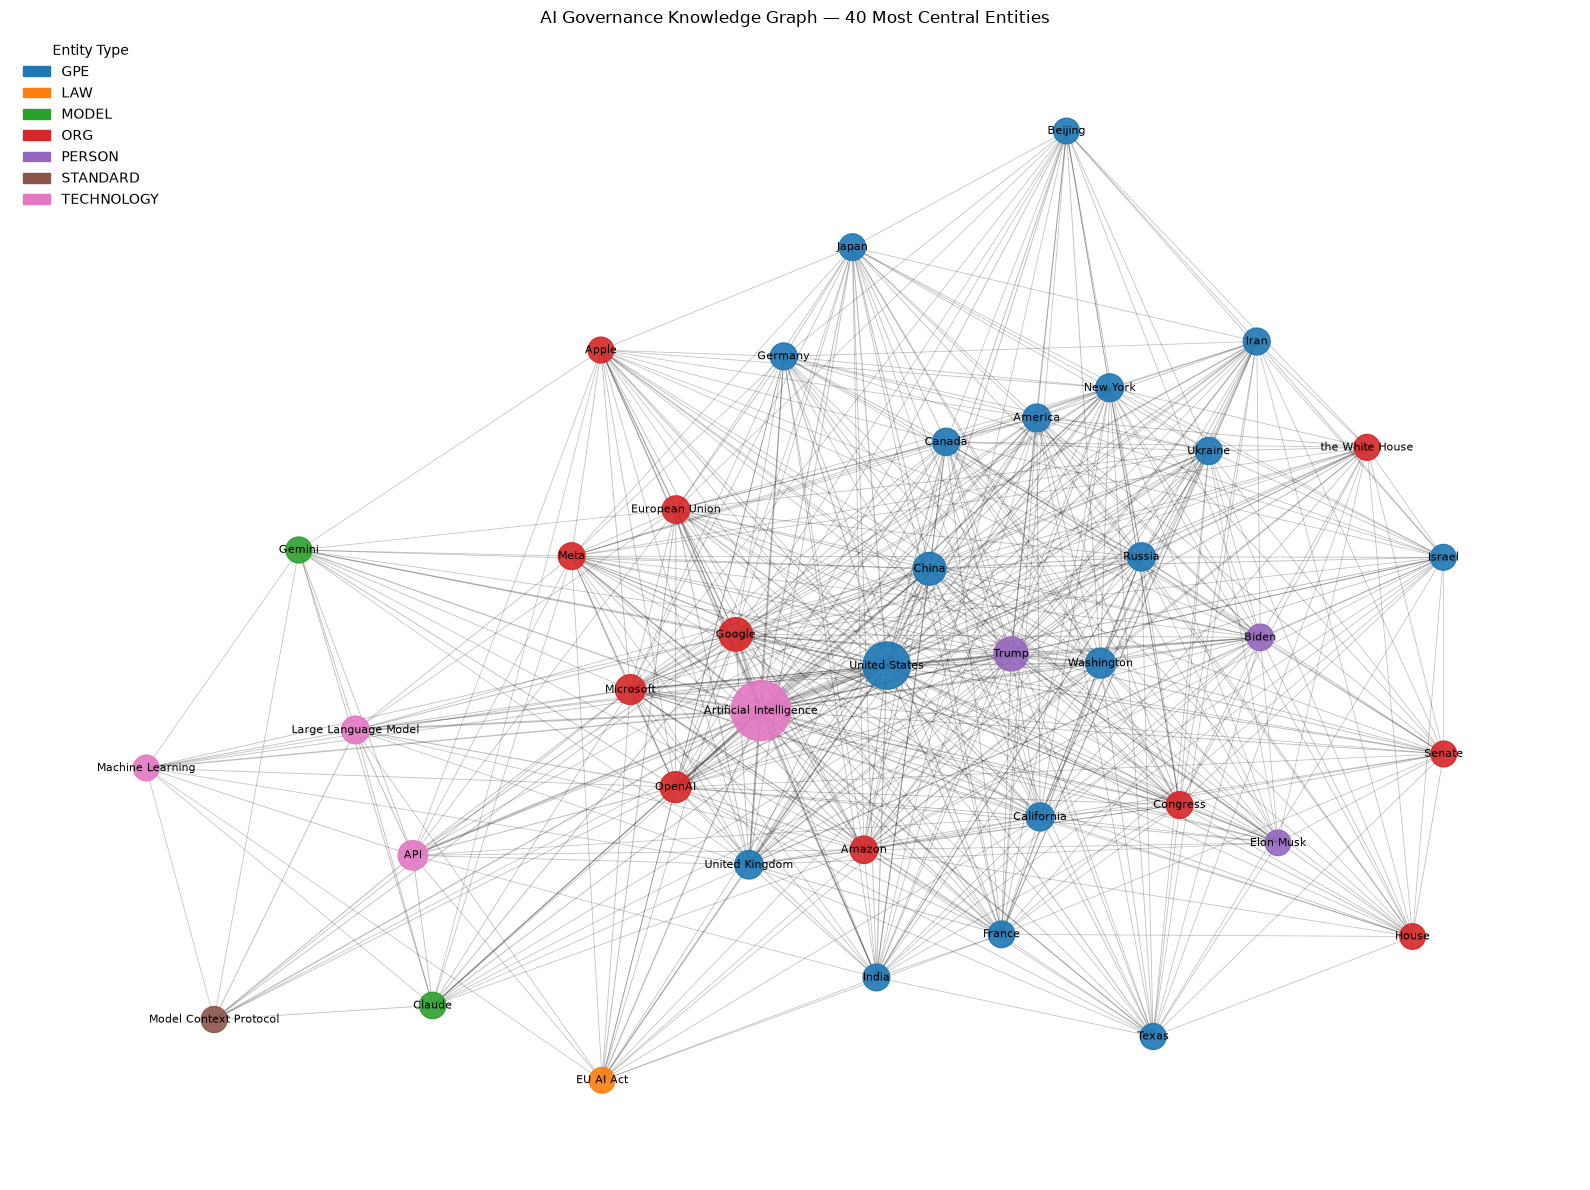

In [101]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Select the 40 most central entities by PageRank
TOP_N_NODES = 40

top_graph_nodes = (
    network_metrics
    .head(TOP_N_NODES)["Node"]
    .tolist()
)

# Create an induced subgraph containing only these nodes
visual_graph = G.subgraph(top_graph_nodes).copy()

# Reproducible force-directed layout
pos = nx.spring_layout(
    visual_graph,
    weight="weight",
    seed=42,
    k=0.8
)

# Node sizes based on PageRank
node_sizes = [
    300 + pagerank[node] * 12000
    for node in visual_graph.nodes()
]

# Assign colours by entity type
entity_types = sorted({
    visual_graph.nodes[node]["entity_type"]
    for node in visual_graph.nodes()
})

cmap = plt.get_cmap("tab10")

type_to_color = {
    entity_type: cmap(i % 10)
    for i, entity_type in enumerate(entity_types)
}

node_colors = [
    type_to_color[
        visual_graph.nodes[node]["entity_type"]
    ]
    for node in visual_graph.nodes()
]

# Scale edge width by co-occurrence strength
max_weight = max(
    data["weight"]
    for _, _, data in visual_graph.edges(data=True)
)

edge_widths = [
    0.5 + 2.5 * data["weight"] / max_weight
    for _, _, data in visual_graph.edges(data=True)
]

# Use readable entity names instead of internal node IDs
labels = {
    node: visual_graph.nodes[node]["name"]
    for node in visual_graph.nodes()
}

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    visual_graph,
    pos,
    width=edge_widths,
    alpha=0.25
)

nx.draw_networkx_nodes(
    visual_graph,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    alpha=0.9
)

nx.draw_networkx_labels(
    visual_graph,
    pos,
    labels=labels,
    font_size=8
)

legend_handles = [
    Patch(
        color=type_to_color[entity_type],
        label=entity_type
    )
    for entity_type in entity_types
]

plt.legend(
    handles=legend_handles,
    title="Entity Type",
    loc="upper left",
    frameon=False
)

plt.title(
    "AI Governance Knowledge Graph — 40 Most Central Entities"
)

plt.axis("off")
plt.tight_layout()
save_figure("knowledge_graph_top40")
plt.show()

#### Knowledge Graph Visualization Findings

The visualization confirms that the AI Governance network is highly interconnected, with Artificial Intelligence and the United States occupying particularly central positions.

Major technology organisations such as Google, OpenAI, Microsoft, Meta and Amazon form an important part of the central network, alongside geopolitical actors including China, the United Kingdom, Russia and the European Union.

The graph also shows connections between technological entities such as Large Language Model, API, Machine Learning, Claude and Gemini and broader political and organisational actors.

Because edges represent article-level co-occurrence, the visualization reflects patterns of joint discussion rather than causal or directional relationships.

In [102]:
import json

GRAPHML_PATH = (
    KG_DIR / "ai_governance_knowledge_graph.graphml"
)

METRICS_PATH = (
    KG_DIR / "ai_governance_network_metrics.csv"
)

SCHEMA_PATH = (
    KG_DIR / "ai_governance_knowledge_graph_schema.json"
)

# Save complete Knowledge Graph
nx.write_graphml(
    G,
    GRAPHML_PATH
)

# Save network metrics
network_metrics.to_csv(
    METRICS_PATH,
    index=False
)

# Save the schema defined at the beginning of the Knowledge Graph
# section together with the selected thresholds
KG_SCHEMA["parameters"] = {
    "minimum_entity_frequency": MIN_ENTITY_FREQUENCY,
    "minimum_cooccurrence": MIN_COOCCURRENCE
}

with open(
    SCHEMA_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        KG_SCHEMA,
        file,
        indent=2
    )

print(f"Knowledge Graph saved to: {GRAPHML_PATH}")
print(f"Network metrics saved to: {METRICS_PATH}")
print(f"Knowledge Graph schema saved to: {SCHEMA_PATH}")

Knowledge Graph saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\knowledge_graph\ai_governance_knowledge_graph.graphml
Network metrics saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\knowledge_graph\ai_governance_network_metrics.csv
Knowledge Graph schema saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\knowledge_graph\ai_governance_knowledge_graph_schema.json


### Structured Governance Relation Extraction

The entity co-occurrence network captures which entities are discussed together, but it does not indicate which AI Governance dimensions an entity is associated with.

As a complementary structured extraction step, normalized entities are linked to the Governance themes of the articles in which they occur. This produces explicit `ASSOCIATED_WITH_THEME` relations between entities and Security, Accountability, Bias/Fairness, or Regulation.

The relation weight represents the number of governance-related articles in which an entity appears together with the respective Governance theme. These relations provide a structured, reproducible layer beyond simple entity-to-entity co-occurrence.

In [103]:
from collections import Counter

theme_columns = {
    "security": "Security",
    "accountability": "Accountability",
    "bias_fairness": "Bias / Fairness",
    "regulation": "Regulation"
}

entity_theme_counter = Counter()

for row in governance_df.itertuples(index=False):

    active_themes = [
        theme_name
        for column_name, theme_name in theme_columns.items()
        if getattr(row, column_name)
    ]

    for entity_text, entity_type in row.entities_normalized:

        entity_key = (
            entity_text,
            entity_type
        )

        for theme in active_themes:
            entity_theme_counter[
                (entity_key, theme)
            ] += 1


entity_theme_relations = pd.DataFrame(
    [
        {
            "Entity": entity[0],
            "Type": entity[1],
            "Governance Theme": theme,
            "Article Count": count
        }
        for (entity, theme), count
        in entity_theme_counter.items()
    ]
)

entity_theme_relations = (
    entity_theme_relations
    .sort_values(
        "Article Count",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"Structured entity-theme relations: "
    f"{len(entity_theme_relations):,}"
)

display(
    entity_theme_relations.head(30)
)

Structured entity-theme relations: 270,855


,Entity,Type,Governance Theme,Article Count
0,Artificial Intelligence,TECHNOLOGY,Accountability,6531
1,Artificial Intelligence,TECHNOLOGY,Security,3570
2,United States,GPE,Security,2244
3,United States,GPE,Accountability,2174
4,Artificial Intelligence,TECHNOLOGY,Bias / Fairness,2159
5,Artificial Intelligence,TECHNOLOGY,Regulation,1344
6,API,TECHNOLOGY,Accountability,1322
7,Google,ORG,Accountability,1191
8,United States,GPE,Bias / Fairness,1162
9,Google,ORG,Security,1038


#### Structured Governance Relation Findings

The structured entity-theme relations provide an additional semantic layer beyond entity co-occurrence. Accountability is the most frequent Governance association for many central technology entities, including Artificial Intelligence, Google, API, Large Language Model and Microsoft.

Security is particularly prominent among geopolitical entities and political actors, including the United States, China, Trump, Russia and Washington. Regulation and Bias/Fairness occur less frequently among the strongest entity-theme associations.

These relations indicate thematic association within the same article and should not be interpreted as causal relationships.

In [104]:
# Create an enriched copy of the Knowledge Graph
# containing explicit Governance-theme relations

G_enriched = G.copy()

governance_themes = [
    "Security",
    "Accountability",
    "Bias / Fairness",
    "Regulation"
]

# Add Governance theme nodes
for theme in governance_themes:

    theme_node = f"THEME::{theme}"

    G_enriched.add_node(
        theme_node,
        name=theme,
        entity_type="GOVERNANCE_THEME"
    )


# Add entity-to-theme relations only for entities
# already retained in the Knowledge Graph
for row in entity_theme_relations.itertuples(index=False):

    entity_node = f"{row.Type}::{row.Entity}"

    if entity_node in G:

        theme_node = f"THEME::{row._2}"

        G_enriched.add_edge(
            entity_node,
            theme_node,
            relation="ASSOCIATED_WITH_THEME",
            weight=int(row._3)
        )


print(
    f"Enriched Knowledge Graph nodes: "
    f"{G_enriched.number_of_nodes():,}"
)

print(
    f"Enriched Knowledge Graph edges: "
    f"{G_enriched.number_of_edges():,}"
)

Enriched Knowledge Graph nodes: 724
Enriched Knowledge Graph edges: 7,139


In [105]:
ENRICHED_GRAPH_PATH = (
    KG_DIR / "ai_governance_knowledge_graph_enriched.graphml"
)

ENTITY_THEME_PATH = (
    KG_DIR / "ai_governance_entity_theme_relations.csv"
)

# Save enriched Knowledge Graph
nx.write_graphml(
    G_enriched,
    ENRICHED_GRAPH_PATH
)

# Save structured entity-theme relations
entity_theme_relations.to_csv(
    ENTITY_THEME_PATH,
    index=False
)

print(f"Enriched Knowledge Graph saved to: {ENRICHED_GRAPH_PATH}")
print(f"Entity-theme relations saved to: {ENTITY_THEME_PATH}")

Enriched Knowledge Graph saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\knowledge_graph\ai_governance_knowledge_graph_enriched.graphml
Entity-theme relations saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\knowledge_graph\ai_governance_entity_theme_relations.csv


### LLM-Based Relation Extraction

Co-occurrence and theme association show *that* entities are discussed together, but not *how* they are related. To add explicit, typed relations, a structured extraction with **LangExtract** and a Google Gemini model is applied.

- **Relation types:** the LLM may only use the directed relation types defined in the Knowledge Graph schema (`REGULATES`, `INVESTIGATES`, `FINES`, `SUES`, `COMPLIES_WITH`, `ADOPTS`, `PROPOSES`, `DEVELOPS`, `PARTNERS_WITH`). Few-shot examples illustrate each relation.
- **Traceability:** LangExtract grounds every extraction in the source text. For each relation, the exact evidence span, the `record_id` and the publication date are stored, which keeps the relations traceable to the AI Media Dataset and supports time-aware questions in Stage 3.
- **Sample:** Calling an LLM for all Governance articles would be slow and costly. The extraction is therefore applied to a stratified sample of articles that mention at least one law, regulator or standard, drawn evenly across all months of the observation period. Only the title and the beginning of each article are used, where the main statements are usually made.
- **Normalization:** extracted subjects and objects are normalized with the same alias and type rules as the NER entities, so that they link to the nodes of the co-occurrence graph.
- **Reproducibility:** all LLM responses are cached. Re-running the notebook reuses the cached results instead of calling the API again; without an API key, only the cached results are used.

In [106]:
import hashlib
import os
import textwrap

import logging

import langextract as lx
from dotenv import load_dotenv

# LangExtract logs an alignment warning for every call; only show errors
logging.getLogger("absl").setLevel(logging.ERROR)

# Relation and entity types are taken from the Knowledge Graph schema
RELATION_TYPES = [
    relation
    for relation, spec in KG_SCHEMA["relation_types"].items()
    if spec["source"] == "LLM extraction"
]

RELATION_ENTITY_TYPES = [
    node_type
    for node_type in KG_SCHEMA["node_types"]
    if node_type != "GOVERNANCE_THEME"
]

RELATION_MODEL_ID = "gemini-3.5-flash-lite"
RELATION_INPUT_CHARS = 3000

RELATION_PROMPT = textwrap.dedent(f"""
    Extract explicit AI-governance relations between named entities from the article.
    Only extract a relation if the text states it directly. Use one of these predicates:
    {", ".join(RELATION_TYPES)}.
    For extraction_text, copy the exact words from the article that state the relation (no paraphrasing).
    In the attributes, give the subject and object as short canonical names and their types,
    using one of: {", ".join(RELATION_ENTITY_TYPES)}.
    If the article contains no such relation, return no extractions.
""").strip()


def relation_example(text, subject, subject_type, predicate, obj, object_type):
    return lx.data.Extraction(
        extraction_class="relation",
        extraction_text=text,
        attributes={
            "subject": subject,
            "subject_type": subject_type,
            "predicate": predicate,
            "object": obj,
            "object_type": object_type
        }
    )


RELATION_EXAMPLES = [
    lx.data.ExampleData(
        text=(
            "The European Commission fined Meta 200 million euros under the Digital Markets Act. "
            "Meta said it would appeal. Separately, OpenAI and Microsoft expanded their partnership, "
            "and OpenAI released GPT-5 to enterprise customers."
        ),
        extractions=[
            relation_example("The European Commission fined Meta", "European Commission", "REGULATOR", "FINES", "Meta", "ORG"),
            relation_example("fined Meta 200 million euros under the Digital Markets Act", "Digital Markets Act", "LAW", "REGULATES", "Meta", "ORG"),
            relation_example("OpenAI and Microsoft expanded their partnership", "OpenAI", "ORG", "PARTNERS_WITH", "Microsoft", "ORG"),
            relation_example("OpenAI released GPT-5", "OpenAI", "ORG", "DEVELOPS", "GPT-5", "MODEL")
        ]
    ),
    lx.data.ExampleData(
        text=(
            "The FTC opened an investigation into Character.AI over child safety. "
            "Anthropic said its models are aligned with the NIST AI RMF, and the EU adopted the AI Act in 2024. "
            "California lawmakers proposed a bill on frontier models, and authors sued OpenAI over training data."
        ),
        extractions=[
            relation_example("The FTC opened an investigation into Character.AI", "FTC", "REGULATOR", "INVESTIGATES", "Character.AI", "ORG"),
            relation_example("Anthropic said its models are aligned with the NIST AI RMF", "Anthropic", "ORG", "COMPLIES_WITH", "NIST AI RMF", "STANDARD"),
            relation_example("the EU adopted the AI Act", "European Union", "ORG", "ADOPTS", "EU AI Act", "LAW"),
            relation_example("California lawmakers proposed a bill on frontier models", "California", "GPE", "PROPOSES", "frontier model bill", "LAW"),
            relation_example("authors sued OpenAI", "authors", "PERSON", "SUES", "OpenAI", "ORG")
        ]
    )
]

# Fingerprint of the extraction setup: cached results are only reused
# if model, prompt, examples and input length are unchanged
RELATION_CONFIG_ID = hashlib.sha256(
    json.dumps(
        {
            "model": RELATION_MODEL_ID,
            "prompt": RELATION_PROMPT,
            "examples": [
                [example.text, [(e.extraction_text, e.attributes) for e in example.extractions]]
                for example in RELATION_EXAMPLES
            ],
            "input_chars": RELATION_INPUT_CHARS
        },
        sort_keys=True
    ).encode("utf-8")
).hexdigest()[:12]

# The API key is read from the local .env file, which is excluded from Git
load_dotenv(PROJECT_ROOT / ".env")
GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")

print(f"Relation types: {', '.join(RELATION_TYPES)}")
print(f"Model: {RELATION_MODEL_ID}")
print(f"Extraction configuration: {RELATION_CONFIG_ID}")
print(f"API key available: {GEMINI_API_KEY is not None}")

Relation types: REGULATES, INVESTIGATES, FINES, SUES, COMPLIES_WITH, ADOPTS, PROPOSES, DEVELOPS, PARTNERS_WITH
Model: gemini-3.5-flash-lite
Extraction configuration: 6889dc5faafa
API key available: True


In [107]:
# Stratified sample of articles that mention at least one law,
# regulator or standard, drawn evenly across all months
RELATION_SAMPLE_PER_MONTH = 17
GOVERNANCE_ANCHOR_TYPES = {"LAW", "REGULATOR", "STANDARD"}

has_governance_anchor = governance_df["entities_normalized"].apply(
    lambda entities: any(
        entity_type in GOVERNANCE_ANCHOR_TYPES
        for _, entity_type in entities
    )
)

in_stage1_period = (
    (governance_df["date"] >= "2024-09-01")
    & (governance_df["date"] <= "2026-08-31")
)

relation_candidates = governance_df.loc[
    has_governance_anchor & in_stage1_period,
    ["record_id", "title", "date", "domain", "url", "content_text"]
].copy()

relation_candidates["month"] = relation_candidates["date"].dt.to_period("M")

relation_sample = (
    relation_candidates
    .sample(frac=1, random_state=42)
    .groupby("month")
    .head(RELATION_SAMPLE_PER_MONTH)
    .sort_values(["date", "record_id"])
    .reset_index(drop=True)
)

relation_sample_summary = pd.DataFrame({
    "Metric": [
        "Governance articles",
        "Articles mentioning a law, regulator or standard",
        "Months covered",
        "Articles per month (maximum)",
        "Articles in extraction sample"
    ],
    "Result": [
        len(governance_df),
        len(relation_candidates),
        relation_sample["month"].nunique(),
        RELATION_SAMPLE_PER_MONTH,
        len(relation_sample)
    ]
})

display(relation_sample_summary)

,Metric,Result
0,Governance articles,12946
1,"Articles mentioning a law, regulator or standard",4180
2,Months covered,24
3,Articles per month (maximum),17
4,Articles in extraction sample,408


In [108]:
import time

RELATIONS_CACHE_PATH = ENTITIES_DIR / "governance_relations_langextract.jsonl"
MIN_SECONDS_BETWEEN_CALLS = 4
MAX_ATTEMPTS = 4
MAX_CONSECUTIVE_FAILURES = 3


def load_relation_cache():
    """Load cached LLM responses created with the current configuration."""
    cache = {}

    if RELATIONS_CACHE_PATH.exists():
        with open(RELATIONS_CACHE_PATH, encoding="utf-8") as file:
            for line in file:
                entry = json.loads(line)

                if entry.get("config_id") == RELATION_CONFIG_ID:
                    cache[entry["record_id"]] = entry

    return cache


def relation_input_text(row):
    """Title and beginning of the article."""
    return f"{row.title}. {row.content_text}"[:RELATION_INPUT_CHARS]


relation_cache = load_relation_cache()

pending_relations = relation_sample.loc[
    ~relation_sample["record_id"].isin(relation_cache)
]

print(f"Cached articles: {len(relation_cache):,}")
print(f"Articles requiring extraction: {len(pending_relations):,}")

if len(pending_relations) > 0 and GEMINI_API_KEY is None:
    print(
        "No GEMINI_API_KEY found in .env - only cached results are used."
    )

elif len(pending_relations) > 0:

    start_time = time.perf_counter()
    consecutive_failures = 0

    with open(RELATIONS_CACHE_PATH, "a", encoding="utf-8") as cache_file:

        for processed, row in enumerate(
            pending_relations.itertuples(index=False),
            start=1
        ):

            call_started = time.perf_counter()
            result = None
            blocked = False

            for attempt in range(MAX_ATTEMPTS):
                try:
                    result = lx.extract(
                        text_or_documents=relation_input_text(row),
                        prompt_description=RELATION_PROMPT,
                        examples=RELATION_EXAMPLES,
                        model_id=RELATION_MODEL_ID,
                        api_key=GEMINI_API_KEY,
                        max_char_buffer=RELATION_INPUT_CHARS + 500,
                        max_workers=1,
                        show_progress=False
                    )
                    break

                except Exception as error:
                    # Articles rejected by the model's safety filter (e.g. reports
                    # on deepfake abuse) fail permanently - retrying does not help
                    if "blocked" in str(error).lower():
                        blocked = True
                        print(f"Record {row.record_id} blocked by the model's safety filter - skipped")
                        break

                    wait_seconds = 30 * 2 ** attempt
                    print(
                        f"API error for record {row.record_id} "
                        f"({type(error).__name__}); retrying in {wait_seconds}s"
                    )
                    time.sleep(wait_seconds)

            if result is None and not blocked:
                # Temporary errors: skip the article for now (it is retried on the next
                # run) and stop only if several articles in a row fail, e.g. due to quota
                consecutive_failures += 1
                print(f"Record {row.record_id} skipped after {MAX_ATTEMPTS} attempts")

                if consecutive_failures >= MAX_CONSECUTIVE_FAILURES:
                    print(
                        "Repeated API errors - extraction stopped. "
                        "Run this cell again later to continue."
                    )
                    break

                continue

            consecutive_failures = 0

            entry = {
                "record_id": int(row.record_id),
                "config_id": RELATION_CONFIG_ID,
                "model": RELATION_MODEL_ID,
                "status": "blocked" if blocked else "ok",
                "extractions": [] if blocked else [
                    {
                        "text": extraction.extraction_text,
                        "start": (
                            extraction.char_interval.start_pos
                            if extraction.char_interval else None
                        ),
                        "end": (
                            extraction.char_interval.end_pos
                            if extraction.char_interval else None
                        ),
                        "attributes": extraction.attributes or {}
                    }
                    for extraction in result.extractions
                ]
            }

            cache_file.write(json.dumps(entry, ensure_ascii=False) + "\n")
            cache_file.flush()
            relation_cache[entry["record_id"]] = entry

            if processed % 50 == 0 or processed == len(pending_relations):
                elapsed = time.perf_counter() - start_time
                print(
                    f"{processed:,} / {len(pending_relations):,} articles | "
                    f"{elapsed / 60:.1f} min"
                )

            # Stay within the API rate limit
            time.sleep(
                max(0, MIN_SECONDS_BETWEEN_CALLS - (time.perf_counter() - call_started))
            )

print(
    f"Articles with extraction results: "
    f"{relation_sample['record_id'].isin(relation_cache).sum():,} / {len(relation_sample):,}"
)

Cached articles: 408
Articles requiring extraction: 0
Articles with extraction results: 408 / 408


In [109]:
def normalize_relation_entity(name, entity_type):
    """Apply the same alias and type rules as for the NER entities."""
    canonical = ENTITY_ALIASES.get(name.strip(), name.strip())
    return canonical, ENTITY_TYPE_OVERRIDES.get(canonical, entity_type)


sample_metadata = relation_sample.set_index("record_id")

relation_rows = []

for record_id, entry in relation_cache.items():

    if record_id not in sample_metadata.index:
        continue

    for extraction in entry["extractions"]:

        attributes = extraction["attributes"]

        subject, subject_type = normalize_relation_entity(
            str(attributes.get("subject", "")),
            str(attributes.get("subject_type", "")).upper()
        )

        obj, object_type = normalize_relation_entity(
            str(attributes.get("object", "")),
            str(attributes.get("object_type", "")).upper()
        )

        relation_rows.append({
            "record_id": record_id,
            "date": sample_metadata.loc[record_id, "date"],
            "domain": sample_metadata.loc[record_id, "domain"],
            "subject": subject,
            "subject_type": subject_type,
            "predicate": str(attributes.get("predicate", "")).upper(),
            "object": obj,
            "object_type": object_type,
            "evidence": extraction["text"],
            "char_start": extraction["start"],
            "char_end": extraction["end"]
        })

raw_relations = pd.DataFrame(
    relation_rows,
    columns=[
        "record_id", "date", "domain", "subject", "subject_type", "predicate",
        "object", "object_type", "evidence", "char_start", "char_end"
    ]
)

# Keep relations that follow the schema
valid_relation = (
    raw_relations["predicate"].isin(RELATION_TYPES)
    & raw_relations["subject_type"].isin(RELATION_ENTITY_TYPES)
    & raw_relations["object_type"].isin(RELATION_ENTITY_TYPES)
    & raw_relations["subject"].str.len().gt(1)
    & raw_relations["object"].str.len().gt(1)
    & (raw_relations["subject"] != raw_relations["object"])
)

extracted_relations = (
    raw_relations
    .loc[valid_relation]
    .drop_duplicates(["record_id", "subject", "predicate", "object"])
    .sort_values(["date", "record_id"])
    .reset_index(drop=True)
)

relation_extraction_summary = pd.DataFrame({
    "Metric": [
        "Articles processed",
        "Articles blocked by the model's safety filter",
        "Articles with at least one relation",
        "Raw extractions",
        "Relations following the schema",
        "Relations grounded in the source text (%)",
        "Distinct entities in relations"
    ],
    "Result": [
        int(relation_sample["record_id"].isin(relation_cache).sum()),
        sum(
            entry.get("status") == "blocked"
            for record_id, entry in relation_cache.items()
            if record_id in sample_metadata.index
        ),
        extracted_relations["record_id"].nunique(),
        len(raw_relations),
        len(extracted_relations),
        round(extracted_relations["char_start"].notna().mean() * 100, 1)
        if len(extracted_relations) else 0,
        len(
            set(zip(extracted_relations["subject"], extracted_relations["subject_type"]))
            | set(zip(extracted_relations["object"], extracted_relations["object_type"]))
        )
    ]
})

display(relation_extraction_summary)

print("\nRelations per type:")
display(
    extracted_relations["predicate"]
    .value_counts()
    .rename_axis("Relation")
    .reset_index(name="Relations")
)

print("\nMost frequent extracted relations:")
display(
    extracted_relations
    .groupby(["subject", "predicate", "object"])
    .agg(Articles=("record_id", "nunique"))
    .sort_values("Articles", ascending=False)
    .head(20)
    .reset_index()
)

,Metric,Result
0,Articles processed,408.0
1,Articles blocked by the model's safety filter,1.0
2,Articles with at least one relation,104.0
3,Raw extractions,165.0
4,Relations following the schema,162.0
5,Relations grounded in the source text (%),100.0
6,Distinct entities in relations,173.0



Relations per type:


,Relation,Relations
0,DEVELOPS,79
1,REGULATES,33
2,PARTNERS_WITH,16
3,PROPOSES,14
4,ADOPTS,8
5,SUES,4
6,COMPLIES_WITH,4
7,INVESTIGATES,3
8,FINES,1



Most frequent extracted relations:


,subject,predicate,object,Articles
0,Anthropic,DEVELOPS,Claude,6
1,Anthropic,DEVELOPS,Model Context Protocol,4
2,European Union,ADOPTS,EU AI Act,4
3,OpenAI,DEVELOPS,ChatGPT,4
4,OpenAI,DEVELOPS,Sora,3
5,EU AI Act,REGULATES,general-purpose AI models,2
6,Anthropic,DEVELOPS,Mythos 5,2
7,EU AI Act,REGULATES,artificial intelligence,2
8,EU AI Act,REGULATES,Artificial Intelligence,2
9,AMD,PARTNERS_WITH,OpenAI,1


In [110]:
# Directed multigraph: several relations (and several source articles)
# can exist between the same two entities
G_relations = nx.MultiDiGraph()

for row in extracted_relations.itertuples(index=False):

    subject_node = f"{row.subject_type}::{row.subject}"
    object_node = f"{row.object_type}::{row.object}"

    G_relations.add_node(subject_node, name=row.subject, entity_type=row.subject_type)
    G_relations.add_node(object_node, name=row.object, entity_type=row.object_type)

    G_relations.add_edge(
        subject_node,
        object_node,
        relation=row.predicate,
        record_id=int(row.record_id),
        date=row.date.strftime("%Y-%m-%d"),
        evidence=row.evidence
    )

# Share of relation entities that also exist in the co-occurrence graph
linked_nodes = sum(node in G for node in G_relations.nodes)

RELATION_GRAPH_PATH = KG_DIR / "ai_governance_relation_graph.graphml"
EXTRACTED_RELATIONS_PATH = KG_DIR / "ai_governance_extracted_relations.csv"

nx.write_graphml(G_relations, RELATION_GRAPH_PATH)

extracted_relations.assign(
    date=pd.to_datetime(extracted_relations["date"]).dt.strftime("%Y-%m-%d")
).to_csv(EXTRACTED_RELATIONS_PATH, index=False)

print(f"Relation graph nodes: {G_relations.number_of_nodes():,}")
print(f"Relation graph edges: {G_relations.number_of_edges():,}")
print(
    f"Relation entities also in the co-occurrence graph: "
    f"{linked_nodes:,} ({linked_nodes / max(G_relations.number_of_nodes(), 1):.1%})"
)
print(f"Relation graph saved to: {RELATION_GRAPH_PATH}")
print(f"Extracted relations saved to: {EXTRACTED_RELATIONS_PATH}")

Relation graph nodes: 173
Relation graph edges: 162
Relation entities also in the co-occurrence graph: 40 (23.1%)
Relation graph saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\knowledge_graph\ai_governance_relation_graph.graphml
Extracted relations saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\knowledge_graph\ai_governance_extracted_relations.csv


#### Relation Extraction Findings

The extraction was applied to 408 articles (up to 17 per month, September 2024 – August 2026). One article, a report on sexualised deepfakes, was rejected by the model's safety filter. In 104 articles (25%) the model found at least one explicit relation. In total, 162 relations following the schema were extracted, all of them grounded in the source text.

- **Relation types:** `DEVELOPS` dominates (79 relations, e.g. *Anthropic → Claude*, *OpenAI → Sora*), followed by `REGULATES` (33, e.g. *EU AI Act → general-purpose AI models*, *European Commission → ChatGPT*), `PARTNERS_WITH` (16) and `PROPOSES` (14). Enforcement relations are rare (`SUES` 4, `INVESTIGATES` 3, `FINES` 1): at least at the beginning of articles, media coverage reports product releases and new rules far more often than concrete enforcement actions.
- **Quality:** a manual review of 40 randomly sampled relations found 29 (73%) correct and supported by the evidence, 6 (15%) factually plausible but only weakly supported by the cited text (e.g. *European Union –ADOPTS→ EU AI Act* from "including the EU AI Act"), and 5 (12%) incorrect, mostly because of a wrong relation type or direction (e.g. *California –REGULATES→ AI Transparency Act* instead of `ADOPTS`).
- **Link to the co-occurrence graph:** only 40 of the 173 relation entities (23%) also appear in the co-occurrence graph. Extracted relations often involve specific models, products and laws (e.g. *Sora*, *RAISE Act*) that are mentioned too rarely to pass the frequency thresholds of the co-occurrence graph. The relation graph therefore complements rather than duplicates the co-occurrence graph.

For Stage 3, the extracted relations provide dated, source-linked facts that can be retrieved alongside text passages. Their error rate should be taken into account when evaluating graph-enhanced answers.

### Topic Modeling

To identify recurring thematic structures within the AI Governance corpus, topic modeling is applied to the governance-related article text.

A TF-IDF representation is combined with Non-negative Matrix Factorization (NMF). This approach provides interpretable topic-word distributions and is well suited to identifying recurring themes in a large text corpus.

Generic AI terminology and common English stop words are removed so that the resulting topics reflect more specific Governance-related content rather than broad references to artificial intelligence.

#### Text Preparation for Topic Modeling

Before topic modeling, the article text is preprocessed with spaCy: it is tokenized, every token is reduced to its lemma (e.g. *regulations* → *regulation*, *agents* → *agent*), and stop words, punctuation, numbers and very short tokens are removed. Lemmatization merges inflected forms of the same word, which reduces the vocabulary and makes topics easier to interpret.

Lemmatization is applied only for topic modeling. Named-entity extraction uses the original text, because the exact surface form of names, acronyms and products is analytically meaningful there.

The lemmatized text is then transformed into a TF-IDF document-term matrix. A small set of highly generic corpus terms is removed in addition, and unigrams and bigrams are retained so that both individual concepts and meaningful multi-word expressions can contribute to the topic model. Very rare terms and terms appearing in most documents are excluded to improve interpretability.

In [111]:
LEMMA_PATH = CORPUS_DIR / "governance_text_lemmatized.pkl.gz"

LEMMA_CONFIG = {
    "spacy_model": NER_CONFIG["spacy_model"],
    "input": "title + content_text",
    "token_filter": "alphabetic, no stop words, at least 3 characters, lowercase lemma"
}

# Tagger and lemmatizer are required; parser and NER are not needed here
nlp_lemma = spacy.load("en_core_web_sm", disable=["parser", "ner"])
nlp_lemma.max_length = nlp.max_length


def lemmatize(doc):
    return " ".join(
        token.lemma_.lower()
        for token in doc
        if token.is_alpha and not token.is_stop and len(token) > 2
    )


lemma_cache = pd.read_pickle(LEMMA_PATH) if LEMMA_PATH.exists() else None

# Reuse the cache only for the same configuration and the same articles
if lemma_cache is not None and (
    lemma_cache.attrs.get("lemma_config") != LEMMA_CONFIG
    or set(lemma_cache["record_id"]) != set(governance_df["record_id"])
):
    print("Existing lemmatization cache is outdated and is recomputed.")
    lemma_cache = None

if lemma_cache is None:

    lemma_texts = (
        governance_df["title"].fillna("")
        + ". "
        + governance_df["content_text"].fillna("")
    )

    lemmatized_texts = []
    start_time = time.perf_counter()

    for processed, doc in enumerate(
        nlp_lemma.pipe(lemma_texts, batch_size=16),
        start=1
    ):
        lemmatized_texts.append(lemmatize(doc))

        if processed % 2000 == 0 or processed == len(lemma_texts):
            print(
                f"{processed:,} / {len(lemma_texts):,} articles | "
                f"{(time.perf_counter() - start_time) / 60:.1f} min"
            )

    lemma_cache = pd.DataFrame({
        "record_id": governance_df["record_id"].values,
        "text_lemmatized": lemmatized_texts
    })
    lemma_cache.attrs["lemma_config"] = LEMMA_CONFIG
    lemma_cache.to_pickle(LEMMA_PATH, compression="gzip")

else:
    print("Lemmatized texts loaded from cache.")

governance_df["text_lemmatized"] = governance_df["record_id"].map(
    dict(zip(lemma_cache["record_id"], lemma_cache["text_lemmatized"]))
)

# spaCy lemmatizes "data" to the Latin singular "datum"; in this corpus
# the word always refers to data, so the original form is restored
governance_df["text_lemmatized"] = governance_df["text_lemmatized"].str.replace(
    r"\bdatum\b", "data", regex=True
)

# Example and effect of preprocessing
example = governance_df.iloc[0]
original_tokens = (example["title"] + ". " + example["content_text"]).split()

print(f"\nOriginal text (first 40 tokens):\n{' '.join(original_tokens[:40])}")
print(f"\nLemmatized text (first 40 tokens):\n{' '.join(example['text_lemmatized'].split()[:40])}")

print(
    f"\nAverage tokens per article: "
    f"{(governance_df['title'] + ' ' + governance_df['content_text']).str.split().str.len().mean():,.0f} "
    f"(original) vs. {governance_df['text_lemmatized'].str.split().str.len().mean():,.0f} (lemmatized)"
)

Lemmatized texts loaded from cache.



Original text (first 40 tokens):
Optimizing Sustainable Construction with Smart Tools. A new study is shedding light on the latest innovations in sustainable construction, using a blend of advanced optimization tools and hands-on experimental methods. By focusing on practical solutions, the research addresses key challenges

Lemmatized text (first 40 tokens):
optimize sustainable construction smart tools new study shed light late innovation sustainable construction blend advanced optimization tool hand experimental method focus practical solution research address key challenge build sustainably lab base finding provide vital data need fine tune tool create



Average tokens per article: 1,848 (original) vs. 1,021 (lemmatized)


In [112]:
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

# Lemmatized title and article content
topic_texts = governance_df["text_lemmatized"]

# Generic and corpus-specific terms that do not help distinguish topics
custom_stop_words = set(ENGLISH_STOP_WORDS).union({
    # Generic AI / article language
    "ai",
    "artificial",
    "intelligence",
    "article",
    "said",
    "says",
    "say",
    "new",
    "use",
    "used",
    "using",
    "people",
    "think",
    "like",
    "just",
    "going",
    "go",
    "really",
    "don",
    "know",
    "things",
    "thing",
    "actually",

    # Source / website boilerplate
    "email",
    "emails",
    "address",
    "site",
    "owner",
    "submit",
    "tfn",

    # Source-specific boilerplate
    "kpmg",
    "llp",
    "kpmg llp",
    "kpmg global",
    "gitlab",
    "fortune",
    "veterans",
    "team",
    "teams"
})

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=list(custom_stop_words),
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.85,
    max_features=15000,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]{2,}\b"
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    topic_texts
)

feature_names = tfidf_vectorizer.get_feature_names_out()

print(
    f"Documents included: "
    f"{tfidf_matrix.shape[0]:,}"
)

print(
    f"TF-IDF features retained: "
    f"{tfidf_matrix.shape[1]:,}"
)

print(
    f"Matrix density: "
    f"{tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1]):.4%}"
)

C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\.venv\Lib\site-packages\sklearn\feature_extraction\text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['global'] not in stop_words.
  warnings.warn(


Documents included: 12,946
TF-IDF features retained: 15,000
Matrix density: 3.4566%


#### Topic Model Comparison

To determine an appropriate number of topics, NMF models with 6, 8 and 10 topics are compared.

The models are evaluated using reconstruction error together with the interpretability and distinctiveness of their topic-word distributions. Reconstruction error alone is not used for model selection because adding more topics generally improves model fit while potentially reducing interpretability.

In [113]:
from sklearn.decomposition import NMF
import pandas as pd

TOPIC_OPTIONS = [6, 8, 10]
TOP_WORDS = 12

topic_model_results = []

for n_topics in TOPIC_OPTIONS:

    model = NMF(
        n_components=n_topics,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    document_topics = model.fit_transform(
        tfidf_matrix
    )

    for topic_idx, topic_weights in enumerate(model.components_):

        top_indices = topic_weights.argsort()[-TOP_WORDS:][::-1]

        top_terms = [
            feature_names[index]
            for index in top_indices
        ]

        topic_model_results.append({
            "Model": f"{n_topics} Topics",
            "Topic": topic_idx + 1,
            "Top Terms": ", ".join(top_terms),
            "Reconstruction Error": round(
                model.reconstruction_err_,
                2
            )
        })

topic_comparison_df = pd.DataFrame(
    topic_model_results
)

display(topic_comparison_df)

,Model,Topic,Top Terms,Reconstruction Error
0,6 Topics,1,"business, company, customer, technology, marke...",106.86
1,6 Topics,2,"agent, mcp, agentic, tool, enterprise, api, co...",106.86
2,6 Topics,3,"veteran, software, intelligent orchestration, ...",106.86
3,6 Topics,4,"trump, china, government, president, year, pol...",106.86
4,6 Topics,5,"model, content, user, human, image, search, go...",106.86
5,6 Topics,6,"data, security, cloud, risk, model, organizati...",106.86
6,8 Topics,1,"business, company, technology, customer, marke...",106.27
7,8 Topics,2,"agent, agentic, mcp, tool, workflow, context, ...",106.27
8,8 Topics,3,"veteran, software, intelligent orchestration, ...",106.27
9,8 Topics,4,"trump, china, government, president, year, pol...",106.27


#### Topic Number Selection

Models with 6, 8 and 10 topics were compared based on reconstruction error and qualitative interpretability.

Although reconstruction error decreases slightly as the number of topics increases, the 10-topic solution introduces additional fragmented and generic topics. The 6-topic model, in contrast, combines several distinct themes into broader categories.

The 8-topic solution therefore provides the best balance between model fit, thematic separation and interpretability and is retained for the final analysis.

In [114]:
from sklearn.decomposition import NMF

N_TOPICS = 8
TOP_WORDS = 15

nmf_model = NMF(
    n_components=N_TOPICS,
    init="nndsvda",
    random_state=42,
    max_iter=400
)

document_topic_matrix = nmf_model.fit_transform(
    tfidf_matrix
)

topic_term_matrix = nmf_model.components_

print(
    f"Final NMF model: {N_TOPICS} topics"
)

print(
    f"Reconstruction error: "
    f"{nmf_model.reconstruction_err_:.2f}"
)

print("\nTop terms per topic:\n")

for topic_idx, topic_weights in enumerate(topic_term_matrix):

    top_indices = topic_weights.argsort()[-TOP_WORDS:][::-1]

    top_terms = [
        feature_names[index]
        for index in top_indices
    ]

    print(
        f"Topic {topic_idx + 1}: "
        + ", ".join(top_terms)
    )

Final NMF model: 8 topics
Reconstruction error: 106.27

Top terms per topic:

Topic 1: business, company, technology, customer, market, financial, global, risk, service, client, organization, industry, value, growth, drive
Topic 2: agent, agentic, mcp, tool, workflow, context, enterprise, build, code, human, api, run, task, layer, developer
Topic 3: veteran, software, intelligent orchestration, orchestration platform, devsecops, member, remote, meet single, role, orchestration, salary, flourish voice, career accelerate, media limited, voice value
Topic 4: trump, china, government, president, year, policy, administration, state, chinese, united, country, foreign, military, company, states
Topic 5: model, llm, language, training, openai, code, human, prompt, output, text, image, train, open, reasoning, task
Topic 6: security, cloud, threat, red hat, attack, hat, cybersecurity, red, vulnerability, platform, secure, enterprise, access, application, organization
Topic 7: search, content, se

#### Topic Interpretation

Based on the highest-weighted terms, the eight topics are interpreted as follows (labels are assigned via characteristic terms, see the table above):

1. **Business, Markets & Investment** – companies, customers, markets, financial services, risk and growth.
2. **AI Agents, MCP & Enterprise Tooling** – agentic AI, Model Context Protocol, tools, workflows, APIs and enterprise deployment.
3. **Software Engineering & DevSecOps** – software orchestration and DevSecOps; this topic is strongly shaped by recurring job-advertisement text of a single source.
4. **Geopolitics & Public Policy** – government, administration, China, the United States, foreign and military policy.
5. **LLMs, Model Training & Safety** – language models, training, prompts, reasoning, OpenAI and Anthropic.
6. **Cybersecurity & Cloud Security** – security threats, attacks, vulnerabilities, cloud platforms and secure access.
7. **Search, Digital Media & Marketing** – search engines, SEO, online content, brands and marketing.
8. **Data Governance, Privacy & Compliance** – data, privacy, compliance and information quality, with a strong healthcare component (patients, care).

Compared with a topic model on non-lemmatized text, lemmatization produced a separate cybersecurity topic and a clearer data-governance topic, because inflected forms of the same word (e.g. *threat/threats*, *attack/attacked*) are merged. Topic 3 contains source-specific boilerplate and is therefore interpreted with caution. Topic labels are analytical summaries rather than labels generated by the NMF algorithm.

In [115]:
from scipy.optimize import linear_sum_assignment

# Topic labels are assigned via characteristic terms instead of topic
# numbers, because the NMF topic order can change whenever the input
# data changes. Each topic receives the label whose terms overlap most
# with its top terms (one-to-one assignment).
TOPIC_SIGNATURES = {
    "Data Governance, Privacy & Compliance": {
        "data", "privacy", "compliance", "governance", "healthcare", "patient",
        "health", "information", "quality", "regulatory", "risk"
    },
    "Cybersecurity & Cloud Security": {
        "security", "threat", "attack", "cybersecurity", "vulnerability", "secure",
        "cyber", "identity", "cloud"
    },
    "Software Engineering & DevSecOps": {
        "software", "devsecops", "orchestration", "intelligent orchestration",
        "orchestration platform", "salary", "career", "careers"
    },
    "Geopolitics & Public Policy": {
        "trump", "china", "president", "government", "policy", "foreign",
        "administration", "military", "war", "chinese"
    },
    "AI Agents, MCP & Enterprise Tooling": {
        "agent", "agents", "agentic", "mcp", "tool", "tools", "workflow", "workflows", "api"
    },
    "LLMs, Model Training & Safety": {
        "model", "models", "training", "llm", "llms", "reasoning", "safety",
        "language", "anthropic", "openai"
    },
    "Search, Digital Media & Marketing": {
        "search", "seo", "content", "brand", "marketing", "website", "user",
        "ads", "marketer", "page", "engine", "search engine"
    },
    "Business, Markets & Investment": {
        "business", "company", "companies", "market", "markets", "growth", "investment",
        "investor", "financial", "customer", "client", "industry", "billion", "funding", "revenue"
    }
}

SIGNATURE_TOP_TERMS = 30

topic_top_terms = [
    set(feature_names[topic_weights.argsort()[-SIGNATURE_TOP_TERMS:]])
    for topic_weights in topic_term_matrix
]

label_names = list(TOPIC_SIGNATURES)

term_overlap = np.array([
    [len(terms & TOPIC_SIGNATURES[label]) for label in label_names]
    for terms in topic_top_terms
])

topic_indices, label_indices = linear_sum_assignment(-term_overlap)

topic_labels = {
    int(topic) + 1: label_names[label]
    for topic, label in zip(topic_indices, label_indices)
}

weak_assignments = {
    topic_labels[topic + 1]: int(term_overlap[topic, label])
    for topic, label in zip(topic_indices, label_indices)
    if term_overlap[topic, label] < 2
}

if weak_assignments:
    raise ValueError(
        f"Topic labels could not be assigned reliably: {weak_assignments}. "
        "Inspect the topic terms and update TOPIC_SIGNATURES."
    )

display(
    pd.DataFrame({
        "Topic": list(topic_labels),
        "Label": list(topic_labels.values()),
        "Matching Terms": [
            ", ".join(sorted(topic_top_terms[topic - 1] & TOPIC_SIGNATURES[label]))
            for topic, label in topic_labels.items()
        ]
    }).sort_values("Topic")
)

# Identify the topic with the highest NMF weight for each article
dominant_topic_index = (
    document_topic_matrix.argmax(axis=1) + 1
)

governance_df["dominant_topic"] = dominant_topic_index

governance_df["dominant_topic_label"] = (
    governance_df["dominant_topic"]
    .map(topic_labels)
)

topic_distribution = (
    governance_df["dominant_topic_label"]
    .value_counts()
    .rename_axis("Topic")
    .reset_index(name="Articles")
)

topic_distribution["Share (%)"] = (
    topic_distribution["Articles"]
    / len(governance_df)
    * 100
).round(2)

display(topic_distribution)

,Topic,Label,Matching Terms
0,1,"Business, Markets & Investment","business, client, company, customer, financial..."
1,2,"AI Agents, MCP & Enterprise Tooling","agent, agentic, api, mcp, tool, workflow"
2,3,Software Engineering & DevSecOps,"devsecops, intelligent orchestration, orchestr..."
3,4,Geopolitics & Public Policy,"administration, china, chinese, foreign, gover..."
4,5,"LLMs, Model Training & Safety","anthropic, language, llm, model, openai, reaso..."
5,6,Cybersecurity & Cloud Security,"attack, cloud, cyber, cybersecurity, identity,..."
6,7,"Search, Digital Media & Marketing","brand, content, engine, marketer, marketing, p..."
7,8,"Data Governance, Privacy & Compliance","compliance, data, governance, health, healthca..."


,Topic,Articles,Share (%)
0,"Business, Markets & Investment",2730,21.09
1,Geopolitics & Public Policy,2466,19.05
2,"LLMs, Model Training & Safety",2102,16.24
3,"Data Governance, Privacy & Compliance",1646,12.71
4,"Search, Digital Media & Marketing",1342,10.37
5,"AI Agents, MCP & Enterprise Tooling",1226,9.47
6,Cybersecurity & Cloud Security,1153,8.91
7,Software Engineering & DevSecOps,281,2.17


#### Topic Distribution Over Time

To examine how the thematic focus of AI Governance coverage changes over time, each article is assigned to its dominant NMF topic and aggregated by month.

Monthly topic shares are calculated relative to the total number of Governance-related articles published in each month. Using relative shares rather than absolute article counts reduces the influence of changes in overall publication volume.

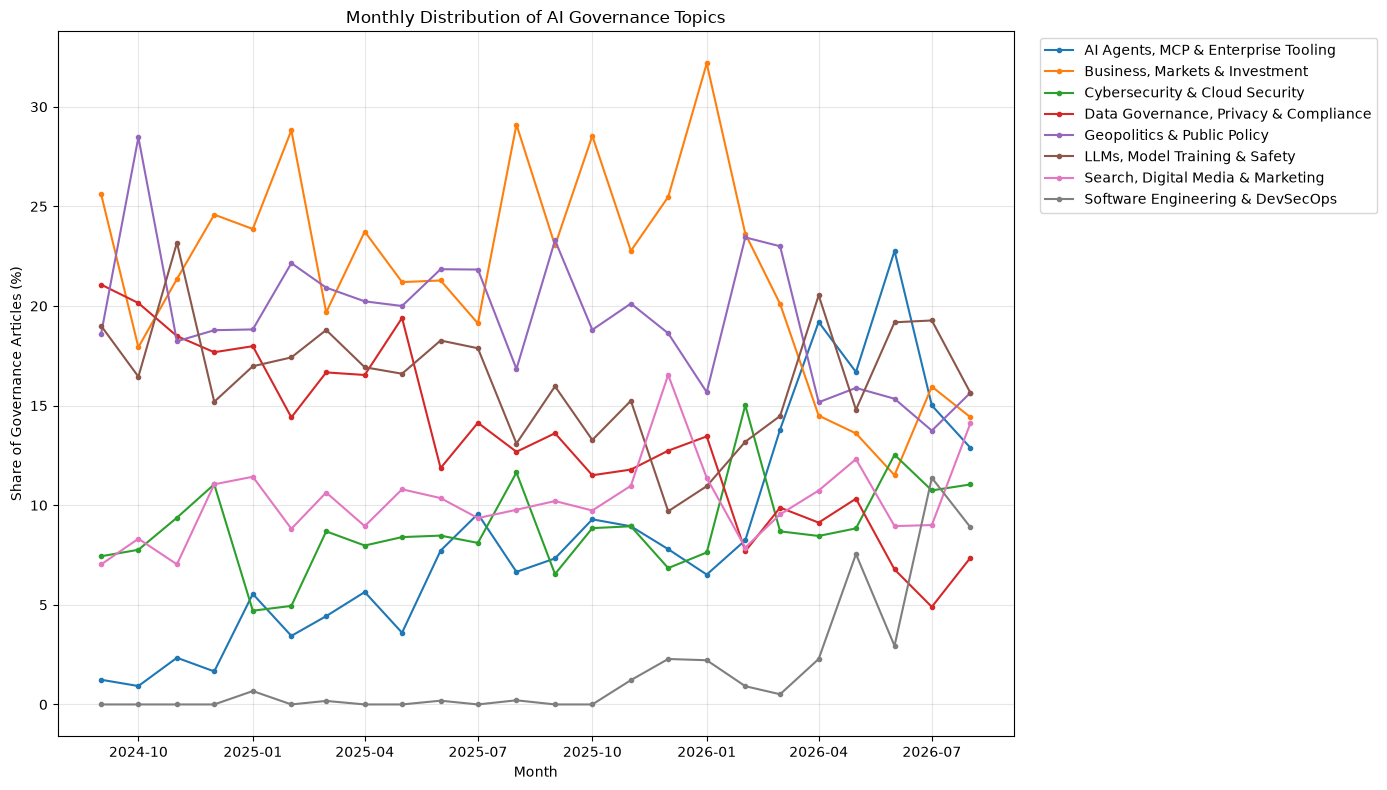

In [116]:
import matplotlib.pyplot as plt

# Restrict temporal analysis to the official Stage 1 period
topic_time_df = governance_df[
    (governance_df["date"] >= "2024-09-01")
    & (governance_df["date"] <= "2026-08-31")
].copy()

# Create monthly time variable
topic_time_df["month"] = (
    pd.to_datetime(topic_time_df["date"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Count articles per topic and month
monthly_topic_counts = (
    topic_time_df
    .groupby(
        ["month", "dominant_topic_label"]
    )
    .size()
    .unstack(fill_value=0)
)

# Convert counts to monthly percentages
monthly_topic_share = (
    monthly_topic_counts
    .div(
        monthly_topic_counts.sum(axis=1),
        axis=0
    )
    * 100
)

# Plot monthly topic shares
plt.figure(figsize=(14, 8))

for topic in monthly_topic_share.columns:

    plt.plot(
        monthly_topic_share.index,
        monthly_topic_share[topic],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=topic
    )

plt.title(
    "Monthly Distribution of AI Governance Topics"
)

plt.xlabel("Month")
plt.ylabel("Share of Governance Articles (%)")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.tight_layout()
save_figure("topics_monthly_share")
plt.show()

In [117]:
first_three_months = (
    monthly_topic_share
    .iloc[:3]
    .mean()
)

last_three_months = (
    monthly_topic_share
    .iloc[-3:]
    .mean()
)

topic_trend_summary = pd.DataFrame({
    "First 3 Months (%)": first_three_months,
    "Last 3 Months (%)": last_three_months,
    "Change (pp)": (
        last_three_months
        - first_three_months
    )
}).round(2)

topic_trend_summary = (
    topic_trend_summary
    .sort_values(
        "Change (pp)",
        ascending=False
    )
)

display(topic_trend_summary)

,First 3 Months (%),Last 3 Months (%),Change (pp)
dominant_topic_label,,,
"AI Agents, MCP & Enterprise Tooling",1.50,16.88,15.38
Software Engineering & DevSecOps,0.00,7.74,7.74
Cybersecurity & Cloud Security,8.19,11.44,3.25
"Search, Digital Media & Marketing",7.46,10.69,3.23
"LLMs, Model Training & Safety",19.55,18.03,-1.51
Geopolitics & Public Policy,21.76,14.91,-6.85
"Business, Markets & Investment",21.63,13.96,-7.67
"Data Governance, Privacy & Compliance",19.90,6.35,-13.56


#### Topic Trend Findings

The topic composition changes substantially over the observation period from September 2024 to August 2026.

The strongest increase is observed for **AI Agents, MCP & Enterprise Tooling**, whose average share rises from 1.50% during the first three months to 16.88% during the final three months, an increase of 15.38 percentage points. **Software Engineering & DevSecOps** also becomes more prominent (from 0.00% to 7.74%), and **Cybersecurity & Cloud Security** (8.19% → 11.44%) and **Search, Digital Media & Marketing** (7.46% → 10.69%) increase moderately.

The strongest decline is observed for **Data Governance, Privacy & Compliance**, whose share falls from 19.90% to 6.35% (−13.56 percentage points). **Business, Markets & Investment** (21.63% → 13.96%) and **Geopolitics & Public Policy** (21.76% → 14.91%) also decline, while **LLMs, Model Training & Safety** remains comparatively stable (19.55% → 18.03%).

Overall, the topic model suggests a shift in AI Governance coverage from data protection, business and policy discussions toward deployment-oriented themes – AI agents, MCP, enterprise tooling and the security of these systems – during 2026.

These changes describe relative topic prevalence within the Governance corpus and should not be interpreted as absolute changes in publication volume.

### Sentiment and Stance Analysis

Sentiment and stance analysis were considered but not applied as a primary analytical method in this stage.

The AI Governance corpus contains a heterogeneous mixture of technical, regulatory, business, policy and news content. General-purpose sentiment scores would therefore be difficult to interpret consistently: for example, discussion of security risks, regulation or model limitations may contain negative terminology without representing a negative stance toward AI itself.

Because the project brief specifies sentiment or stance analysis where meaningful, the analysis instead focuses on temporal topic prevalence, Governance-theme distributions, entity relationships and Knowledge Graph structure, which provide more directly interpretable signals for this topic track.

### Topic Model Outputs

The final topic model, document-level topic assignments, topic keywords and monthly topic distributions are stored as reusable Stage 1 artifacts. This allows the topic structure to be inspected or reused without refitting the model.

In [118]:
import joblib

# ---------------------------------------------------------
# Create final topic keyword table
# ---------------------------------------------------------

final_topic_keywords = []

for topic_idx, topic_weights in enumerate(topic_term_matrix):

    top_indices = topic_weights.argsort()[-TOP_WORDS:][::-1]

    top_terms = [
        feature_names[index]
        for index in top_indices
    ]

    final_topic_keywords.append({
        "Topic": topic_idx + 1,
        "Topic Label": topic_labels[topic_idx + 1],
        "Top Terms": ", ".join(top_terms)
    })

final_topic_keywords_df = pd.DataFrame(
    final_topic_keywords
)

# ---------------------------------------------------------
# Document-level topic assignments
# ---------------------------------------------------------

topic_assignments = governance_df[
    [
        "record_id",
        "date",
        "domain",
        "dominant_topic",
        "dominant_topic_label"
    ]
].copy()

topic_assignments["dominant_topic_weight"] = (
    document_topic_matrix.max(axis=1)
)

# ---------------------------------------------------------
# Save outputs
# ---------------------------------------------------------

TOPIC_KEYWORDS_PATH = (
    TOPICS_DIR / "ai_governance_topic_keywords.csv"
)

TOPIC_ASSIGNMENTS_PATH = (
    TOPICS_DIR / "ai_governance_topic_assignments.csv"
)

TOPIC_TRENDS_PATH = (
    TOPICS_DIR / "ai_governance_monthly_topic_shares.csv"
)

NMF_MODEL_PATH = (
    MODELS_DIR / "ai_governance_nmf_model.joblib"
)

TFIDF_VECTORIZER_PATH = (
    MODELS_DIR / "ai_governance_tfidf_vectorizer.joblib"
)

final_topic_keywords_df.to_csv(
    TOPIC_KEYWORDS_PATH,
    index=False
)

topic_assignments.to_csv(
    TOPIC_ASSIGNMENTS_PATH,
    index=False
)

monthly_topic_share.to_csv(
    TOPIC_TRENDS_PATH
)

joblib.dump(
    nmf_model,
    NMF_MODEL_PATH
)

joblib.dump(
    tfidf_vectorizer,
    TFIDF_VECTORIZER_PATH
)

print(f"Topic keywords saved to: {TOPIC_KEYWORDS_PATH}")
print(f"Topic assignments saved to: {TOPIC_ASSIGNMENTS_PATH}")
print(f"Monthly topic trends saved to: {TOPIC_TRENDS_PATH}")
print(f"NMF model saved to: {NMF_MODEL_PATH}")
print(f"TF-IDF vectorizer saved to: {TFIDF_VECTORIZER_PATH}")

Topic keywords saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\processed\topics\ai_governance_topic_keywords.csv
Topic assignments saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\processed\topics\ai_governance_topic_assignments.csv
Monthly topic trends saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\data\processed\topics\ai_governance_monthly_topic_shares.csv
NMF model saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\models\stage1\ai_governance_nmf_model.joblib
TF-IDF vectorizer saved to: C:\Users\Micha\OneDrive - Hochschule Luzern\Semester 3\Computational Language Technologies\ProjectCTL\outputs\models\stage1\ai_governance_tfidf_vectorizer.joblib


### Stage 1 Key Findings

The Stage 1 analysis identifies several important patterns within the AI Governance subset of the AI Media Dataset.

- After cleaning and the removal of 72 duplicate articles, **12,946 of 47,679 articles (27.2%)** were classified as relevant to AI Governance based on the curated Governance tag mapping.
- **Accountability** is the most frequently represented Governance dimension, appearing in 7,592 articles, followed by Security (4,455), Bias/Fairness (2,662) and Regulation (1,370).
- Most Governance articles focus on a single Governance dimension, while approximately **19.7%** cover two or more themes.
- Accountability-related coverage increases substantially over time and reaches its highest monthly share (24.58%) in June 2026.
- Named-entity extraction identified a highly interconnected Governance discourse centred on Artificial Intelligence, the United States, major technology organisations and geopolitical actors. Governance-specific entity patterns make laws, standards and regulators consistently identifiable (e.g. the EU AI Act in 790 articles).
- The co-occurrence Knowledge Graph contains **720 typed entity nodes and 4,282 recurring entity-to-entity relationships**. Artificial Intelligence and the United States occupy the most central structural positions.
- Structured entity-theme relations show that technology-related entities are strongly associated with Accountability, while geopolitical actors are particularly prominent in Security-related coverage.
- LLM-based relation extraction on a sample of 408 articles added **162 directed, source-linked relations** (mostly `DEVELOPS` and `REGULATES`); about three quarters of the reviewed relations were correct and fully supported by the source text.
- The NMF topic model on lemmatized text identifies eight thematic areas, ranging from business, geopolitics and data governance to LLMs, cybersecurity and AI agents.
- Topic prevalence changes noticeably over time: **AI Agents, MCP & Enterprise Tooling** increases from 1.50% in the first three months to 16.88% in the final three months, while **Data Governance, Privacy & Compliance** declines from 19.90% to 6.35%.
- Overall, the corpus suggests a shift from data protection, business and policy discussions toward more operational and deployment-oriented AI Governance topics during 2026.

### Limitations

Several limitations should be considered when interpreting the results.

First, Governance relevance is determined using a curated mapping of dataset tags. Although all available tags were reviewed, the classification depends on the quality and consistency of the original tagging and may exclude Governance-relevant articles whose tags do not explicitly represent the selected dimensions.

Second, named-entity recognition is based on a pretrained general-purpose spaCy model. Entity labels therefore contain some ambiguity, particularly for technical terms, abbreviations and names that can represent multiple entity types. Conservative normalization was applied to frequent and clearly identifiable cases rather than aggressively merging uncertain entities. The Governance EntityRuler maps *AI Act* to the EU AI Act; possessive forms of other acts (e.g. *Colorado's AI Act*) can therefore occasionally be assigned to the EU AI Act.

Third, the co-occurrence edges of the Knowledge Graph represent article-level co-occurrence and thematic association. They indicate that entities are discussed together but do not demonstrate causal, directional or semantic relationships. The LLM-extracted relations add semantic, directed relations, but they cover only a sample of 408 articles and only the beginning of each article, about one in eight reviewed relations was incorrect, and one article was rejected by the model's safety filter.

Fourth, NMF topics are statistical patterns derived from term distributions. Topic labels were assigned based on the highest-weighted terms, and some topics contain broader or source-specific vocabulary. Lemmatization relies on spaCy's rule-based lemmatizer, which occasionally produces unexpected lemmas (e.g. *data* → *datum*, which is corrected explicitly). The topic model should therefore be interpreted as an exploratory representation of the corpus rather than a definitive taxonomy.

Finally, changes in topic share represent relative changes within the AI Governance corpus and do not necessarily indicate equivalent changes in absolute publication volume.

### Reproducibility and Reusable Outputs

All major intermediate and final outputs of the Stage 1 analysis are stored so that later stages can reuse them without repeating computationally expensive processing steps. Long-running steps (NER, lemmatization, LLM relation extraction) are cached and only recomputed when their configuration changes.

**`data/processed/corpus/`**
- `ai_media_clean.pkl.gz` – cleaned and de-duplicated full corpus with Governance theme flags (input for Stage 2).
- `governance_text_lemmatized.pkl.gz` – lemmatized text of the Governance articles.
- `AI_Governance_All_Tags_Review.xlsx` – review decision for all 1,311 tags (Governance subset definition).

**`data/processed/entities/`**
- `governance_entities_fulltext.pkl` – Governance articles with extracted named entities (NER cache).
- `governance_entities_normalized.pkl` – normalized entities per Governance article.
- `governance_cooccurrence_full.pkl` – complete entity co-occurrence results before graph filtering.
- `governance_relations_langextract.jsonl` – cached LLM responses of the relation extraction.

**`data/processed/topics/`**
- `ai_governance_topic_keywords.csv` – topic labels and representative terms.
- `ai_governance_topic_assignments.csv` – dominant topic of each Governance article.
- `ai_governance_monthly_topic_shares.csv` – monthly relative topic prevalence.

**`outputs/knowledge_graph/`** (input for Stage 3)
- `ai_governance_knowledge_graph_schema.json` – schema of all graph files.
- `ai_governance_knowledge_graph.graphml` – entities with `CO_MENTIONED_WITH` edges.
- `ai_governance_knowledge_graph_enriched.graphml` – additionally Governance themes with `ASSOCIATED_WITH_THEME` edges.
- `ai_governance_relation_graph.graphml` – LLM-extracted, directed relations with source article, date and evidence.
- `governance_graph_edges.csv`, `ai_governance_network_metrics.csv`, `ai_governance_entity_theme_relations.csv`, `ai_governance_extracted_relations.csv` – the graph contents and metrics as tables.

**`outputs/models/stage1/`** – fitted NMF model and TF-IDF vectorizer.

**`outputs/figures/stage1/`** – all figures of this notebook as PNG files.

Random seeds are fixed where applicable, and the analysis uses explicit frequency and co-occurrence thresholds to support reproducibility. Files larger than GitHub's size limit (`ai_media_clean.pkl.gz`, `governance_entities_fulltext.pkl`) are shared via the team OneDrive folder; see the project README.

### Use of AI Tools

The group used generative AI tools during Stage 1, in accordance with the project requirements:

| AI tool | Use |
|---|---|
| Claude | Development, reviews and documentation |
| Google Gemini (`gemini-3.5-flash-lite`) via LangExtract | Part of the analysis: extraction of typed relations from a sample of articles (see *LLM-Based Relation Extraction*); all outputs are grounded in and traceable to the source text |
| ChatGPT | Development support: code review, debugging, methodological discussion and documentation |

AI-generated suggestions were reviewed by the group before implementation, and analytical decisions such as the Governance tag mapping, entity normalization rules, frequency thresholds, topic-number selection and interpretation of results were validated against the dataset and project requirements.

All final analyses were executed locally on the project data, and reported numerical results originate from the executed notebook rather than directly from generative AI output.

## Contributions

### Stage 1 – AI Governance

- **Dana Srdic** created the Stage 1 analysis and its overall structure.
- **Michael Nguyen** and **Henrik Szent-Ivany** reviewed the notebook and contributed extensions and corrections.